# Nassau Candy Distributor
## Product Line Profitability & Margin Performance Analysis

### 1. Project Overview

This project analyzes product-line profitability and margin performance for Nassau Candy Distributor.

The objective is to transform raw transaction-level sales, cost, units, product, division, and time data into actionable business insights.

### 2. Business Objective

The analysis aims to identify:

- Products that generate the highest gross profit and gross margin
- High-sales products with weak profitability
- Differences in profitability across product divisions
- Products that represent potential margin risk
- The concentration of revenue and profit across the product portfolio
- Cost structures that may require pricing or cost-efficiency review

### 3. Analytical Approach

The project follows an end-to-end analytics workflow:

1. Data Understanding
2. Data Cleaning & Validation
3. Feature Engineering & KPI Calculation
4. Exploratory Data Analysis
5. Product-Level Profitability Analysis
6. Division-Level Performance Analysis
7. Pareto / Profit Concentration Analysis
8. Cost Structure & Margin Diagnostics
9. Business Risk Segmentation
10. Business Recommendations
11. Interactive Streamlit Dashboard
12. Executive Summary & Research Paper

### 4. Key Business KPIs

The analysis will calculate:

- Gross Margin (%)
- Profit per Unit
- Revenue Contribution (%)
- Profit Contribution (%)
- Margin Volatility

### 5. Expected Deliverables

- Professional analytical notebook
- Interactive Streamlit dashboard
- Research paper
- Executive summary
- Business recommendations

In [1]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings for better notebook readability
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


# ============================================================
# 2. LOAD DATASET
# ============================================================

# Load the Nassau Candy transaction dataset
df = pd.read_csv("../data/raw/Nassau Candy Distributor.csv")


# ============================================================
# 3. BASIC DATASET VERIFICATION
# ============================================================

print("Dataset loaded successfully.")
print(f"Number of rows    : {df.shape[0]:,}")
print(f"Number of columns : {df.shape[1]:,}")


# Display column names
print("\nColumn Names:")
print(df.columns.tolist())


# Display data types
print("\nData Types:")
print(df.dtypes)


# Display first 5 records
print("\nFirst 5 Records:")
display(df.head())


# Check missing values
print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Values"))


# Check duplicate rows
print(f"\nDuplicate Rows: {df.duplicated().sum():,}")

Dataset loaded successfully.
Number of rows    : 10,194
Number of columns : 18

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost']

Data Types:
Row ID              int64
Order ID              str
Order Date            str
Ship Date             str
Ship Mode             str
Customer ID         int64
Country/Region        str
City                  str
State/Province        str
Postal Code           str
Division              str
Region                str
Product ID            str
Product Name          str
Sales             float64
Units               int64
Gross Profit      float64
Cost              float64
dtype: object

First 5 Records:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90



Missing Values:


,Missing Values
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Country/Region,0
City,0
State/Province,0
Postal Code,0



Duplicate Rows: 0


## 2. Data Structure & Business Understanding

This section examines the structure, granularity, and business meaning of the dataset before performing data cleaning.

The dataset contains transaction-level information covering:

- Orders and customers
- Order and shipment dates
- Geographic information
- Product divisions and products
- Sales and units
- Cost and gross profit

The primary financial relationship expected in the dataset is:

**Gross Profit = Sales − Cost**

The purpose of this stage is to understand how the raw fields represent the business process and to identify any structural or logical issues before calculating profitability metrics.

In [2]:
# ============================================================
# 2. DATASET STRUCTURE SUMMARY
# ============================================================

# Create a compact summary of the dataset
dataset_summary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Unique Values": [df[col].nunique() for col in df.columns],
    "Missing Values": [df[col].isnull().sum() for col in df.columns]
})

display(dataset_summary)

,Column,Data Type,Unique Values,Missing Values
0,Row ID,int64,10194,0
1,Order ID,str,8549,0
2,Order Date,str,717,0
3,Ship Date,str,1338,0
4,Ship Mode,str,4,0
5,Customer ID,int64,5044,0
6,Country/Region,str,2,0
7,City,str,542,0
8,State/Province,str,59,0
9,Postal Code,str,654,0


## 3. Financial & Identifier Validation

Before cleaning or calculating new profitability metrics, the financial fields must be validated against the business rules defined in the project documentation.

The following checks will be performed:

1. Validate Row ID uniqueness
2. Validate Product ID and Product Name consistency
3. Check Order ID repetition to understand transaction granularity
4. Identify zero or negative Sales
5. Identify zero or negative Cost
6. Identify zero or negative Units
7. Validate Gross Profit against Sales − Cost
8. Identify any financially inconsistent records

These checks establish whether the raw financial data is suitable for downstream profitability analysis.

In [3]:
# ============================================================
# 3. FINANCIAL & IDENTIFIER VALIDATION
# ============================================================

# ------------------------------------------------------------
# A. Identifier Validation
# ------------------------------------------------------------

print("IDENTIFIER VALIDATION")
print("-" * 50)

print(f"Total Rows              : {len(df):,}")
print(f"Unique Row IDs          : {df['Row ID'].nunique():,}")
print(f"Duplicate Row IDs       : {df['Row ID'].duplicated().sum():,}")
print(f"Unique Order IDs        : {df['Order ID'].nunique():,}")
print(f"Unique Customer IDs     : {df['Customer ID'].nunique():,}")
print(f"Unique Product IDs      : {df['Product ID'].nunique():,}")
print(f"Unique Product Names    : {df['Product Name'].nunique():,}")


# ------------------------------------------------------------
# B. Product ID ↔ Product Name Consistency
# ------------------------------------------------------------

# Check whether one Product ID maps to multiple product names
product_id_name_check = (
    df.groupby("Product ID")["Product Name"]
      .nunique()
      .sort_values(ascending=False)
)

print("\nProduct IDs mapped to multiple Product Names:")
print((product_id_name_check > 1).sum())


# ------------------------------------------------------------
# C. Financial Value Validation
# ------------------------------------------------------------

print("\nFINANCIAL VALIDATION")
print("-" * 50)

print(f"Sales <= 0              : {(df['Sales'] <= 0).sum():,}")
print(f"Cost < 0                : {(df['Cost'] < 0).sum():,}")
print(f"Cost = 0                : {(df['Cost'] == 0).sum():,}")
print(f"Units <= 0              : {(df['Units'] <= 0).sum():,}")
print(f"Gross Profit < 0        : {(df['Gross Profit'] < 0).sum():,}")


# ------------------------------------------------------------
# D. Gross Profit Reconciliation
# ------------------------------------------------------------

# According to the project documentation:
# Gross Profit = Sales - Cost

df["Calculated Gross Profit"] = df["Sales"] - df["Cost"]

# Calculate the difference between supplied and calculated profit
df["Profit Difference"] = (
    df["Gross Profit"] - df["Calculated Gross Profit"]
)

print("\nGROSS PROFIT RECONCILIATION")
print("-" * 50)

print(
    f"Records where Gross Profit differs from Sales - Cost: "
    f"{(df['Profit Difference'].abs() > 0.01).sum():,}"
)

print(
    f"Maximum absolute difference: "
    f"{df['Profit Difference'].abs().max():,.4f}"
)


# ------------------------------------------------------------
# E. Display Financially Suspicious Records
# ------------------------------------------------------------

financial_issues = df[
    (df["Sales"] <= 0) |
    (df["Cost"] < 0) |
    (df["Units"] <= 0) |
    (df["Profit Difference"].abs() > 0.01)
]

print("\nFinancially Suspicious Records:")
print(f"Number of records: {len(financial_issues):,}")

display(
    financial_issues[
        [
            "Row ID",
            "Order ID",
            "Product ID",
            "Product Name",
            "Sales",
            "Units",
            "Gross Profit",
            "Cost",
            "Calculated Gross Profit",
            "Profit Difference"
        ]
    ].head(20)
)

IDENTIFIER VALIDATION
--------------------------------------------------
Total Rows              : 10,194
Unique Row IDs          : 10,194
Duplicate Row IDs       : 0
Unique Order IDs        : 8,549
Unique Customer IDs     : 5,044
Unique Product IDs      : 15
Unique Product Names    : 15

Product IDs mapped to multiple Product Names:
0

FINANCIAL VALIDATION
--------------------------------------------------
Sales <= 0              : 0
Cost < 0                : 0
Cost = 0                : 0
Units <= 0              : 0
Gross Profit < 0        : 0

GROSS PROFIT RECONCILIATION
--------------------------------------------------
Records where Gross Profit differs from Sales - Cost: 0
Maximum absolute difference: 0.0000

Financially Suspicious Records:
Number of records: 0


,Row ID,Order ID,Product ID,Product Name,Sales,Units,Gross Profit,Cost,Calculated Gross Profit,Profit Difference


## 4. Date Validation & Standardization

Order Date and Ship Date are currently stored as string values.

For time-based profitability analysis, these fields must be converted to proper datetime types.

This stage will:

1. Convert Order Date to datetime
2. Convert Ship Date to datetime
3. Identify invalid date values
4. Check for missing dates after conversion
5. Validate the relationship between Order Date and Ship Date
6. Establish the analysis period covered by the dataset

In [4]:
# ============================================================
# 4. DATE VALIDATION & STANDARDIZATION
# ============================================================

# Convert date columns from strings to datetime
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    errors="coerce",
    dayfirst=True
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    errors="coerce",
    dayfirst=True
)


# ------------------------------------------------------------
# A. Check for invalid dates
# ------------------------------------------------------------

print("DATE VALIDATION")
print("-" * 50)

print(f"Invalid Order Dates : {df['Order Date'].isna().sum():,}")
print(f"Invalid Ship Dates  : {df['Ship Date'].isna().sum():,}")


# ------------------------------------------------------------
# B. Check date ranges
# ------------------------------------------------------------

print("\nDATE RANGE")
print("-" * 50)

print(f"Earliest Order Date : {df['Order Date'].min().date()}")
print(f"Latest Order Date   : {df['Order Date'].max().date()}")
print(f"Earliest Ship Date  : {df['Ship Date'].min().date()}")
print(f"Latest Ship Date    : {df['Ship Date'].max().date()}")


# ------------------------------------------------------------
# C. Validate Order Date <= Ship Date
# ------------------------------------------------------------

invalid_date_sequence = df[
    df["Ship Date"] < df["Order Date"]
]

print("\nDATE SEQUENCE VALIDATION")
print("-" * 50)

print(
    f"Records where Ship Date occurs before Order Date: "
    f"{len(invalid_date_sequence):,}"
)


# ------------------------------------------------------------
# D. Create shipping duration
# ------------------------------------------------------------

df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

print("\nShipping Days Summary:")
display(df["Shipping Days"].describe())

DATE VALIDATION
--------------------------------------------------
Invalid Order Dates : 0
Invalid Ship Dates  : 0

DATE RANGE
--------------------------------------------------
Earliest Order Date : 2024-01-02
Latest Order Date   : 2025-12-31
Earliest Ship Date  : 2026-06-30
Latest Ship Date    : 2030-06-28

DATE SEQUENCE VALIDATION
--------------------------------------------------
Records where Ship Date occurs before Order Date: 0

Shipping Days Summary:


count   10,194.00
mean     1,320.84
std        262.44
min        904.00
25%      1,271.00
50%      1,274.00
75%      1,638.00
max      1,642.00
Name: Shipping Days, dtype: float64

## 5. Date Anomaly Investigation

The date validation identified no technically invalid dates or records where Ship Date precedes Order Date.

However, the calculated shipping duration is unusually large, with an average of approximately 1,321 days.

Before using shipping duration or Ship Date in any business analysis, the date relationship must therefore be investigated.

This analysis will examine:

- The most common Order Date values
- The most common Ship Date values
- The distribution of Shipping Days
- Whether the large shipping intervals are systematic
- Whether the date fields appear suitable for operational shipping analysis

No date values will be modified unless a clear data-quality rule is established.

In [5]:
# ============================================================
# 5. DATE ANOMALY INVESTIGATION
# ============================================================

# ------------------------------------------------------------
# A. Inspect representative records
# ------------------------------------------------------------

print("SAMPLE DATE RELATIONSHIPS")
print("-" * 50)

display(
    df[
        [
            "Order ID",
            "Order Date",
            "Ship Date",
            "Shipping Days"
        ]
    ].head(15)
)


# ------------------------------------------------------------
# B. Shipping duration distribution
# ------------------------------------------------------------

print("\nSHIPPING DAYS DISTRIBUTION")
print("-" * 50)

display(
    df["Shipping Days"]
    .value_counts()
    .sort_index()
    .head(20)
)


# ------------------------------------------------------------
# C. Common Order Dates
# ------------------------------------------------------------

print("\nMOST COMMON ORDER DATES")
print("-" * 50)

display(
    df["Order Date"]
    .value_counts()
    .head(10)
)


# ------------------------------------------------------------
# D. Common Ship Dates
# ------------------------------------------------------------

print("\nMOST COMMON SHIP DATES")
print("-" * 50)

display(
    df["Ship Date"]
    .value_counts()
    .head(10)
)


# ------------------------------------------------------------
# E. Shipping duration percentiles
# ------------------------------------------------------------

print("\nSHIPPING DAYS PERCENTILES")
print("-" * 50)

display(
    df["Shipping Days"]
    .quantile([0, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.00])
    .to_frame("Shipping Days")
)

SAMPLE DATE RELATIONSHIPS
--------------------------------------------------


,Order ID,Order Date,Ship Date,Shipping Days
0,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,909
1,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,909
2,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,909
3,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,909
4,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,912
5,US-2021-167199-CHO-SCR-58000,2024-01-06,2026-07-03,909
6,US-2021-167199-CHO-TRI-54000,2024-01-06,2026-07-03,909
7,US-2021-106054-CHO-MIL-31000,2024-01-06,2026-06-30,906
8,US-2021-167199-CHO-NUT-13000,2024-01-06,2026-07-03,909
9,US-2021-167199-CHO-MIL-31000,2024-01-06,2026-07-03,909



SHIPPING DAYS DISTRIBUTION
--------------------------------------------------


Shipping Days
904       89
905       40
906      289
907      176
908      591
909      519
910      207
911      134
912        4
915        2
1269     258
1270     156
1271     610
1272     456
1273    1326
1274    1035
1275     612
1276     293
1277      18
1634       3
Name: count, dtype: int64


MOST COMMON ORDER DATES
--------------------------------------------------


Order Date
2025-09-02    62
2025-12-01    57
2025-12-02    57
2025-12-09    54
2025-11-24    52
2025-11-10    50
2025-12-11    50
2025-11-03    47
2025-09-04    46
2025-11-12    46
Name: count, dtype: int64


MOST COMMON SHIP DATES
--------------------------------------------------


Ship Date
2028-06-07    38
2030-05-29    35
2030-03-19    34
2030-05-14    32
2030-02-27    30
2030-03-08    30
2030-06-04    30
2027-03-06    28
2030-03-01    27
2030-05-11    27
Name: count, dtype: int64


SHIPPING DAYS PERCENTILES
--------------------------------------------------


,Shipping Days
0.00,904.00
0.10,908.00
0.25,"1,271.00"
0.50,"1,274.00"
0.75,"1,638.00"
0.90,"1,640.00"
0.95,"1,641.00"
0.99,"1,642.00"
1.00,"1,642.00"


## 5.1 Date Quality Decision

The date investigation identified a systematic issue with the `Ship Date` field.

Although all Ship Date values are technically valid dates and none occur before their corresponding Order Date, the calculated shipping durations range from approximately 904 to 1,642 days. The Ship Date values also extend from 2026 through 2030, while Order Date values end in 2025.

Because the technical documentation does not provide a rule for correcting these dates, the original Ship Date values will not be modified.

### Analytical Decision

- `Order Date` will be retained and used for time-based profitability analysis.
- `Ship Date` will be retained as an original source field.
- `Shipping Days` will not be used as a business KPI.
- No unsupported date correction will be applied.

This prevents the analysis from introducing assumptions that are not supported by the source data or project specification.

In [6]:
# Remove temporary validation/diagnostic columns
df.drop(
    columns=[
        "Calculated Gross Profit",
        "Profit Difference",
        "Shipping Days"
    ],
    inplace=True
)

print("Temporary validation columns removed.")
print(f"Current dataset shape: {df.shape}")

Temporary validation columns removed.
Current dataset shape: (10194, 18)


## 6. Categorical Data & Label Consistency Validation

This stage validates the categorical dimensions used in the profitability analysis.

The following fields will be examined:

- Product ID
- Product Name
- Division
- Region
- Ship Mode
- Country/Region
- State/Province

The objective is to identify inconsistent labels, unexpected whitespace, and one-to-many mappings that could distort product- or division-level aggregation.

No categorical values will be modified until the validation results have been reviewed.

In [7]:
# ============================================================
# 6. CATEGORICAL DATA & LABEL CONSISTENCY VALIDATION
# ============================================================

categorical_columns = [
    "Product ID",
    "Product Name",
    "Division",
    "Region",
    "Ship Mode",
    "Country/Region",
    "State/Province"
]

# ------------------------------------------------------------
# A. Display unique values
# ------------------------------------------------------------

for column in categorical_columns:
    print(f"\n{column}")
    print("-" * 50)
    print(df[column].unique())


# ------------------------------------------------------------
# B. Check leading/trailing whitespace
# ------------------------------------------------------------

print("\nWHITESPACE VALIDATION")
print("-" * 50)

for column in categorical_columns:
    whitespace_count = (
        df[column].astype(str) != df[column].astype(str).str.strip()
    ).sum()

    print(f"{column:<20}: {whitespace_count:,} records")


# ------------------------------------------------------------
# C. Product ID → Product Name mapping
# ------------------------------------------------------------

print("\nPRODUCT ID → PRODUCT NAME MAPPING")
print("-" * 50)

product_mapping = (
    df.groupby("Product ID")["Product Name"]
      .nunique()
      .sort_values(ascending=False)
)

print(
    f"Product IDs mapped to multiple names: "
    f"{(product_mapping > 1).sum():,}"
)


# ------------------------------------------------------------
# D. Product ID → Division mapping
# ------------------------------------------------------------

print("\nPRODUCT ID → DIVISION MAPPING")
print("-" * 50)

product_division_mapping = (
    df.groupby("Product ID")["Division"]
      .nunique()
      .sort_values(ascending=False)
)

print(
    f"Product IDs mapped to multiple divisions: "
    f"{(product_division_mapping > 1).sum():,}"
)


# ------------------------------------------------------------
# E. Product Name → Division mapping
# ------------------------------------------------------------

print("\nPRODUCT NAME → DIVISION MAPPING")
print("-" * 50)

product_name_division_mapping = (
    df.groupby("Product Name")["Division"]
      .nunique()
      .sort_values(ascending=False)
)

print(
    f"Product Names mapped to multiple divisions: "
    f"{(product_name_division_mapping > 1).sum():,}"
)



Product ID
--------------------------------------------------
<ArrowStringArray>
['CHO-MIL-31000', 'CHO-TRI-54000', 'CHO-NUT-13000', 'CHO-SCR-58000',
 'CHO-FUD-51000', 'OTH-GUM-21000', 'OTH-KAZ-38000', 'OTH-LIC-15000',
 'OTH-FIZ-56000', 'SUG-LAF-25000', 'SUG-SWE-91000', 'SUG-NER-92000',
 'SUG-HAI-55000', 'SUG-EVE-47000', 'SUG-FUN-75000']
Length: 15, dtype: str

Product Name
--------------------------------------------------
<ArrowStringArray>
[       'Wonka Bar - Milk Chocolate', 'Wonka Bar - Triple Dazzle Caramel',
 'Wonka Bar - Nutty Crunch Surprise',    'Wonka Bar -Scrumdiddlyumptious',
         'Wonka Bar - Fudge Mallows',                         'Wonka Gum',
                         'Kazookles',                'Lickable Wallpaper',
              'Fizzy Lifting Drinks',                       'Laffy Taffy',
                         'SweeTARTS',                             'Nerds',
                       'Hair Toffee',            'Everlasting Gobstopper',
                           

## 7. Data Quality Assessment

The initial data-quality assessment has been completed across structural, financial, date, and categorical dimensions.

### Validation Results

- No duplicate transaction rows were identified.
- Row IDs are unique.
- Product IDs and Product Names have consistent one-to-one mappings.
- No missing values were identified.
- No zero or negative Sales values were identified.
- No negative or zero Cost values were identified.
- No zero or negative Units values were identified.
- Gross Profit reconciles exactly with Sales − Cost.
- No invalid Order Date or Ship Date values were identified.
- No Ship Date occurs before its corresponding Order Date.
- No leading or trailing whitespace was detected in key categorical fields.
- Product, Division, and Product Name mappings are consistent.

### Date Field Limitation

The Ship Date field produces unusually long shipping intervals and extends several years beyond the Order Date period. Because the technical documentation does not provide a correction rule, Ship Date will be retained as source data but will not be used to derive a shipping-duration KPI.

### Overall Assessment

The financial and categorical data is suitable for profitability analysis.

The analysis will therefore proceed using the validated Sales, Units, Cost, Gross Profit, Product, Division, Region, Customer, and Order Date fields.

In [8]:
# ============================================================
# 8. CREATE CLEAN ANALYTICAL DATASET
# ============================================================

# Create a separate copy after completing data-quality validation.
# The original df remains available as the validated source dataset.
df_clean = df.copy()

print("Clean analytical dataset created.")
print(f"Rows    : {df_clean.shape[0]:,}")
print(f"Columns : {df_clean.shape[1]:,}")

display(df_clean.head())

Clean analytical dataset created.
Rows    : 10,194
Columns : 18


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


## 9. KPI & Feature Engineering

After completing data-quality validation, the next stage is to derive analytical financial metrics from the validated dataset.

The first set of metrics will be calculated at the transaction level:

### Gross Margin (%)

Gross Margin measures the proportion of Sales retained as Gross Profit.

**Formula:**

Gross Margin (%) = Gross Profit ÷ Sales × 100

### Profit per Unit

Profit per Unit measures the gross profit generated from each unit sold.

**Formula:**

Profit per Unit = Gross Profit ÷ Units

These metrics will form the foundation for subsequent product-level, division-level, and margin-risk analysis.

Revenue Contribution, Profit Contribution, and Margin Volatility will be calculated at the appropriate aggregation level in later analytical stages.

In [9]:
# ============================================================
# 9. ROW-LEVEL PROFITABILITY KPI CALCULATION
# ============================================================

# Gross Margin:
# Measures the percentage of sales retained as gross profit.
df_clean["Gross Margin (%)"] = (
    df_clean["Gross Profit"] / df_clean["Sales"]
) * 100


# Profit per Unit:
# Measures the gross profit generated by each unit sold.
df_clean["Profit per Unit"] = (
    df_clean["Gross Profit"] / df_clean["Units"]
)


# ------------------------------------------------------------
# Validate the newly created metrics
# ------------------------------------------------------------

print("KPI calculation completed.")
print(f"Total rows: {len(df_clean):,}")

print("\nNew columns:")
print([
    "Gross Margin (%)",
    "Profit per Unit"
])


# Display the relevant financial metrics
display(
    df_clean[
        [
            "Product ID",
            "Product Name",
            "Sales",
            "Units",
            "Cost",
            "Gross Profit",
            "Gross Margin (%)",
            "Profit per Unit"
        ]
    ].head(10)
)

KPI calculation completed.
Total rows: 10,194

New columns:
['Gross Margin (%)', 'Profit per Unit']


,Product ID,Product Name,Sales,Units,Cost,Gross Profit,Gross Margin (%),Profit per Unit
0,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,2.28,4.22,64.92,2.11
1,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,2.60,4.90,65.33,2.45
2,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,3.00,7.47,71.35,2.49
3,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,3.30,7.50,69.44,2.50
4,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,3.90,7.35,65.33,2.45
5,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,32.40,9,9.90,22.50,69.44,2.50
6,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,2.60,4.90,65.33,2.45
7,CHO-MIL-31000,Wonka Bar - Milk Chocolate,9.75,3,3.42,6.33,64.92,2.11
8,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,6.98,2,2.00,4.98,71.35,2.49
9,CHO-MIL-31000,Wonka Bar - Milk Chocolate,13.00,4,4.56,8.44,64.92,2.11


## 10. KPI Validation

The newly created profitability metrics are validated for missing, infinite, or otherwise invalid values before they are used in aggregation and analytical segmentation.

The validation ensures that:

- Gross Margin (%) contains no missing or infinite values.
- Profit per Unit contains no missing or infinite values.
- Gross Margin (%) remains within a reasonable range for the validated dataset.
- Profit per Unit contains valid numerical values.

In [10]:
# ============================================================
# 10. KPI VALIDATION
# ============================================================

import numpy as np

# Check for missing values
gross_margin_missing = df_clean["Gross Margin (%)"].isna().sum()
profit_per_unit_missing = df_clean["Profit per Unit"].isna().sum()

# Check for infinite values
gross_margin_infinite = np.isinf(df_clean["Gross Margin (%)"]).sum()
profit_per_unit_infinite = np.isinf(df_clean["Profit per Unit"]).sum()

# Calculate basic ranges
gross_margin_min = df_clean["Gross Margin (%)"].min()
gross_margin_max = df_clean["Gross Margin (%)"].max()

profit_per_unit_min = df_clean["Profit per Unit"].min()
profit_per_unit_max = df_clean["Profit per Unit"].max()

# ------------------------------------------------------------
# Display validation results
# ------------------------------------------------------------

print("KPI Validation Results")
print("=" * 50)

print(f"Gross Margin - Missing values : {gross_margin_missing}")
print(f"Gross Margin - Infinite values: {gross_margin_infinite}")
print(f"Gross Margin - Minimum        : {gross_margin_min:.2f}%")
print(f"Gross Margin - Maximum        : {gross_margin_max:.2f}%")

print()

print(f"Profit per Unit - Missing     : {profit_per_unit_missing}")
print(f"Profit per Unit - Infinite    : {profit_per_unit_infinite}")
print(f"Profit per Unit - Minimum     : {profit_per_unit_min:.2f}")
print(f"Profit per Unit - Maximum     : {profit_per_unit_max:.2f}")

# ------------------------------------------------------------
# Final validation status
# ------------------------------------------------------------

if (
    gross_margin_missing == 0
    and profit_per_unit_missing == 0
    and gross_margin_infinite == 0
    and profit_per_unit_infinite == 0
):
    print("\n✔ KPI validation passed.")
else:
    print("\n⚠ KPI validation requires investigation.")

KPI Validation Results
Gross Margin - Missing values : 0
Gross Margin - Infinite values: 0
Gross Margin - Minimum        : 7.69%
Gross Margin - Maximum        : 80.00%

Profit per Unit - Missing     : 0
Profit per Unit - Infinite    : 0
Profit per Unit - Minimum     : 0.25
Profit per Unit - Maximum     : 10.00

✔ KPI validation passed.


## 11. Product-Level Profitability Aggregation

The next step is to aggregate transaction-level data to the product level.

This analysis will evaluate each product using:

- Total Sales
- Total Units Sold
- Total Cost
- Total Gross Profit
- Gross Margin (%)
- Profit per Unit
- Revenue Contribution (%)
- Profit Contribution (%)

Gross Margin at the product level will be calculated using aggregated Sales and Gross Profit rather than averaging transaction-level margins. This produces a sales-weighted profitability measure.

Revenue Contribution and Profit Contribution will measure each product's share of the company's total revenue and total gross profit.

These metrics will provide the foundation for product profitability ranking, segmentation, and Pareto analysis.

In [11]:
# ============================================================
# 11. PRODUCT-LEVEL PROFITABILITY AGGREGATION
# ============================================================

# Aggregate financial and operational metrics by product.
product_analysis = (
    df_clean
    .groupby(
        ["Product ID", "Product Name"],
        as_index=False
    )
    .agg(
        Sales=("Sales", "sum"),
        Units=("Units", "sum"),
        Cost=("Cost", "sum"),
        Gross_Profit=("Gross Profit", "sum")
    )
)

# ------------------------------------------------------------
# Calculate product-level profitability metrics
# ------------------------------------------------------------

# Gross Margin:
# Calculated from aggregated Sales and Gross Profit.
product_analysis["Gross Margin (%)"] = (
    product_analysis["Gross_Profit"]
    / product_analysis["Sales"]
) * 100

# Profit per Unit:
# Total gross profit generated per unit sold.
product_analysis["Profit per Unit"] = (
    product_analysis["Gross_Profit"]
    / product_analysis["Units"]
)

# ------------------------------------------------------------
# Calculate company-level totals for contribution metrics
# ------------------------------------------------------------

total_sales = product_analysis["Sales"].sum()
total_profit = product_analysis["Gross_Profit"].sum()

# Revenue Contribution:
# Percentage of total company sales generated by each product.
product_analysis["Revenue Contribution (%)"] = (
    product_analysis["Sales"] / total_sales
) * 100

# Profit Contribution:
# Percentage of total company gross profit generated by each product.
product_analysis["Profit Contribution (%)"] = (
    product_analysis["Gross_Profit"] / total_profit
) * 100

# ------------------------------------------------------------
# Sort products by Gross Profit
# ------------------------------------------------------------

product_analysis = product_analysis.sort_values(
    "Gross_Profit",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# Display product-level analysis
# ------------------------------------------------------------

print("Product-level profitability analysis completed.")
print(f"Products analyzed: {len(product_analysis)}")

display(
    product_analysis[
        [
            "Product ID",
            "Product Name",
            "Sales",
            "Units",
            "Cost",
            "Gross_Profit",
            "Gross Margin (%)",
            "Profit per Unit",
            "Revenue Contribution (%)",
            "Profit Contribution (%)"
        ]
    ]
)

Product-level profitability analysis completed.
Products analyzed: 15


,Product ID,Product Name,Sales,Units,Cost,Gross_Profit,Gross Margin (%),Profit per Unit,Revenue Contribution (%),Profit Contribution (%)
0,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,"27,874.80",7743,"8,517.30","19,357.50",69.44,2.50,19.66,20.72
1,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,"28,485.00",7596,"9,874.80","18,610.20",65.33,2.45,20.09,19.92
2,CHO-MIL-31000,Wonka Bar - Milk Chocolate,"26,867.75",8267,"9,424.38","17,443.37",64.92,2.11,18.95,18.67
3,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,"23,574.95",6755,"6,755.00","16,819.95",71.35,2.49,16.63,18.00
4,CHO-FUD-51000,Wonka Bar - Fudge Mallows,"24,890.40",6914,"8,296.80","16,593.60",66.67,2.40,17.56,17.76
5,OTH-LIC-15000,Lickable Wallpaper,"7,860.00",393,"3,930.00","3,930.00",50.00,10.00,5.54,4.21
6,OTH-GUM-21000,Wonka Gum,597.50,478,286.80,310.70,52.00,0.65,0.42,0.33
7,SUG-EVE-47000,Everlasting Gobstopper,130.00,13,26.00,104.00,80.00,8.00,0.09,0.11
8,OTH-KAZ-38000,Kazookles,"1,205.75",371,"1,113.00",92.75,7.69,0.25,0.85,0.10
9,SUG-HAI-55000,Hair Toffee,76.50,17,17.00,59.50,77.78,3.50,0.05,0.06


## 12. Product-Level Aggregation Validation

Before proceeding to product rankings and profitability segmentation, the aggregated product dataset is validated against the original transaction-level dataset.

The validation confirms that:

- The number of products is correct.
- Total Sales are preserved after aggregation.
- Total Units are preserved after aggregation.
- Total Cost is preserved after aggregation.
- Total Gross Profit is preserved after aggregation.
- Revenue Contribution sums to approximately 100%.
- Profit Contribution sums to approximately 100%.

This ensures that no financial information was lost or duplicated during product-level aggregation.

In [12]:
# ============================================================
# 12. PRODUCT-LEVEL AGGREGATION VALIDATION
# ============================================================

# ------------------------------------------------------------
# Calculate totals from the original analytical dataset
# ------------------------------------------------------------

original_sales = df_clean["Sales"].sum()
original_units = df_clean["Units"].sum()
original_cost = df_clean["Cost"].sum()
original_profit = df_clean["Gross Profit"].sum()

# ------------------------------------------------------------
# Calculate totals from the product-level dataset
# ------------------------------------------------------------

product_sales = product_analysis["Sales"].sum()
product_units = product_analysis["Units"].sum()
product_cost = product_analysis["Cost"].sum()
product_profit = product_analysis["Gross_Profit"].sum()

# ------------------------------------------------------------
# Calculate contribution totals
# ------------------------------------------------------------

revenue_contribution_total = (
    product_analysis["Revenue Contribution (%)"].sum()
)

profit_contribution_total = (
    product_analysis["Profit Contribution (%)"].sum()
)

# ------------------------------------------------------------
# Display validation results
# ------------------------------------------------------------

print("Product-Level Aggregation Validation")
print("=" * 55)

print(f"Number of products              : {len(product_analysis)}")

print("\nOriginal vs Product-Level Totals")
print("-" * 55)

print(
    f"Sales       : {original_sales:,.2f} "
    f"| {product_sales:,.2f}"
)

print(
    f"Units       : {original_units:,} "
    f"| {product_units:,}"
)

print(
    f"Cost        : {original_cost:,.2f} "
    f"| {product_cost:,.2f}"
)

print(
    f"Gross Profit: {original_profit:,.2f} "
    f"| {product_profit:,.2f}"
)

print("\nContribution Validation")
print("-" * 55)

print(
    f"Revenue Contribution Total: "
    f"{revenue_contribution_total:.2f}%"
)

print(
    f"Profit Contribution Total : "
    f"{profit_contribution_total:.2f}%"
)

# ------------------------------------------------------------
# Automated validation
# ------------------------------------------------------------

validation_passed = (
    len(product_analysis) == 15
    and np.isclose(original_sales, product_sales)
    and np.isclose(original_units, product_units)
    and np.isclose(original_cost, product_cost)
    and np.isclose(original_profit, product_profit)
    and np.isclose(revenue_contribution_total, 100)
    and np.isclose(profit_contribution_total, 100)
)

if validation_passed:
    print("\n✔ Product-level aggregation validation passed.")
else:
    print("\n⚠ Product-level aggregation requires investigation.")

Product-Level Aggregation Validation
Number of products              : 15

Original vs Product-Level Totals
-------------------------------------------------------
Sales       : 141,783.63 | 141,783.63
Units       : 38,654 | 38,654
Cost        : 48,340.83 | 48,340.83
Gross Profit: 93,442.80 | 93,442.80

Contribution Validation
-------------------------------------------------------
Revenue Contribution Total: 100.00%
Profit Contribution Total : 100.00%

✔ Product-level aggregation validation passed.


## 13. Product Profitability Ranking

The next analysis ranks products across multiple profitability dimensions.

Products will be ranked separately by:

1. Total Sales
2. Total Gross Profit
3. Gross Margin (%)
4. Profit per Unit

Using multiple ranking dimensions prevents sales volume from being treated as the only indicator of product performance.

A product may generate high revenue but have a relatively lower margin, while another product may generate less revenue but produce stronger profitability per unit.

These rankings will be used later for product segmentation and profitability diagnostics.

In [13]:
# ============================================================
# 13. PRODUCT PROFITABILITY RANKING
# ============================================================

# Create independent rankings for each major KPI.
product_analysis["Sales Rank"] = (
    product_analysis["Sales"]
    .rank(method="min", ascending=False)
    .astype(int)
)

product_analysis["Gross Profit Rank"] = (
    product_analysis["Gross_Profit"]
    .rank(method="min", ascending=False)
    .astype(int)
)

product_analysis["Gross Margin Rank"] = (
    product_analysis["Gross Margin (%)"]
    .rank(method="min", ascending=False)
    .astype(int)
)

product_analysis["Profit per Unit Rank"] = (
    product_analysis["Profit per Unit"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# ------------------------------------------------------------
# Display ranking table
# ------------------------------------------------------------

ranking_columns = [
    "Product ID",
    "Product Name",
    "Sales",
    "Sales Rank",
    "Gross_Profit",
    "Gross Profit Rank",
    "Gross Margin (%)",
    "Gross Margin Rank",
    "Profit per Unit",
    "Profit per Unit Rank"
]

display(
    product_analysis[
        ranking_columns
    ]
    .sort_values("Gross Profit Rank")
    .reset_index(drop=True)
)

print("\n✔ Product profitability rankings calculated.")

,Product ID,Product Name,Sales,Sales Rank,Gross_Profit,Gross Profit Rank,Gross Margin (%),Gross Margin Rank,Profit per Unit,Profit per Unit Rank
0,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,"27,874.80",2,"19,357.50",1,69.44,4,2.50,4
1,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,"28,485.00",1,"18,610.20",2,65.33,6,2.45,6
2,CHO-MIL-31000,Wonka Bar - Milk Chocolate,"26,867.75",3,"17,443.37",3,64.92,7,2.11,9
3,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,"23,574.95",5,"16,819.95",4,71.35,3,2.49,5
4,CHO-FUD-51000,Wonka Bar - Fudge Mallows,"24,890.40",4,"16,593.60",5,66.67,5,2.40,7
5,OTH-LIC-15000,Lickable Wallpaper,"7,860.00",6,"3,930.00",6,50.00,11,10.00,1
6,OTH-GUM-21000,Wonka Gum,597.50,8,310.70,7,52.00,10,0.65,13
7,SUG-EVE-47000,Everlasting Gobstopper,130.00,9,104.00,8,80.00,1,8.00,2
8,OTH-KAZ-38000,Kazookles,"1,205.75",7,92.75,9,7.69,15,0.25,15
9,SUG-HAI-55000,Hair Toffee,76.50,11,59.50,10,77.78,2,3.50,3



✔ Product profitability rankings calculated.


## 14. Ranking Validation

The product rankings are validated to ensure that each ranking contains all positions from 1 through 15 without missing or duplicated rank positions.

Because each KPI represents a different business dimension, the rankings are intentionally kept separate rather than combined into a single overall score.

In [14]:
# ============================================================
# 14. PRODUCT RANKING VALIDATION
# ============================================================

ranking_columns = [
    "Sales Rank",
    "Gross Profit Rank",
    "Gross Margin Rank",
    "Profit per Unit Rank"
]

print("Product Ranking Validation")
print("=" * 55)

ranking_validation_passed = True

for column in ranking_columns:

    unique_ranks = sorted(product_analysis[column].unique())

    expected_ranks = list(range(1, len(product_analysis) + 1))

    is_valid = unique_ranks == expected_ranks

    print(f"{column:<25}: {unique_ranks}")

    if not is_valid:
        ranking_validation_passed = False

if ranking_validation_passed:
    print("\n✔ Ranking validation passed.")
else:
    print("\n⚠ Ranking validation requires investigation.")

Product Ranking Validation
Sales Rank               : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15)]
Gross Profit Rank        : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15)]
Gross Margin Rank        : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(14), np.int64(15)]
Profit per Unit Rank     : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(13), np.int64(14), np.int64(15)]

⚠ Ranking validation requires investigation.


## 15. Ranking Tie Analysis

Some products have identical KPI values, resulting in tied rankings.

Ties are retained rather than artificially assigning different ranks because products with identical KPI values should receive the same rank.

The analysis will identify tied values for:

- Gross Margin (%)
- Profit per Unit

This ensures that ranking results accurately represent the underlying product metrics.

In [15]:
# ============================================================
# 15. RANKING TIE ANALYSIS
# ============================================================

# Identify duplicated KPI values that create ranking ties.
margin_ties = (
    product_analysis[
        product_analysis["Gross Margin (%)"].duplicated(keep=False)
    ]
    .sort_values("Gross Margin (%)")
)

profit_unit_ties = (
    product_analysis[
        product_analysis["Profit per Unit"].duplicated(keep=False)
    ]
    .sort_values("Profit per Unit")
)

# ------------------------------------------------------------
# Display Gross Margin ties
# ------------------------------------------------------------

print("Gross Margin Ties")
print("=" * 55)

if len(margin_ties) > 0:
    display(
        margin_ties[
            [
                "Product ID",
                "Product Name",
                "Gross Margin (%)",
                "Gross Margin Rank"
            ]
        ]
    )
else:
    print("No ties found.")

# ------------------------------------------------------------
# Display Profit per Unit ties
# ------------------------------------------------------------

print("\nProfit per Unit Ties")
print("=" * 55)

if len(profit_unit_ties) > 0:
    display(
        profit_unit_ties[
            [
                "Product ID",
                "Product Name",
                "Profit per Unit",
                "Profit per Unit Rank"
            ]
        ]
    )
else:
    print("No ties found.")

print("\n✔ Ranking tie analysis completed.")

Gross Margin Ties


,Product ID,Product Name,Gross Margin (%),Gross Margin Rank
12,SUG-SWE-91000,SweeTARTS,46.67,12
13,SUG-NER-92000,Nerds,46.67,12



Profit per Unit Ties


,Product ID,Product Name,Profit per Unit,Profit per Unit Rank
12,SUG-SWE-91000,SweeTARTS,0.70,11
13,SUG-NER-92000,Nerds,0.70,11



✔ Ranking tie analysis completed.


## 16. Product Segmentation Thresholds

To segment products consistently, median-based thresholds will be calculated for:

- Total Sales
- Total Gross Profit
- Gross Margin (%)

The median is used as a robust central benchmark because product-level performance is uneven, with a small number of products contributing substantially more revenue and profit than the remaining products.

These thresholds will be used to distinguish relatively high and low performers within the product portfolio.

The thresholds will be calculated from the 15-product analytical dataset and will not be manually chosen.

In [16]:
# ============================================================
# 16. PRODUCT SEGMENTATION THRESHOLDS
# ============================================================

# Calculate median benchmarks across all products.
sales_median = product_analysis["Sales"].median()
profit_median = product_analysis["Gross_Profit"].median()
margin_median = product_analysis["Gross Margin (%)"].median()

# ------------------------------------------------------------
# Display segmentation thresholds
# ------------------------------------------------------------

print("Product Segmentation Thresholds")
print("=" * 55)

print(f"Median Sales        : {sales_median:,.2f}")
print(f"Median Gross Profit : {profit_median:,.2f}")
print(f"Median Gross Margin : {margin_median:.2f}%")

print("\n✔ Segmentation thresholds calculated.")

Product Segmentation Thresholds
Median Sales        : 597.50
Median Gross Profit : 104.00
Median Gross Margin : 62.31%

✔ Segmentation thresholds calculated.


## 17. Product Profitability Segmentation

Products are segmented using their position relative to the portfolio medians for Sales and Gross Margin.

### Segmentation Logic

| Sales | Gross Margin | Segment |
|---|---|---|
| High | High | High Sales / High Margin |
| High | Low | High Sales / Low Margin |
| Low | High | Low Sales / High Margin |
| Low | Low | Low Sales / Low Margin |

A product is considered:

- **High Sales** when Sales are greater than or equal to the median Sales.
- **Low Sales** when Sales are below the median Sales.
- **High Margin** when Gross Margin is greater than or equal to the median Gross Margin.
- **Low Margin** when Gross Margin is below the median Gross Margin.

The resulting segments will be used to identify products that generate substantial commercial volume, products with potential margin pressure, and lower-volume products with either attractive or weak profitability.

In [17]:
# ============================================================
# 17. PRODUCT PROFITABILITY SEGMENTATION
# ============================================================

# Classify each product as High Sales or Low Sales
# using the median Sales threshold.
product_analysis["Sales Level"] = np.where(
    product_analysis["Sales"] >= sales_median,
    "High Sales",
    "Low Sales"
)

# Classify each product as High Margin or Low Margin
# using the median Gross Margin threshold.
product_analysis["Margin Level"] = np.where(
    product_analysis["Gross Margin (%)"] >= margin_median,
    "High Margin",
    "Low Margin"
)

# ------------------------------------------------------------
# Assign the final profitability segment
# ------------------------------------------------------------

product_analysis["Profitability Segment"] = np.select(
    [
        (product_analysis["Sales Level"] == "High Sales") &
        (product_analysis["Margin Level"] == "High Margin"),

        (product_analysis["Sales Level"] == "High Sales") &
        (product_analysis["Margin Level"] == "Low Margin"),

        (product_analysis["Sales Level"] == "Low Sales") &
        (product_analysis["Margin Level"] == "High Margin"),

        (product_analysis["Sales Level"] == "Low Sales") &
        (product_analysis["Margin Level"] == "Low Margin")
    ],
    [
        "High Sales / High Margin",
        "High Sales / Low Margin",
        "Low Sales / High Margin",
        "Low Sales / Low Margin"
    ],
    default="Unclassified"
)

# ------------------------------------------------------------
# Display segmentation results
# ------------------------------------------------------------

segmentation_columns = [
    "Product ID",
    "Product Name",
    "Sales",
    "Gross_Profit",
    "Gross Margin (%)",
    "Profit per Unit",
    "Sales Level",
    "Margin Level",
    "Profitability Segment"
]

display(
    product_analysis[
        segmentation_columns
    ]
    .sort_values(
        ["Profitability Segment", "Gross_Profit"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

print("\n✔ Product profitability segmentation completed.")

,Product ID,Product Name,Sales,Gross_Profit,Gross Margin (%),Profit per Unit,Sales Level,Margin Level,Profitability Segment
0,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,"27,874.80","19,357.50",69.44,2.50,High Sales,High Margin,High Sales / High Margin
1,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,"28,485.00","18,610.20",65.33,2.45,High Sales,High Margin,High Sales / High Margin
2,CHO-MIL-31000,Wonka Bar - Milk Chocolate,"26,867.75","17,443.37",64.92,2.11,High Sales,High Margin,High Sales / High Margin
3,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,"23,574.95","16,819.95",71.35,2.49,High Sales,High Margin,High Sales / High Margin
4,CHO-FUD-51000,Wonka Bar - Fudge Mallows,"24,890.40","16,593.60",66.67,2.40,High Sales,High Margin,High Sales / High Margin
5,OTH-LIC-15000,Lickable Wallpaper,"7,860.00","3,930.00",50.00,10.00,High Sales,Low Margin,High Sales / Low Margin
6,OTH-GUM-21000,Wonka Gum,597.50,310.70,52.00,0.65,High Sales,Low Margin,High Sales / Low Margin
7,OTH-KAZ-38000,Kazookles,"1,205.75",92.75,7.69,0.25,High Sales,Low Margin,High Sales / Low Margin
8,SUG-EVE-47000,Everlasting Gobstopper,130.00,104.00,80.00,8.00,Low Sales,High Margin,Low Sales / High Margin
9,SUG-HAI-55000,Hair Toffee,76.50,59.50,77.78,3.50,Low Sales,High Margin,Low Sales / High Margin



✔ Product profitability segmentation completed.


## 18. Product Segmentation Validation

The product segmentation is validated to ensure that every product belongs to exactly one defined profitability segment.

The validation checks:

- Total number of classified products.
- Number of products in each segment.
- Presence of any unclassified products.
- Whether segment counts sum to the complete product portfolio.

This prevents classification gaps before the segments are used for business interpretation.

In [18]:
# ============================================================
# 18. PRODUCT SEGMENTATION VALIDATION
# ============================================================

# Count products in each profitability segment.
segment_counts = (
    product_analysis["Profitability Segment"]
    .value_counts()
)

# ------------------------------------------------------------
# Display segment distribution
# ------------------------------------------------------------

print("Product Segmentation Validation")
print("=" * 55)

display(
    segment_counts
    .rename_axis("Profitability Segment")
    .reset_index(name="Product Count")
)

# ------------------------------------------------------------
# Check for unclassified products
# ------------------------------------------------------------

unclassified_count = (
    product_analysis["Profitability Segment"]
    .eq("Unclassified")
    .sum()
)

# ------------------------------------------------------------
# Validate total classification count
# ------------------------------------------------------------

total_classified = segment_counts.sum()

print(f"\nTotal products           : {len(product_analysis)}")
print(f"Total classified products: {total_classified}")
print(f"Unclassified products    : {unclassified_count}")

# ------------------------------------------------------------
# Final validation
# ------------------------------------------------------------

if (
    total_classified == len(product_analysis)
    and unclassified_count == 0
    and len(segment_counts) == 4
):
    print("\n✔ Product segmentation validation passed.")
else:
    print("\n⚠ Product segmentation requires investigation.")

Product Segmentation Validation


,Profitability Segment,Product Count
0,High Sales / High Margin,5
1,Low Sales / Low Margin,4
2,High Sales / Low Margin,3
3,Low Sales / High Margin,3



Total products           : 15
Total classified products: 15
Unclassified products    : 0

✔ Product segmentation validation passed.


## 19. Profitability Segment Performance

The product segments are aggregated to evaluate their overall commercial and financial contribution.

For each profitability segment, the analysis will measure:

- Number of products
- Total Sales
- Total Gross Profit
- Gross Margin (%)
- Revenue Contribution (%)
- Profit Contribution (%)

This allows the product segmentation to be interpreted at portfolio level rather than only at individual-product level.

In [19]:
# ============================================================
# 19. PROFITABILITY SEGMENT PERFORMANCE
# ============================================================

# Aggregate product performance by profitability segment.
segment_analysis = (
    product_analysis
    .groupby("Profitability Segment", as_index=False)
    .agg(
        Product_Count=("Product ID", "count"),
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross_Profit", "sum")
    )
)

# ------------------------------------------------------------
# Calculate segment-level profitability metrics
# ------------------------------------------------------------

# Gross Margin based on aggregated Sales and Gross Profit.
segment_analysis["Gross Margin (%)"] = (
    segment_analysis["Gross_Profit"]
    / segment_analysis["Sales"]
) * 100

# Revenue contribution of each segment.
segment_analysis["Revenue Contribution (%)"] = (
    segment_analysis["Sales"]
    / total_sales
) * 100

# Profit contribution of each segment.
segment_analysis["Profit Contribution (%)"] = (
    segment_analysis["Gross_Profit"]
    / total_profit
) * 100

# ------------------------------------------------------------
# Sort by Gross Profit contribution
# ------------------------------------------------------------

segment_analysis = (
    segment_analysis
    .sort_values("Gross_Profit", ascending=False)
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Display segment performance
# ------------------------------------------------------------

display(segment_analysis)

print("\n✔ Profitability segment performance calculated.")

,Profitability Segment,Product_Count,Sales,Gross_Profit,Gross Margin (%),Revenue Contribution (%),Profit Contribution (%)
0,High Sales / High Margin,5,"131,692.90","88,824.62",67.45,92.88,95.06
1,High Sales / Low Margin,3,"9,663.25","4,333.45",44.84,6.82,4.64
2,Low Sales / High Margin,3,260.23,196.98,75.69,0.18,0.21
3,Low Sales / Low Margin,4,167.25,87.75,52.47,0.12,0.09



✔ Profitability segment performance calculated.


## 20. Profitability Segment Validation

The segment-level aggregation is validated against the complete product portfolio.

The validation confirms that:

- All 15 products are represented.
- Segment Sales reconcile to total company Sales.
- Segment Gross Profit reconciles to total company Gross Profit.
- Revenue Contribution sums to 100%.
- Profit Contribution sums to 100%.

This ensures that the segmentation analysis is financially consistent with the validated product-level dataset.

In [20]:
# ============================================================
# 20. PROFITABILITY SEGMENT VALIDATION
# ============================================================

# ------------------------------------------------------------
# Calculate segment-level totals
# ------------------------------------------------------------

segment_sales_total = segment_analysis["Sales"].sum()
segment_profit_total = segment_analysis["Gross_Profit"].sum()
segment_product_total = segment_analysis["Product_Count"].sum()

segment_revenue_contribution = (
    segment_analysis["Revenue Contribution (%)"].sum()
)

segment_profit_contribution = (
    segment_analysis["Profit Contribution (%)"].sum()
)

# ------------------------------------------------------------
# Display validation results
# ------------------------------------------------------------

print("Profitability Segment Validation")
print("=" * 55)

print(f"Products represented       : {segment_product_total}")
print(f"Expected products         : {len(product_analysis)}")

print(f"\nSegment Sales             : {segment_sales_total:,.2f}")
print(f"Total Company Sales       : {total_sales:,.2f}")

print(f"\nSegment Gross Profit      : {segment_profit_total:,.2f}")
print(f"Total Company Gross Profit: {total_profit:,.2f}")

print(f"\nRevenue Contribution Total: {segment_revenue_contribution:.2f}%")
print(f"Profit Contribution Total : {segment_profit_contribution:.2f}%")

# ------------------------------------------------------------
# Automated validation
# ------------------------------------------------------------

segment_validation_passed = (
    segment_product_total == len(product_analysis)
    and np.isclose(segment_sales_total, total_sales)
    and np.isclose(segment_profit_total, total_profit)
    and np.isclose(segment_revenue_contribution, 100)
    and np.isclose(segment_profit_contribution, 100)
)

if segment_validation_passed:
    print("\n✔ Profitability segment validation passed.")
else:
    print("\n⚠ Profitability segment validation requires investigation.")

Profitability Segment Validation
Products represented       : 15
Expected products         : 15

Segment Sales             : 141,783.63
Total Company Sales       : 141,783.63

Segment Gross Profit      : 93,442.80
Total Company Gross Profit: 93,442.80

Revenue Contribution Total: 100.00%
Profit Contribution Total : 100.00%

✔ Profitability segment validation passed.


## 21. Division-Level Performance Analysis

The dataset contains three product divisions: Chocolate, Other, and Sugar.

Division-level analysis will evaluate:

- Total Sales
- Total Units
- Total Cost
- Total Gross Profit
- Gross Margin (%)
- Profit per Unit
- Revenue Contribution (%)
- Profit Contribution (%)

Gross Margin will be calculated from aggregated Sales and Gross Profit to ensure a financially accurate division-level measure.

Revenue and Profit Contribution will show how each division contributes to the overall business.

In [21]:
# ============================================================
# 21. DIVISION-LEVEL PERFORMANCE ANALYSIS
# ============================================================

# Aggregate financial and operational metrics by Division.
division_analysis = (
    df_clean
    .groupby("Division", as_index=False)
    .agg(
        Sales=("Sales", "sum"),
        Units=("Units", "sum"),
        Cost=("Cost", "sum"),
        Gross_Profit=("Gross Profit", "sum")
    )
)

# ------------------------------------------------------------
# Calculate division-level profitability metrics
# ------------------------------------------------------------

# Gross Margin:
# Calculated using aggregated Sales and Gross Profit.
division_analysis["Gross Margin (%)"] = (
    division_analysis["Gross_Profit"]
    / division_analysis["Sales"]
) * 100

# Profit per Unit:
# Measures gross profit generated per unit sold.
division_analysis["Profit per Unit"] = (
    division_analysis["Gross_Profit"]
    / division_analysis["Units"]
)

# Revenue Contribution:
# Percentage of total company sales generated by each division.
division_analysis["Revenue Contribution (%)"] = (
    division_analysis["Sales"]
    / total_sales
) * 100

# Profit Contribution:
# Percentage of total company gross profit generated by each division.
division_analysis["Profit Contribution (%)"] = (
    division_analysis["Gross_Profit"]
    / total_profit
) * 100

# ------------------------------------------------------------
# Sort divisions by Gross Profit
# ------------------------------------------------------------

division_analysis = (
    division_analysis
    .sort_values("Gross_Profit", ascending=False)
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Display division-level analysis
# ------------------------------------------------------------

display(division_analysis)

print("\n✔ Division-level performance analysis completed.")

,Division,Sales,Units,Cost,Gross_Profit,Gross Margin (%),Profit per Unit,Revenue Contribution (%),Profit Contribution (%)
0,Chocolate,"131,692.90",37275,"42,868.28","88,824.62",67.45,2.38,92.88,95.06
1,Other,"9,663.25",1242,"5,329.80","4,333.45",44.84,3.49,6.82,4.64
2,Sugar,427.48,137,142.75,284.73,66.61,2.08,0.30,0.30



✔ Division-level performance analysis completed.


## 22. Division-Level Aggregation Validation

The division-level aggregation is validated against the complete transaction-level dataset.

The validation confirms that:

- All divisions are represented.
- Division Sales reconcile to total company Sales.
- Division Units reconcile to total Units.
- Division Cost reconciles to total Cost.
- Division Gross Profit reconciles to total Gross Profit.
- Revenue Contribution sums to 100%.
- Profit Contribution sums to 100%.

This ensures that the division-level analysis is financially consistent with the validated dataset.

In [22]:
# ============================================================
# 22. DIVISION-LEVEL AGGREGATION VALIDATION
# ============================================================

# ------------------------------------------------------------
# Calculate division-level totals
# ------------------------------------------------------------

division_sales_total = division_analysis["Sales"].sum()
division_units_total = division_analysis["Units"].sum()
division_cost_total = division_analysis["Cost"].sum()
division_profit_total = division_analysis["Gross_Profit"].sum()

division_revenue_contribution = (
    division_analysis["Revenue Contribution (%)"].sum()
)

division_profit_contribution = (
    division_analysis["Profit Contribution (%)"].sum()
)

# ------------------------------------------------------------
# Display validation results
# ------------------------------------------------------------

print("Division-Level Aggregation Validation")
print("=" * 55)

print(f"Divisions represented       : {len(division_analysis)}")

print("\nOriginal vs Division-Level Totals")
print("-" * 55)

print(
    f"Sales       : {total_sales:,.2f} "
    f"| {division_sales_total:,.2f}"
)

print(
    f"Units       : {df_clean['Units'].sum():,} "
    f"| {division_units_total:,}"
)

print(
    f"Cost        : {df_clean['Cost'].sum():,.2f} "
    f"| {division_cost_total:,.2f}"
)

print(
    f"Gross Profit: {total_profit:,.2f} "
    f"| {division_profit_total:,.2f}"
)

print("\nContribution Validation")
print("-" * 55)

print(
    f"Revenue Contribution Total: "
    f"{division_revenue_contribution:.2f}%"
)

print(
    f"Profit Contribution Total : "
    f"{division_profit_contribution:.2f}%"
)

# ------------------------------------------------------------
# Automated validation
# ------------------------------------------------------------

division_validation_passed = (
    len(division_analysis) == df_clean["Division"].nunique()
    and np.isclose(total_sales, division_sales_total)
    and np.isclose(df_clean["Units"].sum(), division_units_total)
    and np.isclose(df_clean["Cost"].sum(), division_cost_total)
    and np.isclose(total_profit, division_profit_total)
    and np.isclose(division_revenue_contribution, 100)
    and np.isclose(division_profit_contribution, 100)
)

if division_validation_passed:
    print("\n✔ Division-level aggregation validation passed.")
else:
    print("\n⚠ Division-level aggregation requires investigation.")

Division-Level Aggregation Validation
Divisions represented       : 3

Original vs Division-Level Totals
-------------------------------------------------------
Sales       : 141,783.63 | 141,783.63
Units       : 38,654 | 38,654
Cost        : 48,340.83 | 48,340.83
Gross Profit: 93,442.80 | 93,442.80

Contribution Validation
-------------------------------------------------------
Revenue Contribution Total: 100.00%
Profit Contribution Total : 100.00%

✔ Division-level aggregation validation passed.


## 23. Revenue vs. Profit Contribution Analysis

Revenue contribution and profit contribution are compared at the division level to identify differences between sales scale and profitability contribution.

A contribution gap is calculated as:

**Profit Contribution Gap (%) = Profit Contribution (%) − Revenue Contribution (%)**

Interpretation:

- **Positive gap:** The division contributes a larger share of profit than revenue.
- **Negative gap:** The division contributes a smaller share of profit than revenue.
- **Near-zero gap:** Revenue and profit contributions are broadly aligned.

This analysis helps identify divisions whose profitability contribution differs materially from their revenue scale.

In [23]:
# ============================================================
# 23. REVENUE VS. PROFIT CONTRIBUTION ANALYSIS
# ============================================================

# Calculate the difference between profit contribution
# and revenue contribution for each division.
division_analysis["Contribution Gap (%)"] = (
    division_analysis["Profit Contribution (%)"]
    - division_analysis["Revenue Contribution (%)"]
)

# ------------------------------------------------------------
# Display contribution comparison
# ------------------------------------------------------------

contribution_columns = [
    "Division",
    "Revenue Contribution (%)",
    "Profit Contribution (%)",
    "Contribution Gap (%)",
    "Gross Margin (%)",
    "Gross_Profit"
]

display(
    division_analysis[
        contribution_columns
    ]
    .sort_values(
        "Contribution Gap (%)",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n✔ Revenue vs. profit contribution analysis completed.")

,Division,Revenue Contribution (%),Profit Contribution (%),Contribution Gap (%),Gross Margin (%),Gross_Profit
0,Chocolate,92.88,95.06,2.17,67.45,"88,824.62"
1,Sugar,0.30,0.30,0.00,66.61,284.73
2,Other,6.82,4.64,-2.18,44.84,"4,333.45"



✔ Revenue vs. profit contribution analysis completed.


## 24. Profit Concentration & Pareto Analysis

Pareto analysis is used to determine how concentrated Sales and Gross Profit are across products.

The analysis will:

1. Rank products by Gross Profit.
2. Calculate cumulative Gross Profit.
3. Calculate cumulative Profit Contribution (%).
4. Identify the products that collectively account for approximately 80% of total Gross Profit.

The same approach will then be applied to Sales to evaluate revenue concentration.

This analysis helps quantify whether the business is dependent on a relatively small number of products.

In [24]:
# ============================================================
# 24. PROFIT CONCENTRATION & PARETO ANALYSIS
# ============================================================

# ------------------------------------------------------------
# Create a separate Pareto dataset
# ------------------------------------------------------------

pareto_analysis = (
    product_analysis[
        [
            "Product ID",
            "Product Name",
            "Sales",
            "Gross_Profit"
        ]
    ]
    .copy()
)

# ------------------------------------------------------------
# Rank products by Gross Profit
# ------------------------------------------------------------

pareto_analysis = (
    pareto_analysis
    .sort_values("Gross_Profit", ascending=False)
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Calculate cumulative Gross Profit
# ------------------------------------------------------------

pareto_analysis["Cumulative Gross Profit"] = (
    pareto_analysis["Gross_Profit"].cumsum()
)

# Calculate cumulative Profit Contribution.
pareto_analysis["Cumulative Profit Contribution (%)"] = (
    pareto_analysis["Cumulative Gross Profit"]
    / total_profit
) * 100

# ------------------------------------------------------------
# Create Pareto flag
# ------------------------------------------------------------

pareto_analysis["Within 80% Profit"] = np.where(
    pareto_analysis["Cumulative Profit Contribution (%)"] <= 80,
    "Yes",
    "No"
)

# ------------------------------------------------------------
# Display Pareto analysis
# ------------------------------------------------------------

display(
    pareto_analysis[
        [
            "Product ID",
            "Product Name",
            "Gross_Profit",
            "Cumulative Gross Profit",
            "Cumulative Profit Contribution (%)",
            "Within 80% Profit"
        ]
    ]
)

print("\n✔ Profit Pareto analysis completed.")

,Product ID,Product Name,Gross_Profit,Cumulative Gross Profit,Cumulative Profit Contribution (%),Within 80% Profit
0,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,"19,357.50","19,357.50",20.72,Yes
1,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,"18,610.20","37,967.70",40.63,Yes
2,CHO-MIL-31000,Wonka Bar - Milk Chocolate,"17,443.37","55,411.07",59.30,Yes
3,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,"16,819.95","72,231.02",77.30,Yes
4,CHO-FUD-51000,Wonka Bar - Fudge Mallows,"16,593.60","88,824.62",95.06,No
5,OTH-LIC-15000,Lickable Wallpaper,"3,930.00","92,754.62",99.26,No
6,OTH-GUM-21000,Wonka Gum,310.70,"93,065.32",99.60,No
7,SUG-EVE-47000,Everlasting Gobstopper,104.00,"93,169.32",99.71,No
8,OTH-KAZ-38000,Kazookles,92.75,"93,262.07",99.81,No
9,SUG-HAI-55000,Hair Toffee,59.50,"93,321.57",99.87,No



✔ Profit Pareto analysis completed.


## 25. Profit Pareto Validation

The Profit Pareto analysis is validated to ensure that:

- Products are ordered from highest to lowest Gross Profit.
- Cumulative Gross Profit reaches the total company Gross Profit.
- Cumulative Profit Contribution reaches 100%.
- The cumulative calculation is mathematically consistent with total Gross Profit.

The 80% threshold is treated as a reference point rather than an exact product boundary because cumulative contribution may cross 80% between two products.

In [25]:
# ============================================================
# 25. PROFIT PARETO VALIDATION
# ============================================================

# ------------------------------------------------------------
# Validate ordering
# ------------------------------------------------------------

profit_order_valid = (
    pareto_analysis["Gross_Profit"]
    .is_monotonic_decreasing
)

# ------------------------------------------------------------
# Validate cumulative totals
# ------------------------------------------------------------

final_cumulative_profit = (
    pareto_analysis["Cumulative Gross Profit"].iloc[-1]
)

final_cumulative_contribution = (
    pareto_analysis[
        "Cumulative Profit Contribution (%)"
    ].iloc[-1]
)

# ------------------------------------------------------------
# Identify the first product that crosses the 80% threshold
# ------------------------------------------------------------

first_80_index = (
    pareto_analysis[
        "Cumulative Profit Contribution (%)"
    ] >= 80
).idxmax()

products_to_reach_80 = first_80_index + 1

cumulative_at_80_crossing = (
    pareto_analysis.loc[
        first_80_index,
        "Cumulative Profit Contribution (%)"
    ]
)

# ------------------------------------------------------------
# Display validation results
# ------------------------------------------------------------

print("Profit Pareto Validation")
print("=" * 55)

print(
    f"Profit descending order valid : "
    f"{profit_order_valid}"
)

print(
    f"Final cumulative Gross Profit : "
    f"{final_cumulative_profit:,.2f}"
)

print(
    f"Total Gross Profit            : "
    f"{total_profit:,.2f}"
)

print(
    f"Final cumulative contribution : "
    f"{final_cumulative_contribution:.2f}%"
)

print(
    f"\nProducts required to cross 80%: "
    f"{products_to_reach_80}"
)

print(
    f"Cumulative contribution there : "
    f"{cumulative_at_80_crossing:.2f}%"
)

# ------------------------------------------------------------
# Final validation
# ------------------------------------------------------------

if (
    profit_order_valid
    and np.isclose(final_cumulative_profit, total_profit)
    and np.isclose(final_cumulative_contribution, 100)
):
    print("\n✔ Profit Pareto validation passed.")
else:
    print("\n⚠ Profit Pareto validation requires investigation.")

Profit Pareto Validation
Profit descending order valid : True
Final cumulative Gross Profit : 93,442.80
Total Gross Profit            : 93,442.80
Final cumulative contribution : 100.00%

Products required to cross 80%: 5
Cumulative contribution there : 95.06%

✔ Profit Pareto validation passed.


## 26. Revenue Concentration & Sales Pareto Analysis

A second Pareto analysis is performed using Total Sales.

Products will be:

1. Ranked from highest to lowest Sales.
2. Assigned cumulative Sales.
3. Assigned cumulative Revenue Contribution (%).
4. Evaluated against the 80% revenue concentration reference point.

Comparing Sales Pareto with Profit Pareto will help determine whether revenue concentration and profit concentration follow the same pattern.

In [26]:
# ============================================================
# 26. REVENUE CONCENTRATION & SALES PARETO ANALYSIS
# ============================================================

# ------------------------------------------------------------
# Create a separate Sales Pareto dataset
# ------------------------------------------------------------

sales_pareto_analysis = (
    product_analysis[
        [
            "Product ID",
            "Product Name",
            "Sales",
            "Gross_Profit"
        ]
    ]
    .copy()
)

# ------------------------------------------------------------
# Rank products by Sales
# ------------------------------------------------------------

sales_pareto_analysis = (
    sales_pareto_analysis
    .sort_values("Sales", ascending=False)
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Calculate cumulative Sales
# ------------------------------------------------------------

sales_pareto_analysis["Cumulative Sales"] = (
    sales_pareto_analysis["Sales"].cumsum()
)

# Calculate cumulative Revenue Contribution.
sales_pareto_analysis["Cumulative Revenue Contribution (%)"] = (
    sales_pareto_analysis["Cumulative Sales"]
    / total_sales
) * 100

# ------------------------------------------------------------
# Create 80% reference flag
# ------------------------------------------------------------

sales_pareto_analysis["Within 80% Revenue"] = np.where(
    sales_pareto_analysis[
        "Cumulative Revenue Contribution (%)"
    ] <= 80,
    "Yes",
    "No"
)

# ------------------------------------------------------------
# Display Sales Pareto analysis
# ------------------------------------------------------------

display(
    sales_pareto_analysis[
        [
            "Product ID",
            "Product Name",
            "Sales",
            "Cumulative Sales",
            "Cumulative Revenue Contribution (%)",
            "Within 80% Revenue"
        ]
    ]
)

print("\n✔ Sales Pareto analysis completed.")

,Product ID,Product Name,Sales,Cumulative Sales,Cumulative Revenue Contribution (%),Within 80% Revenue
0,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,"28,485.00","28,485.00",20.09,Yes
1,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,"27,874.80","56,359.80",39.75,Yes
2,CHO-MIL-31000,Wonka Bar - Milk Chocolate,"26,867.75","83,227.55",58.70,Yes
3,CHO-FUD-51000,Wonka Bar - Fudge Mallows,"24,890.40","108,117.95",76.26,Yes
4,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,"23,574.95","131,692.90",92.88,No
5,OTH-LIC-15000,Lickable Wallpaper,"7,860.00","139,552.90",98.43,No
6,OTH-KAZ-38000,Kazookles,"1,205.75","140,758.65",99.28,No
7,OTH-GUM-21000,Wonka Gum,597.50,"141,356.15",99.70,No
8,SUG-EVE-47000,Everlasting Gobstopper,130.00,"141,486.15",99.79,No
9,OTH-FIZ-56000,Fizzy Lifting Drinks,78.75,"141,564.90",99.85,No



✔ Sales Pareto analysis completed.


## 27. Sales Pareto Validation

The Sales Pareto analysis is validated to ensure that:

- Products are ordered from highest to lowest Sales.
- Cumulative Sales reaches total company Sales.
- Cumulative Revenue Contribution reaches 100%.
- The cumulative calculation is mathematically consistent with total Sales.
- The 80% threshold is treated as a reference point rather than an exact product boundary.

In [27]:
# ============================================================
# 27. SALES PARETO VALIDATION
# ============================================================

# ------------------------------------------------------------
# Validate descending Sales order
# ------------------------------------------------------------

sales_order_valid = (
    sales_pareto_analysis["Sales"]
    .is_monotonic_decreasing
)

# ------------------------------------------------------------
# Validate cumulative totals
# ------------------------------------------------------------

final_cumulative_sales = (
    sales_pareto_analysis["Cumulative Sales"].iloc[-1]
)

final_cumulative_revenue_contribution = (
    sales_pareto_analysis[
        "Cumulative Revenue Contribution (%)"
    ].iloc[-1]
)

# ------------------------------------------------------------
# Identify the first product that crosses the 80% threshold
# ------------------------------------------------------------

first_80_sales_index = (
    sales_pareto_analysis[
        "Cumulative Revenue Contribution (%)"
    ] >= 80
).idxmax()

products_to_reach_80_sales = first_80_sales_index + 1

cumulative_sales_at_80_crossing = (
    sales_pareto_analysis.loc[
        first_80_sales_index,
        "Cumulative Revenue Contribution (%)"
    ]
)

# ------------------------------------------------------------
# Display validation results
# ------------------------------------------------------------

print("Sales Pareto Validation")
print("=" * 55)

print(
    f"Sales descending order valid : "
    f"{sales_order_valid}"
)

print(
    f"Final cumulative Sales       : "
    f"{final_cumulative_sales:,.2f}"
)

print(
    f"Total Company Sales         : "
    f"{total_sales:,.2f}"
)

print(
    f"Final cumulative contribution: "
    f"{final_cumulative_revenue_contribution:.2f}%"
)

print(
    f"\nProducts required to cross 80%: "
    f"{products_to_reach_80_sales}"
)

print(
    f"Cumulative contribution there : "
    f"{cumulative_sales_at_80_crossing:.2f}%"
)

# ------------------------------------------------------------
# Final validation
# ------------------------------------------------------------

if (
    sales_order_valid
    and np.isclose(final_cumulative_sales, total_sales)
    and np.isclose(final_cumulative_revenue_contribution, 100)
):
    print("\n✔ Sales Pareto validation passed.")
else:
    print("\n⚠ Sales Pareto validation requires investigation.")

Sales Pareto Validation
Sales descending order valid : True
Final cumulative Sales       : 141,783.63
Total Company Sales         : 141,783.63
Final cumulative contribution: 100.00%

Products required to cross 80%: 5
Cumulative contribution there : 92.88%

✔ Sales Pareto validation passed.


## 28. Revenue vs. Profit Concentration Comparison

The Sales Pareto and Profit Pareto results are compared to evaluate the concentration of revenue and gross profit across the product portfolio.

The comparison will examine:

- Number of products required to cross the 80% revenue reference point.
- Number of products required to cross the 80% profit reference point.
- Cumulative revenue contribution at the crossing point.
- Cumulative profit contribution at the crossing point.

This provides a quantitative view of how concentrated the business is across its product portfolio.

In [28]:
# ============================================================
# 28. REVENUE VS. PROFIT CONCENTRATION COMPARISON
# ============================================================

# ------------------------------------------------------------
# Profit Pareto metrics
# ------------------------------------------------------------

profit_products_to_80 = products_to_reach_80
profit_contribution_at_crossing = cumulative_at_80_crossing

# ------------------------------------------------------------
# Sales Pareto metrics
# ------------------------------------------------------------

sales_products_to_80 = products_to_reach_80_sales
sales_contribution_at_crossing = cumulative_sales_at_80_crossing

# ------------------------------------------------------------
# Create comparison table
# ------------------------------------------------------------

pareto_comparison = pd.DataFrame({
    "Analysis": [
        "Revenue / Sales",
        "Gross Profit"
    ],
    "Products Required to Cross 80%": [
        sales_products_to_80,
        profit_products_to_80
    ],
    "Contribution at Crossing (%)": [
        sales_contribution_at_crossing,
        profit_contribution_at_crossing
    ]
})

display(pareto_comparison)

print("\n✔ Revenue vs. profit concentration comparison completed.")

,Analysis,Products Required to Cross 80%,Contribution at Crossing (%)
0,Revenue / Sales,5,92.88
1,Gross Profit,5,95.06



✔ Revenue vs. profit concentration comparison completed.


## 29. Cost vs. Sales Diagnostics

Cost structure is analyzed against Sales at the product level to identify products with relatively high cost requirements.

The analysis will calculate:

- Total Sales
- Total Cost
- Cost-to-Sales Ratio (%)
- Gross Profit
- Gross Margin (%)

### Cost-to-Sales Ratio

Cost-to-Sales (%) = Cost ÷ Sales × 100

A higher ratio indicates that a larger proportion of revenue is consumed by cost, leaving a smaller proportion as Gross Profit.

This diagnostic will be used alongside Gross Margin rather than as a standalone measure of product performance.

In [29]:
# ============================================================
# 29. COST VS. SALES DIAGNOSTICS
# ============================================================

# Create a separate diagnostic dataset so the original
# product_analysis remains clean and reusable.
cost_sales_analysis = (
    product_analysis[
        [
            "Product ID",
            "Product Name",
            "Sales",
            "Cost",
            "Gross_Profit",
            "Gross Margin (%)"
        ]
    ]
    .copy()
)

# ------------------------------------------------------------
# Calculate Cost-to-Sales Ratio
# ------------------------------------------------------------

cost_sales_analysis["Cost-to-Sales (%)"] = (
    cost_sales_analysis["Cost"]
    / cost_sales_analysis["Sales"]
) * 100

# ------------------------------------------------------------
# Sort products by Cost-to-Sales Ratio
# ------------------------------------------------------------

cost_sales_analysis = (
    cost_sales_analysis
    .sort_values("Cost-to-Sales (%)", ascending=False)
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Display diagnostics
# ------------------------------------------------------------

display(
    cost_sales_analysis[
        [
            "Product ID",
            "Product Name",
            "Sales",
            "Cost",
            "Cost-to-Sales (%)",
            "Gross_Profit",
            "Gross Margin (%)"
        ]
    ]
)

print("\n✔ Cost vs. Sales diagnostics completed.")

,Product ID,Product Name,Sales,Cost,Cost-to-Sales (%),Gross_Profit,Gross Margin (%)
0,OTH-KAZ-38000,Kazookles,"1,205.75","1,113.00",92.31,92.75,7.69
1,SUG-FUN-75000,Fun Dip,12.00,7.20,60.00,4.80,40.00
2,SUG-SWE-91000,SweeTARTS,61.50,32.80,53.33,28.70,46.67
3,SUG-NER-92000,Nerds,15.00,8.00,53.33,7.00,46.67
4,OTH-LIC-15000,Lickable Wallpaper,"7,860.00","3,930.00",50.00,"3,930.00",50.00
5,OTH-GUM-21000,Wonka Gum,597.50,286.80,48.00,310.70,52.00
6,OTH-FIZ-56000,Fizzy Lifting Drinks,78.75,31.50,40.00,47.25,60.00
7,SUG-LAF-25000,Laffy Taffy,53.73,20.25,37.69,33.48,62.31
8,CHO-MIL-31000,Wonka Bar - Milk Chocolate,"26,867.75","9,424.38",35.08,"17,443.37",64.92
9,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,"28,485.00","9,874.80",34.67,"18,610.20",65.33



✔ Cost vs. Sales diagnostics completed.


## 30. Cost vs. Margin Diagnostic

The relationship between Cost-to-Sales (%) and Gross Margin (%) is examined at the product level.

Products with a high Cost-to-Sales ratio retain a smaller proportion of Sales as Gross Profit.

A margin-risk indicator will be created using the portfolio median Gross Margin as the benchmark.

Products below the median Gross Margin will be classified as:

**Below Median Margin**

Products at or above the median will be classified as:

**At/Above Median Margin**

This classification is a diagnostic flag and does not by itself indicate that a product should be discontinued or repriced. Further analysis of Sales, Gross Profit, and contribution will be considered before drawing business conclusions.

In [30]:
# ============================================================
# 30. COST VS. MARGIN DIAGNOSTIC
# ============================================================

# Create a separate margin diagnostic dataset.
cost_margin_analysis = (
    product_analysis[
        [
            "Product ID",
            "Product Name",
            "Sales",
            "Cost",
            "Gross_Profit",
            "Gross Margin (%)",
            "Profit per Unit"
        ]
    ]
    .copy()
)

# ------------------------------------------------------------
# Calculate Cost-to-Sales Ratio
# ------------------------------------------------------------

cost_margin_analysis["Cost-to-Sales (%)"] = (
    cost_margin_analysis["Cost"]
    / cost_margin_analysis["Sales"]
) * 100

# ------------------------------------------------------------
# Create margin benchmark flag
# ------------------------------------------------------------

cost_margin_analysis["Margin Status"] = np.where(
    cost_margin_analysis["Gross Margin (%)"] >= margin_median,
    "At/Above Median Margin",
    "Below Median Margin"
)

# ------------------------------------------------------------
# Calculate margin gap from portfolio median
# ------------------------------------------------------------

cost_margin_analysis["Margin Gap vs Median (pp)"] = (
    cost_margin_analysis["Gross Margin (%)"]
    - margin_median
)

# ------------------------------------------------------------
# Sort by Gross Margin
# ------------------------------------------------------------

cost_margin_analysis = (
    cost_margin_analysis
    .sort_values("Gross Margin (%)", ascending=True)
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Display diagnostic results
# ------------------------------------------------------------

display(
    cost_margin_analysis[
        [
            "Product ID",
            "Product Name",
            "Sales",
            "Cost-to-Sales (%)",
            "Gross Margin (%)",
            "Margin Gap vs Median (pp)",
            "Profit per Unit",
            "Margin Status"
        ]
    ]
)

print("\n✔ Cost vs. margin diagnostic completed.")

,Product ID,Product Name,Sales,Cost-to-Sales (%),Gross Margin (%),Margin Gap vs Median (pp),Profit per Unit,Margin Status
0,OTH-KAZ-38000,Kazookles,"1,205.75",92.31,7.69,-54.62,0.25,Below Median Margin
1,SUG-FUN-75000,Fun Dip,12.00,60.00,40.00,-22.31,0.60,Below Median Margin
2,SUG-NER-92000,Nerds,15.00,53.33,46.67,-15.64,0.70,Below Median Margin
3,SUG-SWE-91000,SweeTARTS,61.50,53.33,46.67,-15.64,0.70,Below Median Margin
4,OTH-LIC-15000,Lickable Wallpaper,"7,860.00",50.00,50.00,-12.31,10.00,Below Median Margin
5,OTH-GUM-21000,Wonka Gum,597.50,48.00,52.00,-10.31,0.65,Below Median Margin
6,OTH-FIZ-56000,Fizzy Lifting Drinks,78.75,40.00,60.00,-2.31,2.25,Below Median Margin
7,SUG-LAF-25000,Laffy Taffy,53.73,37.69,62.31,0.00,1.24,At/Above Median Margin
8,CHO-MIL-31000,Wonka Bar - Milk Chocolate,"26,867.75",35.08,64.92,2.61,2.11,At/Above Median Margin
9,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,"28,485.00",34.67,65.33,3.02,2.45,At/Above Median Margin



✔ Cost vs. margin diagnostic completed.


## 31. Margin Risk Diagnostic

The margin-risk analysis combines profitability with commercial scale.

A product's Gross Margin alone does not determine its business importance. Therefore, the diagnostic considers:

- Gross Margin (%)
- Sales
- Gross Profit
- Profit Contribution (%)
- Margin status relative to the portfolio median

Products below the median margin are further examined according to their contribution to total Sales and Gross Profit.

This helps distinguish between:

- Lower-margin products with meaningful business exposure.
- Lower-margin products with limited financial exposure.
- Higher-margin products that contribute relatively little to the overall portfolio.

The diagnostic is intended to prioritize further investigation rather than prescribe a specific business action.

In [31]:
# ============================================================
# 31. MARGIN RISK DIAGNOSTIC
# ============================================================

# Merge profit contribution into the margin diagnostic dataset.
margin_risk_analysis = cost_margin_analysis.merge(
    product_analysis[
        [
            "Product ID",
            "Revenue Contribution (%)",
            "Profit Contribution (%)"
        ]
    ],
    on="Product ID",
    how="left"
)

# ------------------------------------------------------------
# Create sales-scale classification
# ------------------------------------------------------------

margin_risk_analysis["Sales Scale"] = np.where(
    margin_risk_analysis["Sales"] >= sales_median,
    "High Sales Exposure",
    "Low Sales Exposure"
)

# ------------------------------------------------------------
# Create margin-risk category
# ------------------------------------------------------------

margin_risk_analysis["Margin Risk Category"] = np.select(
    [
        (
            (margin_risk_analysis["Margin Status"] == "Below Median Margin")
            & (margin_risk_analysis["Sales Scale"] == "High Sales Exposure")
        ),

        (
            (margin_risk_analysis["Margin Status"] == "Below Median Margin")
            & (margin_risk_analysis["Sales Scale"] == "Low Sales Exposure")
        ),

        (
            margin_risk_analysis["Margin Status"] == "At/Above Median Margin"
        )
    ],
    [
        "High Sales / Below Median Margin",
        "Low Sales / Below Median Margin",
        "At/Above Median Margin"
    ],
    default="Unclassified"
)

# ------------------------------------------------------------
# Sort by Profit Contribution
# ------------------------------------------------------------

margin_risk_analysis = (
    margin_risk_analysis
    .sort_values(
        "Profit Contribution (%)",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Display margin-risk diagnostics
# ------------------------------------------------------------

display(
    margin_risk_analysis[
        [
            "Product ID",
            "Product Name",
            "Sales",
            "Gross_Profit",
            "Gross Margin (%)",
            "Margin Gap vs Median (pp)",
            "Revenue Contribution (%)",
            "Profit Contribution (%)",
            "Sales Scale",
            "Margin Risk Category"
        ]
    ]
)

print("\n✔ Margin risk diagnostic completed.")

,Product ID,Product Name,Sales,Gross_Profit,Gross Margin (%),Margin Gap vs Median (pp),Revenue Contribution (%),Profit Contribution (%),Sales Scale,Margin Risk Category
0,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,"27,874.80","19,357.50",69.44,7.13,19.66,20.72,High Sales Exposure,At/Above Median Margin
1,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,"28,485.00","18,610.20",65.33,3.02,20.09,19.92,High Sales Exposure,At/Above Median Margin
2,CHO-MIL-31000,Wonka Bar - Milk Chocolate,"26,867.75","17,443.37",64.92,2.61,18.95,18.67,High Sales Exposure,At/Above Median Margin
3,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,"23,574.95","16,819.95",71.35,9.04,16.63,18.00,High Sales Exposure,At/Above Median Margin
4,CHO-FUD-51000,Wonka Bar - Fudge Mallows,"24,890.40","16,593.60",66.67,4.36,17.56,17.76,High Sales Exposure,At/Above Median Margin
5,OTH-LIC-15000,Lickable Wallpaper,"7,860.00","3,930.00",50.00,-12.31,5.54,4.21,High Sales Exposure,High Sales / Below Median Margin
6,OTH-GUM-21000,Wonka Gum,597.50,310.70,52.00,-10.31,0.42,0.33,High Sales Exposure,High Sales / Below Median Margin
7,SUG-EVE-47000,Everlasting Gobstopper,130.00,104.00,80.00,17.69,0.09,0.11,Low Sales Exposure,At/Above Median Margin
8,OTH-KAZ-38000,Kazookles,"1,205.75",92.75,7.69,-54.62,0.85,0.10,High Sales Exposure,High Sales / Below Median Margin
9,SUG-HAI-55000,Hair Toffee,76.50,59.50,77.78,15.47,0.05,0.06,Low Sales Exposure,At/Above Median Margin



✔ Margin risk diagnostic completed.


## 32. Margin Volatility Over Time

Margin volatility measures how consistently product profitability is maintained over time.

The analysis will calculate monthly Gross Margin (%) at the product level and then measure the variability of each product's monthly margin.

Monthly margin is calculated using:

**Monthly Gross Margin (%) = Monthly Gross Profit / Monthly Sales × 100**

For each product, margin volatility will be measured using the standard deviation of its monthly Gross Margin (%).

A higher standard deviation indicates greater variation in observed monthly margin performance.

Products with insufficient monthly observations will be identified separately rather than interpreted as highly volatile based on limited data.

This analysis is descriptive and is intended to identify products that may require further investigation into pricing, cost, product mix, or sales-period effects.

In [32]:
# ============================================================
# 32. MARGIN VOLATILITY OVER TIME
# ============================================================

# Create a monthly period from the validated Order Date.
df_clean["Order Month"] = df_clean["Order Date"].dt.to_period("M")

# ------------------------------------------------------------
# Calculate monthly product-level Sales and Gross Profit
# ------------------------------------------------------------

monthly_product_profitability = (
    df_clean
    .groupby(
        ["Order Month", "Product ID", "Product Name"],
        as_index=False
    )
    .agg(
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Units=("Units", "sum")
    )
)

# Calculate monthly Gross Margin.
monthly_product_profitability["Gross Margin (%)"] = (
    monthly_product_profitability["Gross_Profit"]
    / monthly_product_profitability["Sales"]
) * 100

# ------------------------------------------------------------
# Calculate product-level margin volatility
# ------------------------------------------------------------

margin_volatility = (
    monthly_product_profitability
    .groupby(
        ["Product ID", "Product Name"],
        as_index=False
    )
    .agg(
        Months_Observed=("Order Month", "nunique"),
        Average_Monthly_Margin=("Gross Margin (%)", "mean"),
        Margin_Volatility=("Gross Margin (%)", "std"),
        Minimum_Monthly_Margin=("Gross Margin (%)", "min"),
        Maximum_Monthly_Margin=("Gross Margin (%)", "max")
    )
)

# Standard deviation is undefined for products with only one month.
# Such cases are explicitly labelled instead of assigning a value.
margin_volatility["Volatility Status"] = np.where(
    margin_volatility["Months_Observed"] >= 2,
    "Measurable",
    "Insufficient Observations"
)

# Calculate the observed margin range.
margin_volatility["Margin Range (pp)"] = (
    margin_volatility["Maximum_Monthly_Margin"]
    - margin_volatility["Minimum_Monthly_Margin"]
)

# Sort by volatility from highest to lowest.
margin_volatility = (
    margin_volatility
    .sort_values(
        "Margin_Volatility",
        ascending=False,
        na_position="last"
    )
    .reset_index(drop=True)
)

# Display results.
display(
    margin_volatility[
        [
            "Product ID",
            "Product Name",
            "Months_Observed",
            "Average_Monthly_Margin",
            "Margin_Volatility",
            "Minimum_Monthly_Margin",
            "Maximum_Monthly_Margin",
            "Margin Range (pp)",
            "Volatility Status"
        ]
    ].round(2)
)

print("\n✔ Margin volatility analysis completed.")

,Product ID,Product Name,Months_Observed,Average_Monthly_Margin,Margin_Volatility,Minimum_Monthly_Margin,Maximum_Monthly_Margin,Margin Range (pp),Volatility Status
0,CHO-FUD-51000,Wonka Bar - Fudge Mallows,24,66.67,0.00,66.67,66.67,0.00,Measurable
1,CHO-MIL-31000,Wonka Bar - Milk Chocolate,24,64.92,0.00,64.92,64.92,0.00,Measurable
2,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,24,69.44,0.00,69.44,69.44,0.00,Measurable
3,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,24,65.33,0.00,65.33,65.33,0.00,Measurable
4,OTH-GUM-21000,Wonka Gum,24,52.00,0.00,52.00,52.00,0.00,Measurable
5,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,24,71.35,0.00,71.35,71.35,0.00,Measurable
6,OTH-FIZ-56000,Fizzy Lifting Drinks,5,60.00,0.00,60.00,60.00,0.00,Measurable
7,OTH-KAZ-38000,Kazookles,23,7.69,0.00,7.69,7.69,0.00,Measurable
8,OTH-LIC-15000,Lickable Wallpaper,20,50.00,0.00,50.00,50.00,0.00,Measurable
9,SUG-EVE-47000,Everlasting Gobstopper,3,80.00,0.00,80.00,80.00,0.00,Measurable



✔ Margin volatility analysis completed.


## 33. Margin Volatility Validation

The margin-volatility results are validated by checking whether monthly Gross Margin varies within each product.

The validation confirms:

- Number of products analyzed.
- Number of products with measurable monthly observations.
- Number of products with non-zero margin volatility.
- Maximum observed margin volatility.
- Whether monthly Gross Margin remains constant within each product.

If all products have zero volatility, this will be documented as a characteristic of the available dataset rather than treated as a modeling error.

Because margin volatility cannot be observed when the underlying product margin is constant, no artificial variability will be introduced into the dataset.

In [33]:
# ============================================================
# 33. MARGIN VOLATILITY VALIDATION
# ============================================================

# ------------------------------------------------------------
# Basic validation metrics
# ------------------------------------------------------------

total_products_volatility = margin_volatility["Product ID"].nunique()

measurable_products = (
    margin_volatility["Volatility Status"]
    == "Measurable"
).sum()

non_zero_volatility_products = (
    margin_volatility["Margin_Volatility"]
    .fillna(0)
    > 0
).sum()

maximum_volatility = (
    margin_volatility["Margin_Volatility"]
    .max()
)

# ------------------------------------------------------------
# Verify monthly margin consistency within each product
# ------------------------------------------------------------

monthly_margin_range_check = (
    monthly_product_profitability
    .groupby("Product ID")["Gross Margin (%)"]
    .agg(["min", "max"])
)

monthly_margin_range_check["Margin Range"] = (
    monthly_margin_range_check["max"]
    - monthly_margin_range_check["min"]
)

products_with_monthly_variation = (
    monthly_margin_range_check["Margin Range"] > 0
).sum()

# ------------------------------------------------------------
# Display validation results
# ------------------------------------------------------------

print("Margin Volatility Validation")
print("=" * 50)

print(f"Total products analyzed              : {total_products_volatility}")
print(f"Products with measurable observations: {measurable_products}")
print(f"Products with non-zero volatility    : {non_zero_volatility_products}")
print(f"Maximum margin volatility            : {maximum_volatility:.2f} pp")
print(f"Products with monthly margin variation: {products_with_monthly_variation}")

# ------------------------------------------------------------
# Final validation statement
# ------------------------------------------------------------

if products_with_monthly_variation == 0:
    print("\n✔ Monthly Gross Margin is constant within every product.")
    print("✔ Margin volatility result is consistent with the dataset.")
else:
    print("\n⚠ Monthly margin variation exists and requires review.")

Margin Volatility Validation
Total products analyzed              : 15
Products with measurable observations: 15
Products with non-zero volatility    : 5
Maximum margin volatility            : 0.00 pp
Products with monthly margin variation: 5

⚠ Monthly margin variation exists and requires review.


## 34. Margin Volatility Precision Check

The previous validation identified monthly margin variation for five products even though the displayed volatility was 0.00 percentage points.

This may result from very small numerical differences that are hidden by rounding.b

The exact unrounded monthly margin range and standard deviation will therefore be examined.

No rounding will be applied during this validation so that genuine variation is not incorrectly classified as zero.

## 34. Margin Volatility Precision Check

The previous validation identified monthly margin variation for five products even though the displayed volatility was 0.00 percentage points.

This may result from very small numerical differences that are hidden by rounding.

The exact unrounded monthly margin range and standard deviation will therefore be examined.

No rounding will be applied during this validation so that genuine variation is not incorrectly classified as zero.

In [34]:
# ============================================================
# 34. MARGIN VOLATILITY PRECISION CHECK
# ============================================================

# Calculate exact monthly margin range and standard deviation
# without rounding.
precision_check = (
    monthly_product_profitability
    .groupby(
        ["Product ID", "Product Name"]
    )["Gross Margin (%)"]
    .agg(
        Minimum_Monthly_Margin="min",
        Maximum_Monthly_Margin="max",
        Margin_Range="max",
        Margin_Std="std"
    )
    .reset_index()
)

# Correct the margin range calculation explicitly.
precision_check["Margin_Range"] = (
    precision_check["Maximum_Monthly_Margin"]
    - precision_check["Minimum_Monthly_Margin"]
)

# Calculate absolute variation from zero.
precision_check["Margin_Range_Absolute"] = (
    precision_check["Margin_Range"].abs()
)

# Sort by largest exact variation.
precision_check = (
    precision_check
    .sort_values(
        "Margin_Range_Absolute",
        ascending=False
    )
    .reset_index(drop=True)
)

# Display high-precision values.
display(
    precision_check[
        [
            "Product ID",
            "Product Name",
            "Minimum_Monthly_Margin",
            "Maximum_Monthly_Margin",
            "Margin_Range",
            "Margin_Std"
        ]
    ].style.format({
        "Minimum_Monthly_Margin": "{:.10f}",
        "Maximum_Monthly_Margin": "{:.10f}",
        "Margin_Range": "{:.10f}",
        "Margin_Std": "{:.10f}"
    })
)

print("\n✔ Precision check completed.")


,Product ID,Product Name,Minimum_Monthly_Margin,Maximum_Monthly_Margin,Margin_Range,Margin_Std
0,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,69.4444444444,69.4444444444,0.0000000000,0.0000000000
1,CHO-MIL-31000,Wonka Bar - Milk Chocolate,64.9230769231,64.9230769231,0.0000000000,0.0000000000
2,CHO-FUD-51000,Wonka Bar - Fudge Mallows,66.6666666667,66.6666666667,0.0000000000,0.0000000000
3,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,65.3333333333,65.3333333333,0.0000000000,0.0000000000
4,OTH-GUM-21000,Wonka Gum,52.0000000000,52.0000000000,0.0000000000,0.0000000000
5,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,71.3467048711,71.3467048711,0.0000000000,0.0000000000
6,OTH-FIZ-56000,Fizzy Lifting Drinks,60.0000000000,60.0000000000,0.0000000000,0.0000000000
7,OTH-KAZ-38000,Kazookles,7.6923076923,7.6923076923,0.0000000000,0.0000000000
8,OTH-LIC-15000,Lickable Wallpaper,50.0000000000,50.0000000000,0.0000000000,0.0000000000
9,SUG-EVE-47000,Everlasting Gobstopper,80.0000000000,80.0000000000,0.0000000000,0.0000000000



✔ Precision check completed.


## 35. Margin Volatility Conclusion

The precision validation confirms that all products maintain a constant Gross Margin across their observed months.

Therefore:

- Margin Range = 0 percentage points for all products.
- Margin Standard Deviation = 0 percentage points for all products.
- No product demonstrates meaningful monthly margin volatility.

This indicates that the dataset contains stable product-level Sales-to-Cost relationships over time.

Consequently, margin volatility does not provide additional differentiation for product risk in this dataset and will not be used as a ranking factor.

The validated result will be retained as a documented limitation of the available data.

In [35]:
# ============================================================
# 35. FINALIZE MARGIN VOLATILITY ANALYSIS
# ============================================================

# Create the final validated margin-volatility table.
margin_volatility_final = (
    margin_volatility[
        [
            "Product ID",
            "Product Name",
            "Months_Observed",
            "Average_Monthly_Margin",
            "Margin_Volatility",
            "Minimum_Monthly_Margin",
            "Maximum_Monthly_Margin",
            "Margin Range (pp)"
        ]
    ]
    .copy()
)

# Replace extremely small floating-point values with zero.
# This preserves the analytical conclusion without altering
# any underlying Sales, Cost, or Gross Profit values.
numeric_columns = [
    "Margin_Volatility",
    "Margin Range (pp)"
]

margin_volatility_final[numeric_columns] = (
    margin_volatility_final[numeric_columns]
    .where(
        margin_volatility_final[numeric_columns].abs() >= 1e-10,
        0
    )
)

# Verify the final result.
non_zero_volatility = (
    margin_volatility_final["Margin_Volatility"].abs() > 0
).sum()

non_zero_range = (
    margin_volatility_final["Margin Range (pp)"].abs() > 0
).sum()

print("Final Margin Volatility Validation")
print("=" * 50)
print(f"Products analyzed              : {len(margin_volatility_final)}")
print(f"Products with non-zero volatility: {non_zero_volatility}")
print(f"Products with non-zero range     : {non_zero_range}")

if non_zero_volatility == 0 and non_zero_range == 0:
    print("\n✔ Margin volatility finalized: 0 for all products.")
else:
    print("\n⚠ Review required: non-zero volatility remains.")

# Remove temporary monthly period column from the main
# analytical dataset because it was only required for
# the margin-volatility calculation.
df_clean.drop(columns=["Order Month"], inplace=True)

print("✔ Temporary monthly analysis column removed.")

Final Margin Volatility Validation
Products analyzed              : 15
Products with non-zero volatility: 0
Products with non-zero range     : 0

✔ Margin volatility finalized: 0 for all products.
✔ Temporary monthly analysis column removed.


## 36. Monthly Profitability Trend Analysis

Monthly profitability trends are analyzed using the validated Order Date.

The analysis will track:

- Total Sales
- Total Cost
- Gross Profit
- Gross Margin (%)
- Units Sold

Monthly Gross Margin is calculated as:

**Gross Margin (%) = Monthly Gross Profit / Monthly Sales × 100**

This analysis provides a portfolio-level view of profitability over time and helps identify changes in revenue, profit generation, and margin performance.

The validated Order Date is used because the Ship Date contains systematic date-offset anomalies that cannot be reliably corrected from the available documentation.

In [37]:
# ============================================================
# 36. MONTHLY PROFITABILITY TREND ANALYSIS
# ============================================================

# Create a temporary monthly period from the validated Order Date.
monthly_profitability = (
    df_clean
    .assign(
        Order_Month=df_clean["Order Date"].dt.to_period("M")
    )
    .groupby("Order_Month", as_index=False)
    .agg(
        Sales=("Sales", "sum"),
        Cost=("Cost", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Units=("Units", "sum")
    )
)

# ------------------------------------------------------------
# Calculate monthly Gross Margin
# ------------------------------------------------------------

monthly_profitability["Gross Margin (%)"] = (
    monthly_profitability["Gross_Profit"]
    / monthly_profitability["Sales"]
) * 100

# ------------------------------------------------------------
# Calculate monthly Profit Contribution
# ------------------------------------------------------------

total_profit = df_clean["Gross Profit"].sum()

monthly_profitability["Profit Contribution (%)"] = (
    monthly_profitability["Gross_Profit"]
    / total_profit
) * 100

# ------------------------------------------------------------
# Convert monthly Period to Timestamp
# This makes the column easier to use for plotting.
# ------------------------------------------------------------

monthly_profitability["Order Month"] = (
    monthly_profitability["Order_Month"]
    .dt.to_timestamp()
)

# Remove the temporary Period column.
monthly_profitability.drop(
    columns=["Order_Month"],
    inplace=True
)

# ------------------------------------------------------------
# Display the results
# Format only numerical columns.
# This avoids applying round() to the datetime column.
# ------------------------------------------------------------

display(
    monthly_profitability.style.format({
        "Sales": "{:,.2f}",
        "Cost": "{:,.2f}",
        "Gross_Profit": "{:,.2f}",
        "Units": "{:,.0f}",
        "Gross Margin (%)": "{:.2f}",
        "Profit Contribution (%)": "{:.2f}"
    })
)

print("\n✔ Monthly profitability trend analysis completed.")

,Sales,Cost,Gross_Profit,Units,Gross Margin (%),Profit Contribution (%),Order Month
0,"2,093.90",727.76,"1,366.14",566,65.24,1.46,2024-01-01 00:00:00
1,"1,379.87",471.28,908.59,398,65.85,0.97,2024-02-01 00:00:00
2,"4,138.90","1,467.74","2,671.16","1,125",64.54,2.86,2024-03-01 00:00:00
3,"3,988.22","1,375.41","2,612.81","1,079",65.51,2.80,2024-04-01 00:00:00
4,"3,951.52","1,336.08","2,615.44","1,099",66.19,2.80,2024-05-01 00:00:00
5,"3,518.76","1,188.04","2,330.72","1,010",66.24,2.49,2024-06-01 00:00:00
6,"3,865.38","1,300.12","2,565.26","1,107",66.37,2.75,2024-07-01 00:00:00
7,"4,477.65","1,531.78","2,945.87","1,227",65.79,3.15,2024-08-01 00:00:00
8,"7,912.10","2,705.40","5,206.70","2,105",65.81,5.57,2024-09-01 00:00:00
9,"4,815.98","1,696.52","3,119.46","1,237",64.77,3.34,2024-10-01 00:00:00



✔ Monthly profitability trend analysis completed.


## 37. Monthly Profitability Aggregation Validation

The monthly profitability table is validated against the cleaned transaction-level dataset.

The following totals must reconcile exactly:

- Sales
- Cost
- Gross Profit
- Units

The monthly Gross Profit must also equal:

**Sales − Cost**

This validation ensures that the time-series aggregation has not introduced duplication, omission, or calculation errors.

In [38]:
# ============================================================
# 37. MONTHLY PROFITABILITY AGGREGATION VALIDATION
# ============================================================

# ------------------------------------------------------------
# Calculate totals from the monthly aggregation
# ------------------------------------------------------------

monthly_sales_total = monthly_profitability["Sales"].sum()
monthly_cost_total = monthly_profitability["Cost"].sum()
monthly_profit_total = monthly_profitability["Gross_Profit"].sum()
monthly_units_total = monthly_profitability["Units"].sum()

# ------------------------------------------------------------
# Calculate totals directly from the cleaned dataset
# ------------------------------------------------------------

dataset_sales_total = df_clean["Sales"].sum()
dataset_cost_total = df_clean["Cost"].sum()
dataset_profit_total = df_clean["Gross Profit"].sum()
dataset_units_total = df_clean["Units"].sum()

# ------------------------------------------------------------
# Calculate reconciliation differences
# ------------------------------------------------------------

sales_difference = abs(
    monthly_sales_total - dataset_sales_total
)

cost_difference = abs(
    monthly_cost_total - dataset_cost_total
)

profit_difference = abs(
    monthly_profit_total - dataset_profit_total
)

units_difference = abs(
    monthly_units_total - dataset_units_total
)

# ------------------------------------------------------------
# Display validation results
# ------------------------------------------------------------

print("Monthly Profitability Aggregation Validation")
print("=" * 55)

print(
    f"Sales      | Monthly: {monthly_sales_total:,.2f} "
    f"| Dataset: {dataset_sales_total:,.2f} "
    f"| Difference: {sales_difference:.10f}"
)

print(
    f"Cost       | Monthly: {monthly_cost_total:,.2f} "
    f"| Dataset: {dataset_cost_total:,.2f} "
    f"| Difference: {cost_difference:.10f}"
)

print(
    f"Gross Profit | Monthly: {monthly_profit_total:,.2f} "
    f"| Dataset: {dataset_profit_total:,.2f} "
    f"| Difference: {profit_difference:.10f}"
)

print(
    f"Units      | Monthly: {monthly_units_total:,.0f} "
    f"| Dataset: {dataset_units_total:,.0f} "
    f"| Difference: {units_difference:.10f}"
)

# ------------------------------------------------------------
# Validate Gross Profit = Sales - Cost
# ------------------------------------------------------------

monthly_profit_check = (
    monthly_profitability["Gross_Profit"]
    - (
        monthly_profitability["Sales"]
        - monthly_profitability["Cost"]
    )
).abs().max()

print(
    f"\nMaximum monthly Gross Profit calculation difference: "
    f"{monthly_profit_check:.10f}"
)

# ------------------------------------------------------------
# Final validation
# ------------------------------------------------------------

if (
    sales_difference < 1e-8
    and cost_difference < 1e-8
    and profit_difference < 1e-8
    and units_difference == 0
    and monthly_profit_check < 1e-8
):
    print("\n✔ Monthly profitability aggregation validation passed.")
else:
    print("\n⚠ Validation failed. Review the monthly aggregation.")

Monthly Profitability Aggregation Validation
Sales      | Monthly: 141,783.63 | Dataset: 141,783.63 | Difference: 0.0000000000
Cost       | Monthly: 48,340.83 | Dataset: 48,340.83 | Difference: 0.0000000000
Gross Profit | Monthly: 93,442.80 | Dataset: 93,442.80 | Difference: 0.0000000000
Units      | Monthly: 38,654 | Dataset: 38,654 | Difference: 0.0000000000

Maximum monthly Gross Profit calculation difference: 0.0000000000

✔ Monthly profitability aggregation validation passed.


## 38. Monthly Sales and Gross Profit Trend

Monthly Sales and Gross Profit are visualized together to examine changes in portfolio performance over time.

The visualization helps identify:

- Changes in monthly revenue generation.
- Changes in monthly profit generation.
- Periods of relatively high or low commercial activity.
- Whether Gross Profit broadly follows Sales movements.

The analysis uses Order Date and excludes Ship Date because of the previously documented date-quality limitation.

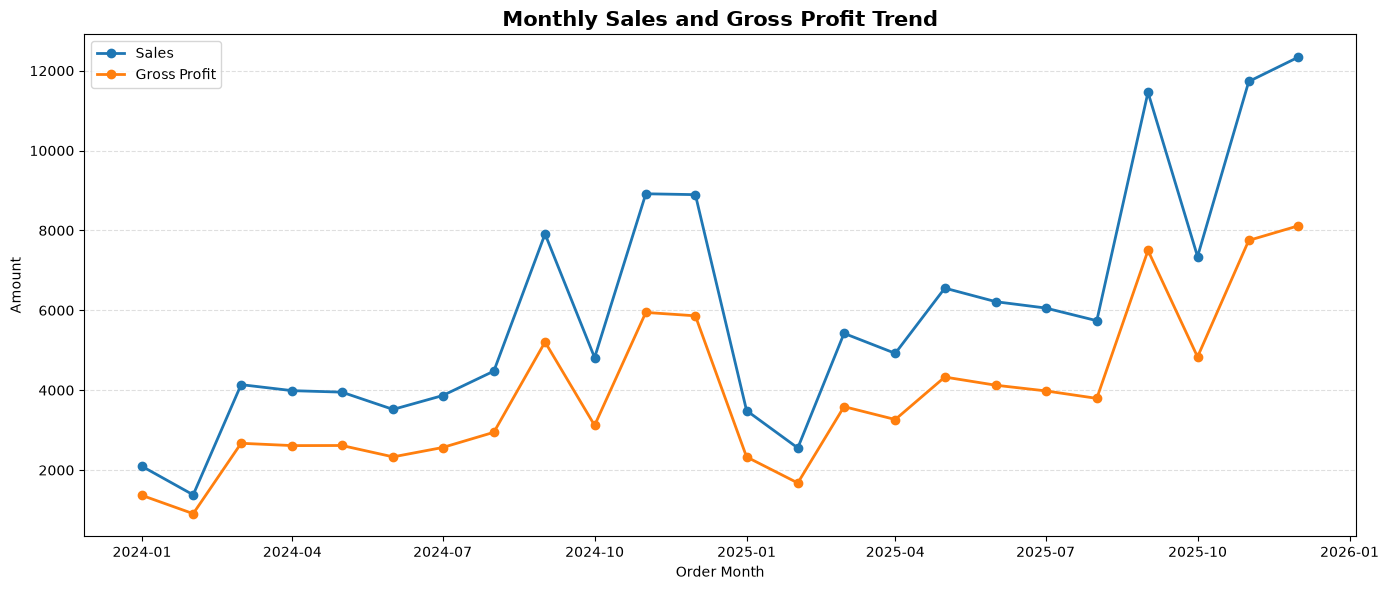


✔ Monthly Sales and Gross Profit trend visualization completed.


In [39]:
# ============================================================
# 38. MONTHLY SALES AND GROSS PROFIT TREND
# ============================================================

import matplotlib.pyplot as plt

# Create the figure.
fig, ax = plt.subplots(figsize=(14, 6))

# Plot monthly Sales.
ax.plot(
    monthly_profitability["Order Month"],
    monthly_profitability["Sales"],
    marker="o",
    linewidth=2,
    label="Sales"
)

# Plot monthly Gross Profit.
ax.plot(
    monthly_profitability["Order Month"],
    monthly_profitability["Gross_Profit"],
    marker="o",
    linewidth=2,
    label="Gross Profit"
)

# Add chart title and axis labels.
ax.set_title(
    "Monthly Sales and Gross Profit Trend",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Order Month")
ax.set_ylabel("Amount")

# Add grid for easier interpretation.
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

# Display legend.
ax.legend()

# Improve layout.
plt.tight_layout()

# Display the chart.
plt.show()

print("\n✔ Monthly Sales and Gross Profit trend visualization completed.")

## 39. Monthly Gross Margin Trend

Sales and Gross Profit can increase simply because transaction volume increases.

Therefore, Gross Margin (%) is analyzed separately to determine whether profitability efficiency changes over time.

The monthly Gross Margin trend is calculated as:

**Gross Margin (%) = Monthly Gross Profit / Monthly Sales × 100**

This helps distinguish changes in business scale from changes in profitability efficiency.

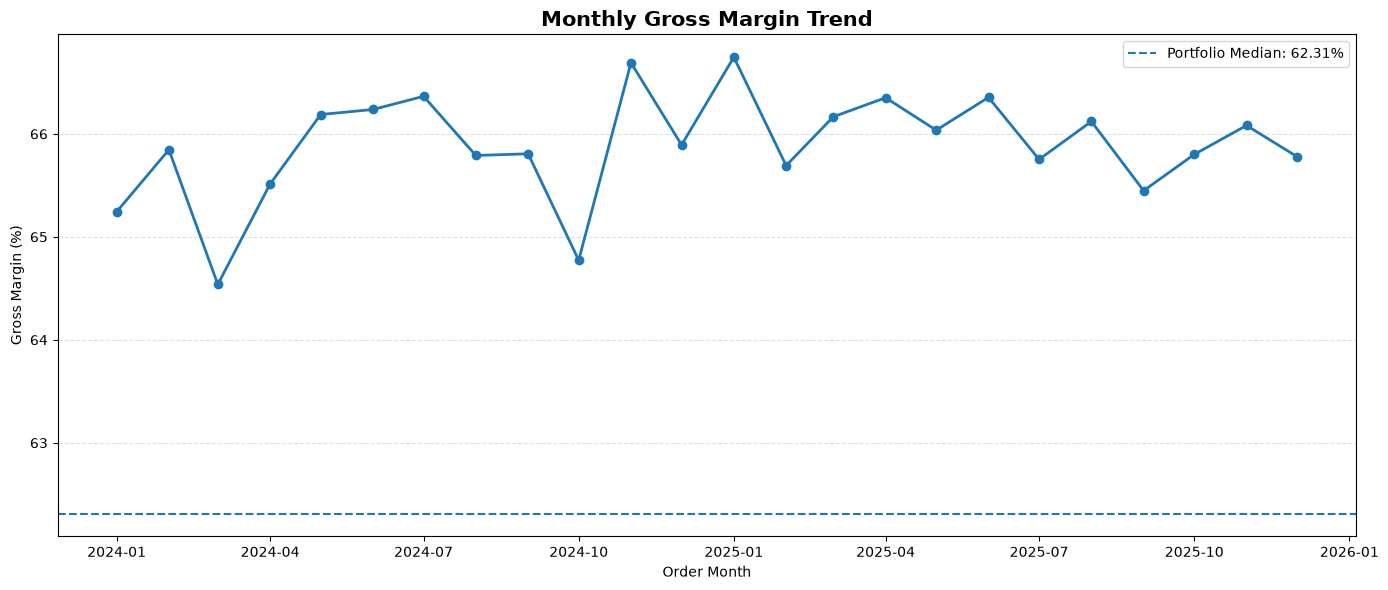


✔ Monthly Gross Margin trend visualization completed.


In [40]:
# ============================================================
# 39. MONTHLY GROSS MARGIN TREND
# ============================================================

# Create the figure.
fig, ax = plt.subplots(figsize=(14, 6))

# Plot monthly Gross Margin.
ax.plot(
    monthly_profitability["Order Month"],
    monthly_profitability["Gross Margin (%)"],
    marker="o",
    linewidth=2
)

# Add portfolio median margin as a reference line.
ax.axhline(
    y=margin_median,
    linestyle="--",
    linewidth=1.5,
    label=f"Portfolio Median: {margin_median:.2f}%"
)

# Add chart title and axis labels.
ax.set_title(
    "Monthly Gross Margin Trend",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Order Month")
ax.set_ylabel("Gross Margin (%)")

# Add grid for readability.
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

# Display legend.
ax.legend()

# Improve layout.
plt.tight_layout()

# Display chart.
plt.show()

print("\n✔ Monthly Gross Margin trend visualization completed.")

## 40. Monthly Trend Summary Statistics

The monthly profitability trend is summarized using descriptive statistics.

The analysis identifies:

- Average monthly Sales
- Average monthly Gross Profit
- Average monthly Gross Margin
- Minimum and maximum monthly Sales
- Minimum and maximum monthly Gross Profit
- Minimum and maximum monthly Gross Margin

These statistics provide a quantitative summary of the portfolio's monthly performance during the observed period.

In [41]:
# ============================================================
# 40. MONTHLY TREND SUMMARY STATISTICS
# ============================================================

# Calculate descriptive statistics for key monthly metrics.
monthly_trend_summary = {
    "Average Monthly Sales": monthly_profitability["Sales"].mean(),
    "Minimum Monthly Sales": monthly_profitability["Sales"].min(),
    "Maximum Monthly Sales": monthly_profitability["Sales"].max(),

    "Average Monthly Gross Profit": monthly_profitability["Gross_Profit"].mean(),
    "Minimum Monthly Gross Profit": monthly_profitability["Gross_Profit"].min(),
    "Maximum Monthly Gross Profit": monthly_profitability["Gross_Profit"].max(),

    "Average Monthly Gross Margin (%)": monthly_profitability["Gross Margin (%)"].mean(),
    "Minimum Monthly Gross Margin (%)": monthly_profitability["Gross Margin (%)"].min(),
    "Maximum Monthly Gross Margin (%)": monthly_profitability["Gross Margin (%)"].max()
}

# Convert the dictionary into a readable table.
monthly_trend_summary_df = pd.DataFrame(
    list(monthly_trend_summary.items()),
    columns=["Metric", "Value"]
)

# Display the summary.
display(
    monthly_trend_summary_df.style.format({
        "Value": "{:,.2f}"
    })
)

print("\n✔ Monthly trend summary statistics completed.")

,Metric,Value
0,Average Monthly Sales,"5,907.65"
1,Minimum Monthly Sales,"1,379.87"
2,Maximum Monthly Sales,"12,338.27"
3,Average Monthly Gross Profit,"3,893.45"
4,Minimum Monthly Gross Profit,908.59
5,Maximum Monthly Gross Profit,"8,115.95"
6,Average Monthly Gross Margin (%),65.88
7,Minimum Monthly Gross Margin (%),64.54
8,Maximum Monthly Gross Margin (%),66.75



✔ Monthly trend summary statistics completed.


## 41. Division Weighted vs. Average Margin

Division profitability is examined using two margin measures:

**Weighted Gross Margin (%)**

Calculated from aggregated Sales and Gross Profit:

**Gross Profit / Sales × 100**

**Average Transaction Margin (%)**

Calculated as the arithmetic mean of row-level Gross Margin (%).

The comparison helps determine whether the division's overall margin is influenced by differences in transaction size.

Both measures are retained because they answer different analytical questions:

- Weighted margin reflects the profitability of the division's total revenue.
- Average transaction margin reflects the typical row-level margin.

In [42]:
# ============================================================
# 41. DIVISION WEIGHTED VS. AVERAGE MARGIN
# ============================================================

# Calculate average transaction-level margin by division.
division_average_margin = (
    df_clean
    .groupby("Division")["Gross Margin (%)"]
    .mean()
    .rename("Average Transaction Margin (%)")
    .reset_index()
)

# Merge average margin with the existing division analysis.
division_margin_comparison = division_analysis.merge(
    division_average_margin,
    on="Division",
    how="left"
)

# Calculate the difference between the two margin measures.
division_margin_comparison["Weighted vs Average Margin Gap (pp)"] = (
    division_margin_comparison["Gross Margin (%)"]
    - division_margin_comparison["Average Transaction Margin (%)"]
)

# Display comparison.
display(
    division_margin_comparison[
        [
            "Division",
            "Sales",
            "Gross_Profit",
            "Gross Margin (%)",
            "Average Transaction Margin (%)",
            "Weighted vs Average Margin Gap (pp)",
            "Revenue Contribution (%)",
            "Profit Contribution (%)"
        ]
    ].style.format({
        "Sales": "{:,.2f}",
        "Gross_Profit": "{:,.2f}",
        "Gross Margin (%)": "{:.2f}",
        "Average Transaction Margin (%)": "{:.2f}",
        "Weighted vs Average Margin Gap (pp)": "{:.2f}",
        "Revenue Contribution (%)": "{:.2f}",
        "Profit Contribution (%)": "{:.2f}"
    })
)

print("\n✔ Division weighted vs. average margin analysis completed.")

,Division,Sales,Gross_Profit,Gross Margin (%),Average Transaction Margin (%),Weighted vs Average Margin Gap (pp),Revenue Contribution (%),Profit Contribution (%)
0,Chocolate,"131,692.90","88,824.62",67.45,67.46,-0.01,92.88,95.06
1,Other,"9,663.25","4,333.45",44.84,37.67,7.17,6.82,4.64
2,Sugar,427.48,284.73,66.61,57.69,8.92,0.30,0.30



✔ Division weighted vs. average margin analysis completed.


## 42. Division Margin Comparison Validation

The weighted and average transaction-level margin calculations are validated to ensure:

- Every division has both margin measures.
- No margin values are missing or infinite.
- Weighted Gross Margin remains consistent with:
  **Gross Profit / Sales × 100**
- All divisions represented in the cleaned dataset are included.

The validation confirms that the division-level profitability comparison is analytically complete.

In [43]:
# ============================================================
# 42. DIVISION MARGIN COMPARISON VALIDATION
# ============================================================

# ------------------------------------------------------------
# Validate division coverage
# ------------------------------------------------------------

dataset_divisions = set(df_clean["Division"].unique())
analysis_divisions = set(
    division_margin_comparison["Division"].unique()
)

missing_divisions = dataset_divisions - analysis_divisions

# ------------------------------------------------------------
# Validate missing and infinite values
# ------------------------------------------------------------

weighted_margin_missing = (
    division_margin_comparison["Gross Margin (%)"]
    .isna()
    .sum()
)

average_margin_missing = (
    division_margin_comparison["Average Transaction Margin (%)"]
    .isna()
    .sum()
)

weighted_margin_infinite = np.isinf(
    division_margin_comparison["Gross Margin (%)"]
).sum()

average_margin_infinite = np.isinf(
    division_margin_comparison["Average Transaction Margin (%)"]
).sum()

# ------------------------------------------------------------
# Independently recalculate weighted margin
# ------------------------------------------------------------

division_margin_recalculated = (
    division_margin_comparison["Gross_Profit"]
    / division_margin_comparison["Sales"]
) * 100

maximum_margin_difference = (
    division_margin_recalculated
    - division_margin_comparison["Gross Margin (%)"]
).abs().max()

# ------------------------------------------------------------
# Display validation results
# ------------------------------------------------------------

print("Division Margin Comparison Validation")
print("=" * 55)

print(f"Divisions in dataset              : {len(dataset_divisions)}")
print(f"Divisions in analysis             : {len(analysis_divisions)}")
print(f"Missing divisions                 : {len(missing_divisions)}")

print(
    f"Weighted margin missing values    : "
    f"{weighted_margin_missing}"
)

print(
    f"Average margin missing values     : "
    f"{average_margin_missing}"
)

print(
    f"Weighted margin infinite values   : "
    f"{weighted_margin_infinite}"
)

print(
    f"Average margin infinite values    : "
    f"{average_margin_infinite}"
)

print(
    f"Maximum weighted margin difference: "
    f"{maximum_margin_difference:.10f} pp"
)

# ------------------------------------------------------------
# Final validation
# ------------------------------------------------------------

if (
    len(missing_divisions) == 0
    and weighted_margin_missing == 0
    and average_margin_missing == 0
    and weighted_margin_infinite == 0
    and average_margin_infinite == 0
    and maximum_margin_difference < 1e-10
):
    print("\n✔ Division margin comparison validation passed.")
else:
    print("\n⚠ Validation failed. Review the division margin calculations.")

Division Margin Comparison Validation
Divisions in dataset              : 3
Divisions in analysis             : 3
Missing divisions                 : 0
Weighted margin missing values    : 0
Average margin missing values     : 0
Weighted margin infinite values   : 0
Average margin infinite values    : 0
Maximum weighted margin difference: 0.0000000000 pp

✔ Division margin comparison validation passed.


## 43. Division Gross Profit Comparison

Gross Profit is compared across divisions to visualize the distribution of total profit generation.

The visualization helps identify the relative contribution of each division to overall Gross Profit.

Because divisions are categorical entities, a bar chart is used for direct comparison.

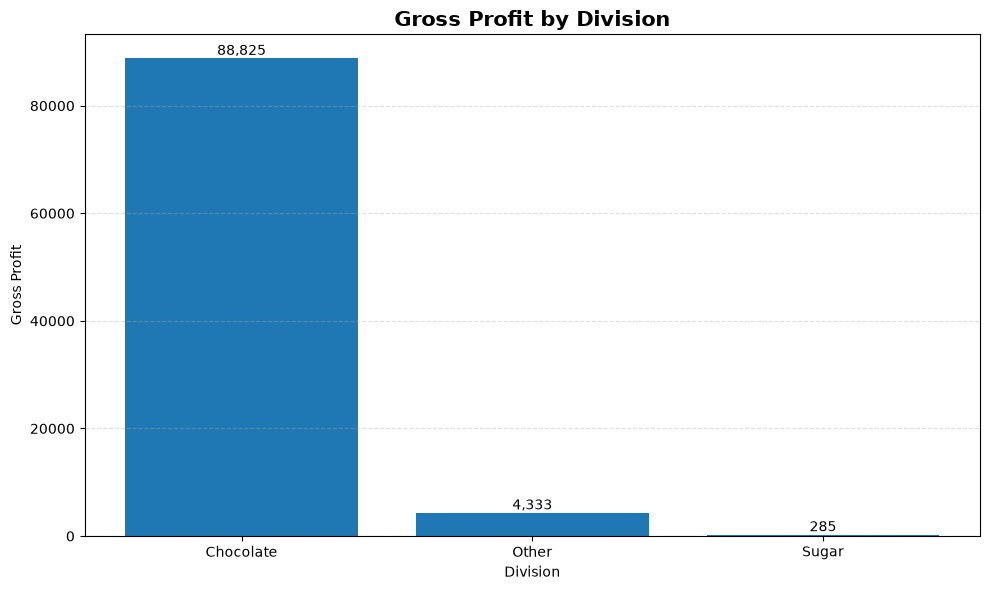


✔ Division Gross Profit visualization completed.


In [44]:
# ============================================================
# 43. DIVISION GROSS PROFIT COMPARISON
# ============================================================

# Sort divisions by Gross Profit for clearer comparison.
division_profit_chart = (
    division_margin_comparison
    .sort_values(
        "Gross_Profit",
        ascending=False
    )
)

# Create the figure.
fig, ax = plt.subplots(figsize=(10, 6))

# Create the bar chart.
bars = ax.bar(
    division_profit_chart["Division"],
    division_profit_chart["Gross_Profit"]
)

# Add value labels above each bar.
for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:,.0f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

# Add title and axis labels.
ax.set_title(
    "Gross Profit by Division",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Division")
ax.set_ylabel("Gross Profit")

# Add horizontal grid lines.
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

# Improve layout.
plt.tight_layout()

# Display chart.
plt.show()

print("\n✔ Division Gross Profit visualization completed.")

## 44. Division Gross Margin Comparison

Gross Margin (%) is compared across divisions to evaluate profitability efficiency independently of division size.

Unlike Gross Profit, which reflects the absolute amount of profit generated, Gross Margin measures the proportion of Sales retained as Gross Profit.

This distinction helps separate:

- Profit scale
- Profitability efficiency

A bar chart is used to compare the divisions directly.

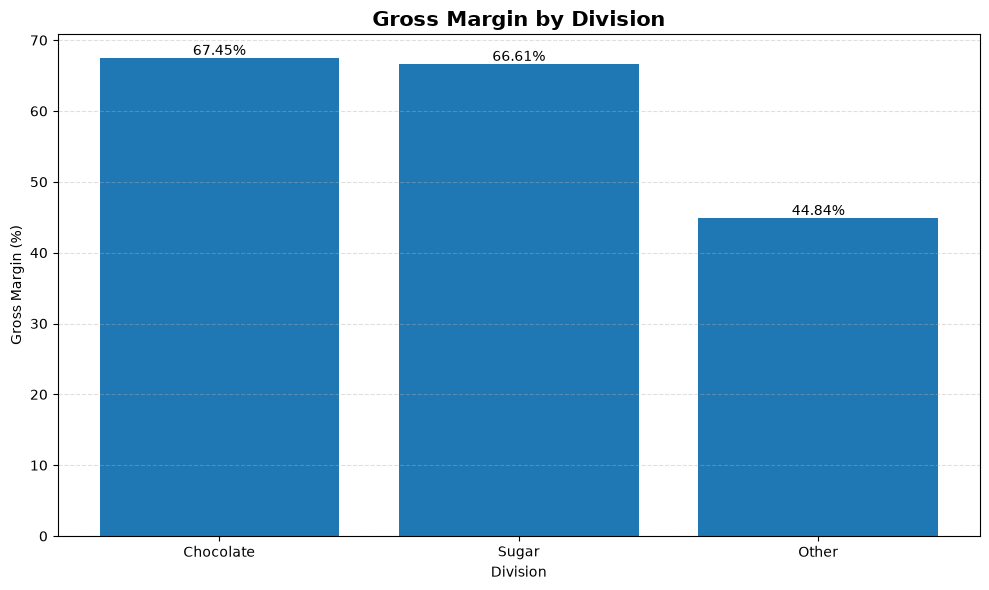


✔ Division Gross Margin visualization completed.


In [45]:
# ============================================================
# 44. DIVISION GROSS MARGIN COMPARISON
# ============================================================

# Sort divisions by Gross Margin.
division_margin_chart = (
    division_margin_comparison
    .sort_values(
        "Gross Margin (%)",
        ascending=False
    )
)

# Create the figure.
fig, ax = plt.subplots(figsize=(10, 6))

# Create the bar chart.
bars = ax.bar(
    division_margin_chart["Division"],
    division_margin_chart["Gross Margin (%)"]
)

# Add percentage labels above each bar.
for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

# Add title and axis labels.
ax.set_title(
    "Gross Margin by Division",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Division")
ax.set_ylabel("Gross Margin (%)")

# Add horizontal grid lines.
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

# Improve layout.
plt.tight_layout()

# Display chart.
plt.show()

print("\n✔ Division Gross Margin visualization completed.")

## 45. Division Revenue vs. Profit Contribution

Revenue Contribution (%) and Profit Contribution (%) are compared at the division level.

The comparison identifies differences between a division's share of total Sales and its share of total Gross Profit.

The contribution gap is calculated as:

**Profit Contribution (%) − Revenue Contribution (%)**

A positive gap indicates that the division contributes a larger share of total Gross Profit than of total Sales.

A negative gap indicates that the division contributes a smaller share of total Gross Profit than of total Sales.

This provides a portfolio-level view of how efficiently revenue translates into Gross Profit across divisions.

In [46]:
# ============================================================
# 45. DIVISION REVENUE VS. PROFIT CONTRIBUTION
# ============================================================

# Create a comparison table.
division_contribution = division_margin_comparison[
    [
        "Division",
        "Revenue Contribution (%)",
        "Profit Contribution (%)"
    ]
].copy()

# Calculate the contribution gap.
division_contribution["Contribution Gap (pp)"] = (
    division_contribution["Profit Contribution (%)"]
    - division_contribution["Revenue Contribution (%)"]
)

# Sort by Revenue Contribution.
division_contribution = (
    division_contribution
    .sort_values(
        "Revenue Contribution (%)",
        ascending=False
    )
    .reset_index(drop=True)
)

# Display the comparison table.
display(
    division_contribution.style.format({
        "Revenue Contribution (%)": "{:.2f}",
        "Profit Contribution (%)": "{:.2f}",
        "Contribution Gap (pp)": "{:.2f}"
    })
)

print("\n✔ Division revenue vs. profit contribution analysis completed.")

,Division,Revenue Contribution (%),Profit Contribution (%),Contribution Gap (pp)
0,Chocolate,92.88,95.06,2.17
1,Other,6.82,4.64,-2.18
2,Sugar,0.30,0.30,0.00



✔ Division revenue vs. profit contribution analysis completed.


## 46. Division Contribution Validation

The division-level Revenue Contribution and Profit Contribution are validated against the portfolio totals.

The validation checks that:

- Revenue Contribution totals 100%.
- Profit Contribution totals 100%.
- Contribution Gap equals:
  **Profit Contribution (%) − Revenue Contribution (%)**
- No contribution values are missing or infinite.

This ensures that the division contribution comparison is internally consistent.

In [47]:
# ============================================================
# 46. DIVISION CONTRIBUTION VALIDATION
# ============================================================

# ------------------------------------------------------------
# Validate contribution totals
# ------------------------------------------------------------

total_revenue_contribution = (
    division_contribution["Revenue Contribution (%)"].sum()
)

total_profit_contribution = (
    division_contribution["Profit Contribution (%)"].sum()
)

# ------------------------------------------------------------
# Independently recalculate contribution gaps
# ------------------------------------------------------------

recalculated_gap = (
    division_contribution["Profit Contribution (%)"]
    - division_contribution["Revenue Contribution (%)"]
)

maximum_gap_difference = (
    recalculated_gap
    - division_contribution["Contribution Gap (pp)"]
).abs().max()

# ------------------------------------------------------------
# Check missing and infinite values
# ------------------------------------------------------------

missing_values = division_contribution[
    [
        "Revenue Contribution (%)",
        "Profit Contribution (%)",
        "Contribution Gap (pp)"
    ]
].isna().sum().sum()

infinite_values = np.isinf(
    division_contribution[
        [
            "Revenue Contribution (%)",
            "Profit Contribution (%)",
            "Contribution Gap (pp)"
        ]
    ]
).sum().sum()

# ------------------------------------------------------------
# Display validation results
# ------------------------------------------------------------

print("Division Contribution Validation")
print("=" * 50)

print(
    f"Revenue Contribution Total : "
    f"{total_revenue_contribution:.2f}%"
)

print(
    f"Profit Contribution Total  : "
    f"{total_profit_contribution:.2f}%"
)

print(
    f"Maximum Gap Calculation Difference: "
    f"{maximum_gap_difference:.10f} pp"
)

print(f"Missing values             : {missing_values}")
print(f"Infinite values            : {infinite_values}")

# ------------------------------------------------------------
# Final validation
# ------------------------------------------------------------

if (
    abs(total_revenue_contribution - 100) < 1e-10
    and abs(total_profit_contribution - 100) < 1e-10
    and maximum_gap_difference < 1e-10
    and missing_values == 0
    and infinite_values == 0
):
    print("\n✔ Division contribution validation passed.")
else:
    print("\n⚠ Validation failed. Review the contribution calculations.")

Division Contribution Validation
Revenue Contribution Total : 100.00%
Profit Contribution Total  : 100.00%
Maximum Gap Calculation Difference: 0.0000000000 pp
Missing values             : 0
Infinite values            : 0

✔ Division contribution validation passed.


## 47. Product Gross Profit Ranking

Products are ranked by total Gross Profit to identify the products contributing the largest absolute amount of profit.

Gross Profit is used rather than Sales because the objective of this analysis is to understand profitability contribution.

The ranking will retain Sales and Gross Margin (%) as supporting metrics to provide context around each product's profit generation.

In [48]:
# ============================================================
# 47. PRODUCT GROSS PROFIT RANKING
# ============================================================

# Select the key product profitability metrics.
product_profit_ranking = (
    product_analysis[
        [
            "Product ID",
            "Product Name",
            "Sales",
            "Gross_Profit",
            "Gross Margin (%)",
            "Profit Contribution (%)"
        ]
    ]
    .sort_values(
        "Gross_Profit",
        ascending=False
    )
    .reset_index(drop=True)
)

# Add a sequential profit rank.
product_profit_ranking["Profit Rank"] = (
    product_profit_ranking.index + 1
)

# Reorder columns for presentation.
product_profit_ranking = product_profit_ranking[
    [
        "Profit Rank",
        "Product ID",
        "Product Name",
        "Sales",
        "Gross_Profit",
        "Gross Margin (%)",
        "Profit Contribution (%)"
    ]
]

# Display ranking.
display(
    product_profit_ranking.style.format({
        "Sales": "{:,.2f}",
        "Gross_Profit": "{:,.2f}",
        "Gross Margin (%)": "{:.2f}",
        "Profit Contribution (%)": "{:.2f}"
    })
)

print("\n✔ Product Gross Profit ranking completed.")

,Profit Rank,Product ID,Product Name,Sales,Gross_Profit,Gross Margin (%),Profit Contribution (%)
0,1,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,"27,874.80","19,357.50",69.44,20.72
1,2,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,"28,485.00","18,610.20",65.33,19.92
2,3,CHO-MIL-31000,Wonka Bar - Milk Chocolate,"26,867.75","17,443.37",64.92,18.67
3,4,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,"23,574.95","16,819.95",71.35,18.00
4,5,CHO-FUD-51000,Wonka Bar - Fudge Mallows,"24,890.40","16,593.60",66.67,17.76
5,6,OTH-LIC-15000,Lickable Wallpaper,"7,860.00","3,930.00",50.00,4.21
6,7,OTH-GUM-21000,Wonka Gum,597.50,310.70,52.00,0.33
7,8,SUG-EVE-47000,Everlasting Gobstopper,130.00,104.00,80.00,0.11
8,9,OTH-KAZ-38000,Kazookles,"1,205.75",92.75,7.69,0.10
9,10,SUG-HAI-55000,Hair Toffee,76.50,59.50,77.78,0.06



✔ Product Gross Profit ranking completed.


## 48. Top Products by Gross Profit

The top products are visualized by Gross Profit to provide a clear view of profit concentration at the product level.

The visualization focuses on the highest-profit products while retaining the complete ranking table from the previous analysis.

A horizontal bar chart is used because product names are long and require readable labels.

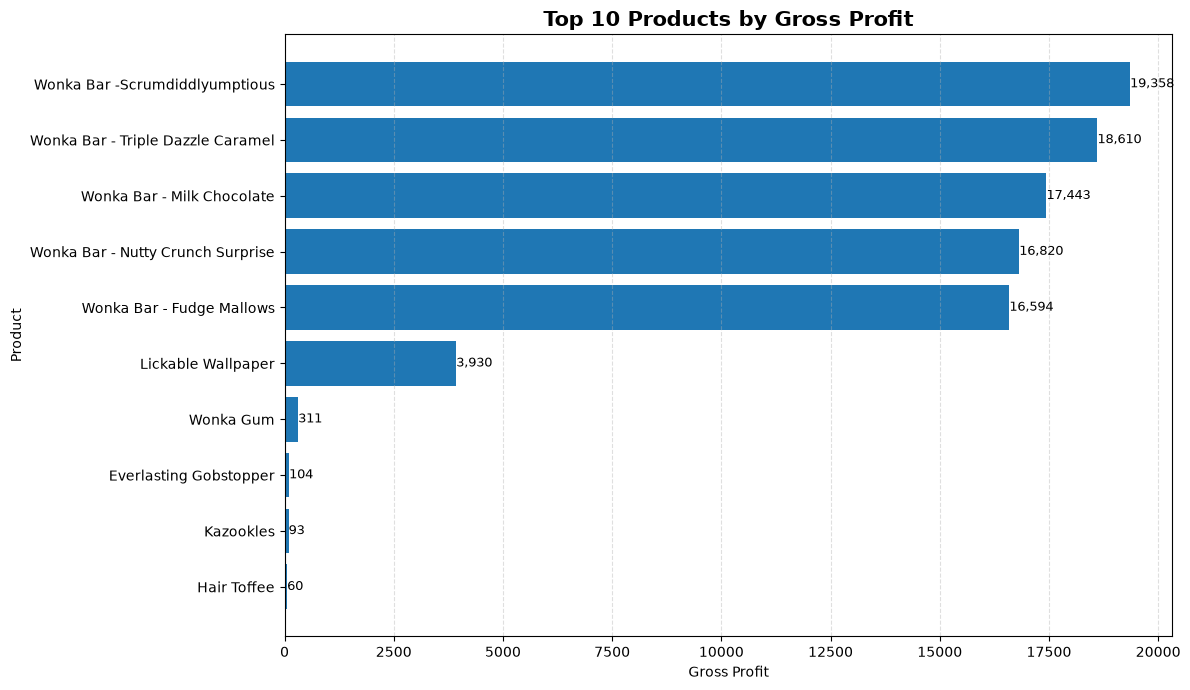


✔ Top 10 product Gross Profit visualization completed.


In [49]:
# ============================================================
# 48. TOP PRODUCTS BY GROSS PROFIT
# ============================================================

# Select the top 10 products by Gross Profit.
top_10_profit_products = (
    product_profit_ranking
    .head(10)
    .sort_values(
        "Gross_Profit",
        ascending=True
    )
)

# Create the figure.
fig, ax = plt.subplots(figsize=(12, 7))

# Create horizontal bar chart.
bars = ax.barh(
    top_10_profit_products["Product Name"],
    top_10_profit_products["Gross_Profit"]
)

# Add value labels at the end of each bar.
for bar in bars:
    width = bar.get_width()

    ax.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"{width:,.0f}",
        va="center",
        ha="left",
        fontsize=9
    )

# Add title and axis labels.
ax.set_title(
    "Top 10 Products by Gross Profit",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Gross Profit")
ax.set_ylabel("Product")

# Add vertical grid lines.
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.4
)

# Improve layout for long product names.
plt.tight_layout()

# Display chart.
plt.show()

print("\n✔ Top 10 product Gross Profit visualization completed.")

## 49. Sales vs. Gross Margin Diagnostic

Sales and Gross Margin (%) are compared at the product level to identify differences between commercial scale and profitability efficiency.

The scatter plot helps distinguish products that have:

- High Sales and high margins.
- High Sales and lower margins.
- Low Sales and high margins.
- Low Sales and lower margins.

The portfolio median Sales and Gross Margin are used as reference boundaries to provide context for the four profitability segments identified earlier.

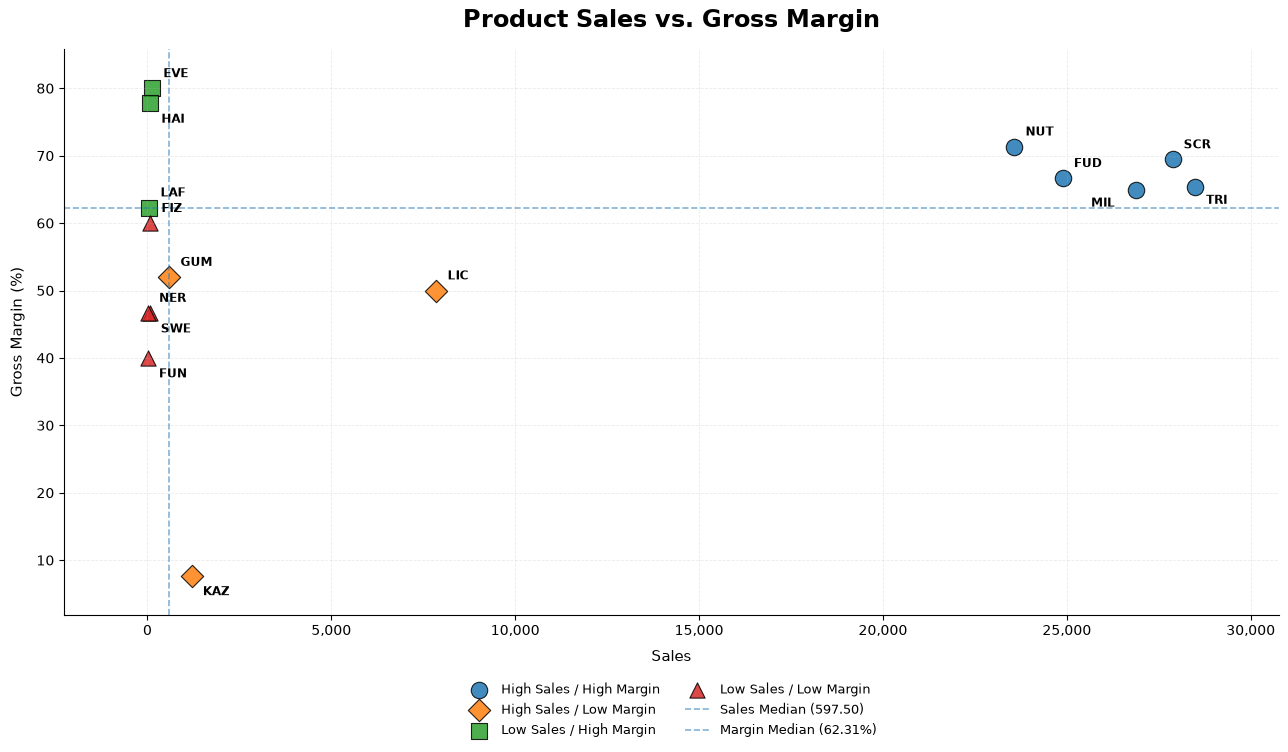


✔ Clean professional Sales vs. Gross Margin visualization completed.


In [52]:
# ============================================================
# 49. CLEAN SALES VS. GROSS MARGIN DIAGNOSTIC
# ============================================================

# Create visualization dataset.
sales_margin_plot = product_analysis[
    [
        "Product ID",
        "Product Name",
        "Sales",
        "Gross Margin (%)"
    ]
].copy()

# ------------------------------------------------------------
# Create short product codes
# ------------------------------------------------------------

# Extract the final product code from Product ID.
# Example: CHO-SCR-58000 -> SCR
sales_margin_plot["Product Code"] = (
    sales_margin_plot["Product ID"]
    .str.split("-")
    .str[1]
)

# ------------------------------------------------------------
# Create profitability segments
# ------------------------------------------------------------

sales_margin_plot["Segment"] = np.select(
    [
        (
            (sales_margin_plot["Sales"] >= sales_median)
            & (sales_margin_plot["Gross Margin (%)"] >= margin_median)
        ),
        (
            (sales_margin_plot["Sales"] >= sales_median)
            & (sales_margin_plot["Gross Margin (%)"] < margin_median)
        ),
        (
            (sales_margin_plot["Sales"] < sales_median)
            & (sales_margin_plot["Gross Margin (%)"] >= margin_median)
        )
    ],
    [
        "High Sales / High Margin",
        "High Sales / Low Margin",
        "Low Sales / High Margin"
    ],
    default="Low Sales / Low Margin"
)

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(13, 8)
)

# ------------------------------------------------------------
# Plot each profitability segment separately
# ------------------------------------------------------------

segment_styles = {
    "High Sales / High Margin": {
        "marker": "o",
        "size": 140
    },
    "High Sales / Low Margin": {
        "marker": "D",
        "size": 130
    },
    "Low Sales / High Margin": {
        "marker": "s",
        "size": 120
    },
    "Low Sales / Low Margin": {
        "marker": "^",
        "size": 120
    }
}

for segment, style in segment_styles.items():

    subset = sales_margin_plot[
        sales_margin_plot["Segment"] == segment
    ]

    ax.scatter(
        subset["Sales"],
        subset["Gross Margin (%)"],
        s=style["size"],
        marker=style["marker"],
        alpha=0.85,
        edgecolors="black",
        linewidths=0.8,
        label=segment
    )

# ------------------------------------------------------------
# Add clean product labels
# ------------------------------------------------------------

# Manually selected offsets prevent overlap among nearby products.
label_offsets = {
    "SCR": (8, 8),
    "TRI": (8, -12),
    "MIL": (-32, -12),
    "NUT": (8, 8),
    "FUD": (8, 8),
    "LIC": (8, 8),
    "GUM": (8, 8),
    "EVE": (8, 8),
    "KAZ": (8, -14),
    "HAI": (8, -14),
    "FIZ": (8, 8),
    "LAF": (8, 8),
    "SWE": (8, -14),
    "NER": (8, 8),
    "FUN": (8, -14)
}

for _, row in sales_margin_plot.iterrows():

    code = row["Product Code"]

    offset = label_offsets.get(
        code,
        (7, 7)
    )

    ax.annotate(
        code,
        xy=(
            row["Sales"],
            row["Gross Margin (%)"]
        ),
        xytext=offset,
        textcoords="offset points",
        fontsize=8.5,
        fontweight="bold"
    )

# ------------------------------------------------------------
# Add median reference lines
# ------------------------------------------------------------

ax.axvline(
    x=sales_median,
    linestyle="--",
    linewidth=1.2,
    alpha=0.55,
    label=f"Sales Median ({sales_median:,.2f})"
)

ax.axhline(
    y=margin_median,
    linestyle="--",
    linewidth=1.2,
    alpha=0.55,
    label=f"Margin Median ({margin_median:.2f}%)"
)

# ------------------------------------------------------------
# Titles and axis labels
# ------------------------------------------------------------

ax.set_title(
    "Product Sales vs. Gross Margin",
    fontsize=17,
    fontweight="bold",
    pad=16
)

ax.set_xlabel(
    "Sales",
    fontsize=11,
    labelpad=8
)

ax.set_ylabel(
    "Gross Margin (%)",
    fontsize=11,
    labelpad=8
)

# ------------------------------------------------------------
# Format axes
# ------------------------------------------------------------

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, _: f"{x:,.0f}"
    )
)

# Add a small margin around the data.
ax.margins(
    x=0.08,
    y=0.08
)

# ------------------------------------------------------------
# Professional grid and borders
# ------------------------------------------------------------

ax.grid(
    axis="both",
    linestyle="--",
    linewidth=0.6,
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ------------------------------------------------------------
# Clean legend
# ------------------------------------------------------------

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=2,
    frameon=False,
    fontsize=9
)

# ------------------------------------------------------------
# Final layout
# ------------------------------------------------------------

plt.tight_layout(
    rect=[0, 0.04, 1, 1]
)

plt.show()

print(
    "\n✔ Clean professional Sales vs. Gross Margin "
    "visualization completed."
)

    ## 50. Sales vs. Gross Margin Segmentation Validation

The Sales vs. Gross Margin visualization uses the same median Sales and Gross Margin
benchmarks established during the product segmentation analysis.

The visualization classification is validated against the previously calculated
product profitability segments.

This ensures that the visual diagnostic does not introduce a different
classification logic from the underlying analytical results.

In [53]:
# ============================================================
# 50. SALES VS. GROSS MARGIN SEGMENTATION VALIDATION
# ============================================================

# ------------------------------------------------------------
# Compare visualization segments with the original
# product profitability segmentation.
# ------------------------------------------------------------

segment_comparison = sales_margin_plot[
    [
        "Product ID",
        "Product Name",
        "Segment"
    ]
].merge(
    product_analysis[
        [
            "Product ID",
            "Profitability Segment"
        ]
    ],
    on="Product ID",
    how="left"
)

# Rename the original segmentation column for clarity.
segment_comparison.rename(
    columns={
        "Profitability Segment": "Original Segment"
    },
    inplace=True
)

# Check whether both classifications match.
segment_comparison["Match"] = (
    segment_comparison["Segment"]
    == segment_comparison["Original Segment"]
)

# ------------------------------------------------------------
# Display validation results
# ------------------------------------------------------------

display(
    segment_comparison[
        [
            "Product ID",
            "Product Name",
            "Segment",
            "Original Segment",
            "Match"
        ]
    ]
)

# ------------------------------------------------------------
# Calculate validation metrics
# ------------------------------------------------------------

total_products_checked = len(segment_comparison)

matching_products = (
    segment_comparison["Match"]
    .sum()
)

mismatched_products = (
    (~segment_comparison["Match"])
    .sum()
)

# ------------------------------------------------------------
# Display summary
# ------------------------------------------------------------

print("\nSales vs. Gross Margin Segmentation Validation")
print("=" * 55)

print(
    f"Products checked       : {total_products_checked}"
)

print(
    f"Matching classifications: {matching_products}"
)

print(
    f"Mismatched classifications: {mismatched_products}"
)

# ------------------------------------------------------------
# Final validation
# ------------------------------------------------------------

if mismatched_products == 0:
    print(
        "\n✔ Visualization segmentation matches "
        "the original product segmentation."
    )
else:
    print(
        "\n⚠ Classification mismatch detected. "
        "Review the segmentation logic."
    )

,Product ID,Product Name,Segment,Original Segment,Match
0,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,High Sales / High Margin,High Sales / High Margin,True
1,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,High Sales / High Margin,High Sales / High Margin,True
2,CHO-MIL-31000,Wonka Bar - Milk Chocolate,High Sales / High Margin,High Sales / High Margin,True
3,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,High Sales / High Margin,High Sales / High Margin,True
4,CHO-FUD-51000,Wonka Bar - Fudge Mallows,High Sales / High Margin,High Sales / High Margin,True
5,OTH-LIC-15000,Lickable Wallpaper,High Sales / Low Margin,High Sales / Low Margin,True
6,OTH-GUM-21000,Wonka Gum,High Sales / Low Margin,High Sales / Low Margin,True
7,SUG-EVE-47000,Everlasting Gobstopper,Low Sales / High Margin,Low Sales / High Margin,True
8,OTH-KAZ-38000,Kazookles,High Sales / Low Margin,High Sales / Low Margin,True
9,SUG-HAI-55000,Hair Toffee,Low Sales / High Margin,Low Sales / High Margin,True



Sales vs. Gross Margin Segmentation Validation
Products checked       : 15
Matching classifications: 15
Mismatched classifications: 0

✔ Visualization segmentation matches the original product segmentation.


## 51. Product Gross Margin Ranking

Products are ranked by Gross Margin (%) to compare profitability efficiency independently of Sales volume.

Gross Margin is interpreted alongside Gross Profit and Sales because a high margin
does not necessarily imply a high contribution to total portfolio profit.

The complete product ranking is retained to support comparison between margin
efficiency and absolute profitability.

In [57]:
# ============================================================
# 51. PRODUCT GROSS MARGIN RANKING
# ============================================================

# Select the required product-level metrics.
product_margin_ranking = (
    product_analysis[
        [
            "Product ID",
            "Product Name",
            "Sales",
            "Gross_Profit",
            "Gross Margin (%)",
            "Profit per Unit",
            "Profit Contribution (%)"
        ]
    ]
    .sort_values(
        "Gross Margin (%)",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Create tie-aware margin ranking.
#
# method="min" assigns the same rank to tied values.
# This is consistent with the earlier product ranking analysis.
# ------------------------------------------------------------

product_margin_ranking["Margin Rank"] = (
    product_margin_ranking["Gross Margin (%)"]
    .rank(
        method="min",
        ascending=False
    )
    .astype(int)
)

# Reorder columns.
product_margin_ranking = product_margin_ranking[
    [
        "Margin Rank",
        "Product ID",
        "Product Name",
        "Sales",
        "Gross_Profit",
        "Gross Margin (%)",
        "Profit per Unit",
        "Profit Contribution (%)"
    ]
]

# Display ranking.
display(
    product_margin_ranking.style.format({
        "Sales": "{:,.2f}",
        "Gross_Profit": "{:,.2f}",
        "Gross Margin (%)": "{:.2f}",
        "Profit per Unit": "{:.2f}",
        "Profit Contribution (%)": "{:.2f}"
    })
)

print("\n✔ Product Gross Margin ranking completed with tie-aware ranking.")

,Margin Rank,Product ID,Product Name,Sales,Gross_Profit,Gross Margin (%),Profit per Unit,Profit Contribution (%)
0,1,SUG-EVE-47000,Everlasting Gobstopper,130.00,104.00,80.00,8.00,0.11
1,2,SUG-HAI-55000,Hair Toffee,76.50,59.50,77.78,3.50,0.06
2,3,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,"23,574.95","16,819.95",71.35,2.49,18.00
3,4,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,"27,874.80","19,357.50",69.44,2.50,20.72
4,5,CHO-FUD-51000,Wonka Bar - Fudge Mallows,"24,890.40","16,593.60",66.67,2.40,17.76
5,6,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,"28,485.00","18,610.20",65.33,2.45,19.92
6,7,CHO-MIL-31000,Wonka Bar - Milk Chocolate,"26,867.75","17,443.37",64.92,2.11,18.67
7,8,SUG-LAF-25000,Laffy Taffy,53.73,33.48,62.31,1.24,0.04
8,9,OTH-FIZ-56000,Fizzy Lifting Drinks,78.75,47.25,60.00,2.25,0.05
9,10,OTH-GUM-21000,Wonka Gum,597.50,310.70,52.00,0.65,0.33



✔ Product Gross Margin ranking completed with tie-aware ranking.


## 52. Product Gross Margin Ranking Validation

The Gross Margin ranking is validated against the original product-level
Gross Margin values.

The validation checks:

- All 15 products are included.
- Products are ordered from highest to lowest Gross Margin.
- Margin ranks are sequential.
- Tied Gross Margin values are identified.

This ensures that the ranking is complete and consistent with the
product-level profitability analysis.

In [58]:
# ============================================================
# 52. PRODUCT GROSS MARGIN RANKING VALIDATION
# ============================================================

# ------------------------------------------------------------
# Validate product coverage
# ------------------------------------------------------------

products_in_dataset = set(
    product_analysis["Product ID"]
)

products_in_ranking = set(
    product_margin_ranking["Product ID"]
)

missing_products = (
    products_in_dataset
    - products_in_ranking
)

duplicate_products = (
    product_margin_ranking["Product ID"]
    .duplicated()
    .sum()
)

# ------------------------------------------------------------
# Validate descending margin order
# ------------------------------------------------------------

margin_values = (
    product_margin_ranking["Gross Margin (%)"]
)

descending_order = (
    margin_values
    .diff()
    .dropna()
    .le(0)
    .all()
)

# ------------------------------------------------------------
# Validate tie-aware ranking
# ------------------------------------------------------------

expected_ranks = (
    product_margin_ranking["Gross Margin (%)"]
    .rank(
        method="min",
        ascending=False
    )
    .astype(int)
)

rank_values_match = (
    product_margin_ranking["Margin Rank"]
    .equals(expected_ranks)
)

# ------------------------------------------------------------
# Identify tied margin values
# ------------------------------------------------------------

margin_ties = (
    product_margin_ranking
    .groupby("Gross Margin (%)")
    .filter(
        lambda x: len(x) > 1
    )
)

# ------------------------------------------------------------
# Display validation results
# ------------------------------------------------------------

print("Product Gross Margin Ranking Validation")
print("=" * 55)

print(
    f"Products in dataset       : {len(products_in_dataset)}"
)

print(
    f"Products in ranking       : {len(products_in_ranking)}"
)

print(
    f"Missing products          : {len(missing_products)}"
)

print(
    f"Duplicate product IDs     : {duplicate_products}"
)

print(
    f"Descending margin order   : {descending_order}"
)

print(
    f"Tie-aware ranks valid     : {rank_values_match}"
)

if not margin_ties.empty:

    print("\nTied Gross Margin Values:")

    display(
        margin_ties[
            [
                "Product ID",
                "Product Name",
                "Gross Margin (%)",
                "Margin Rank"
            ]
        ]
    )

# ------------------------------------------------------------
# Final validation
# ------------------------------------------------------------

if (
    len(missing_products) == 0
    and duplicate_products == 0
    and descending_order
    and rank_values_match
):
    print(
        "\n✔ Product Gross Margin ranking validation passed."
    )
else:
    print(
        "\n⚠ Ranking validation failed. Review the ranking logic."
    )

Product Gross Margin Ranking Validation
Products in dataset       : 15
Products in ranking       : 15
Missing products          : 0
Duplicate product IDs     : 0
Descending margin order   : True
Tie-aware ranks valid     : True

Tied Gross Margin Values:


,Product ID,Product Name,Gross Margin (%),Margin Rank
11,SUG-NER-92000,Nerds,46.67,12
12,SUG-SWE-91000,SweeTARTS,46.67,12



✔ Product Gross Margin ranking validation passed.


## 53. Product Gross Margin Ranking Visualization

The product Gross Margin ranking is visualized to compare profitability efficiency
across the product portfolio.

A horizontal bar chart is used because product names are relatively long.

The visualization complements the Gross Profit ranking by showing margin
efficiency rather than absolute profit contribution.

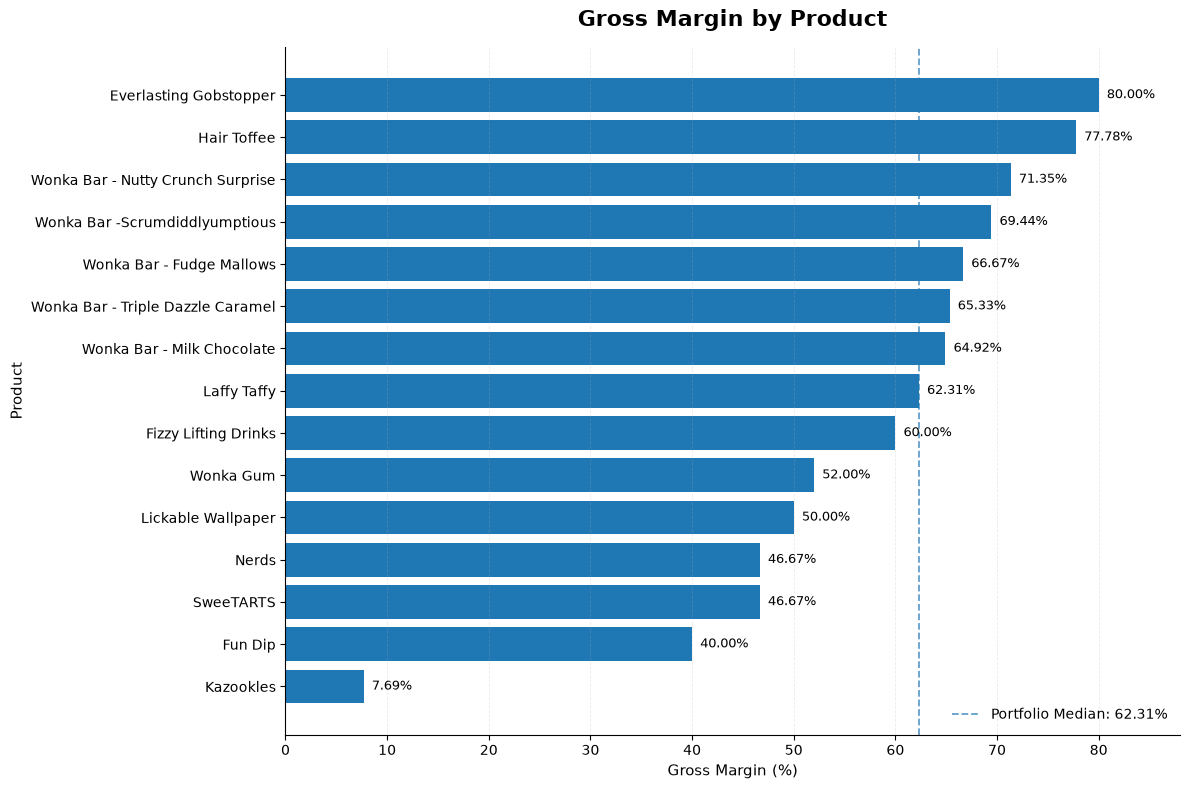


✔ Product Gross Margin ranking visualization completed.


In [59]:
# ============================================================
# 53. PRODUCT GROSS MARGIN RANKING VISUALIZATION
# ============================================================

# Select all products and sort from lowest to highest margin
# so the highest-margin products appear at the top.
margin_chart_data = (
    product_margin_ranking
    .sort_values(
        "Gross Margin (%)",
        ascending=True
    )
)

# Create the figure.
fig, ax = plt.subplots(
    figsize=(12, 8)
)

# Create horizontal bars.
bars = ax.barh(
    margin_chart_data["Product Name"],
    margin_chart_data["Gross Margin (%)"]
)

# Add percentage labels.
for bar in bars:

    width = bar.get_width()

    ax.text(
        width + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center",
        fontsize=9
    )

# ------------------------------------------------------------
# Add portfolio median reference line
# ------------------------------------------------------------

ax.axvline(
    x=margin_median,
    linestyle="--",
    linewidth=1.3,
    alpha=0.7,
    label=f"Portfolio Median: {margin_median:.2f}%"
)

# ------------------------------------------------------------
# Titles and labels
# ------------------------------------------------------------

ax.set_title(
    "Gross Margin by Product",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Gross Margin (%)",
    fontsize=11
)

ax.set_ylabel(
    "Product",
    fontsize=11
)

# ------------------------------------------------------------
# Professional formatting
# ------------------------------------------------------------

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.6,
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    frameon=False,
    loc="lower right"
)

# Add space for percentage labels.
ax.set_xlim(
    0,
    margin_chart_data["Gross Margin (%)"].max() + 8
)

plt.tight_layout()

# Display chart.
plt.show()

print(
    "\n✔ Product Gross Margin ranking visualization completed."
)

## 54. Cost Burden by Product

This analysis ranks products by their **Cost-to-Sales Ratio**, showing how much of each product's sales is consumed by cost.

The Cost-to-Sales Ratio is calculated as:

\[
\text{Cost-to-Sales Ratio} =
\frac{\text{Cost}}{\text{Sales}} \times 100
\]

A higher ratio indicates a greater cost burden relative to sales.

Gross Margin (%) is displayed alongside the cost ratio to provide profitability context. Since the two measures are mathematically complementary, the analysis focuses on identifying products with comparatively high or low cost burden rather than interpreting them as independent variables.

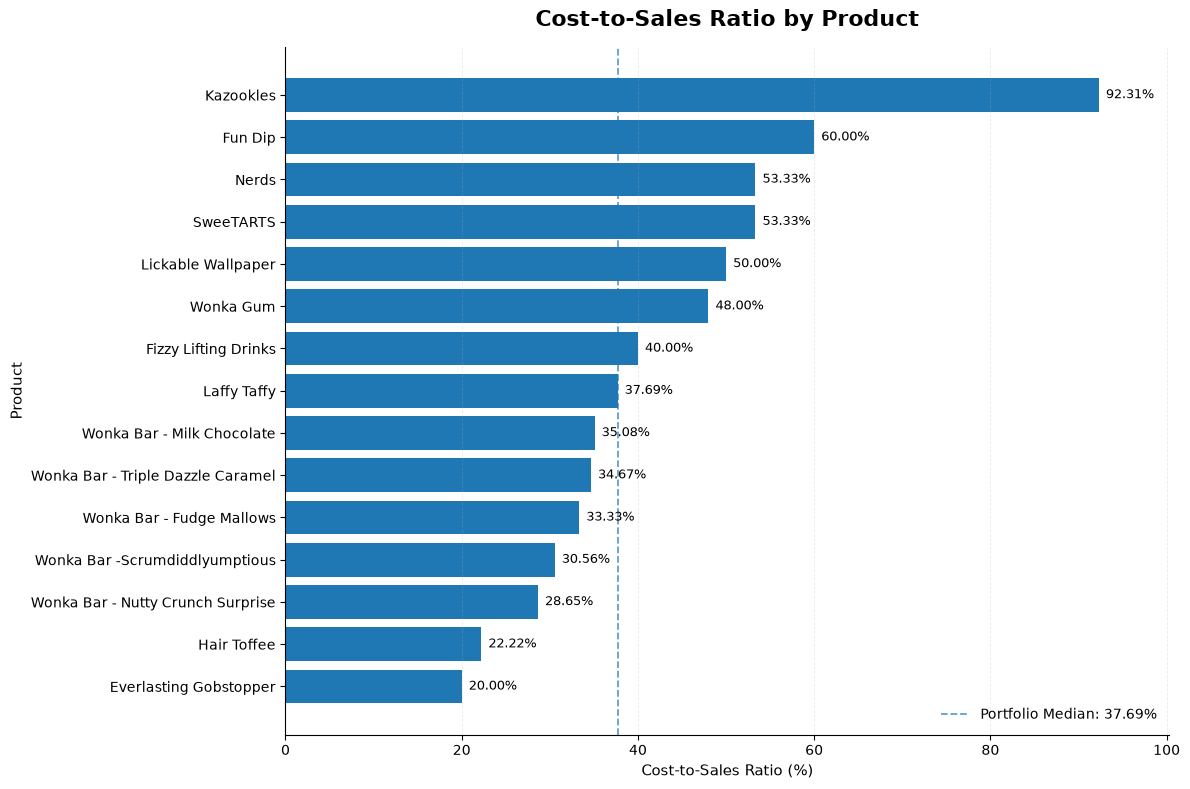


✔ Cost burden visualization completed.


In [63]:
# ============================================================
# 54. COST BURDEN BY PRODUCT
# ============================================================

# Aggregate validated transaction-level data to product level
cost_burden = (
    df_clean
    .groupby(["Product ID", "Product Name"], as_index=False)
    .agg(
        Sales=("Sales", "sum"),
        Cost=("Cost", "sum"),
        Gross_Profit=("Gross Profit", "sum")
    )
)

# Calculate Cost-to-Sales Ratio
cost_burden["Cost-to-Sales (%)"] = (
    cost_burden["Cost"] /
    cost_burden["Sales"]
) * 100

# Calculate Gross Margin for profitability context
cost_burden["Gross Margin (%)"] = (
    cost_burden["Gross_Profit"] /
    cost_burden["Sales"]
) * 100

# Sort from lowest cost burden to highest
cost_burden = cost_burden.sort_values(
    "Cost-to-Sales (%)",
    ascending=True
)

# Portfolio median cost-to-sales ratio
cost_sales_median = cost_burden["Cost-to-Sales (%)"].median()

# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    cost_burden["Product Name"],
    cost_burden["Cost-to-Sales (%)"]
)

# Add percentage labels
for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center",
        fontsize=9
    )

# Add portfolio median benchmark
ax.axvline(
    x=cost_sales_median,
    linestyle="--",
    linewidth=1.3,
    alpha=0.7,
    label=f"Portfolio Median: {cost_sales_median:.2f}%"
)

# Titles and labels
ax.set_title(
    "Cost-to-Sales Ratio by Product",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Cost-to-Sales Ratio (%)",
    fontsize=11
)

ax.set_ylabel(
    "Product",
    fontsize=11
)

# Clean formatting
ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.6,
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    frameon=False,
    loc="lower right"
)

ax.set_xlim(
    0,
    cost_burden["Cost-to-Sales (%)"].max() + 8
)

plt.tight_layout()
plt.show()

print("\n✔ Cost burden visualization completed.")

## 55. Product Profit Contribution Analysis

This analysis examines how each product contributes to total portfolio gross profit.

Profit Contribution (%) is calculated as:

\[
\text{Profit Contribution (\%)} =
\frac{\text{Product Gross Profit}}
{\text{Total Gross Profit}}
\times 100
\]

The analysis identifies the products that account for the largest share of total gross profit and highlights the concentration of profitability across the product portfolio.

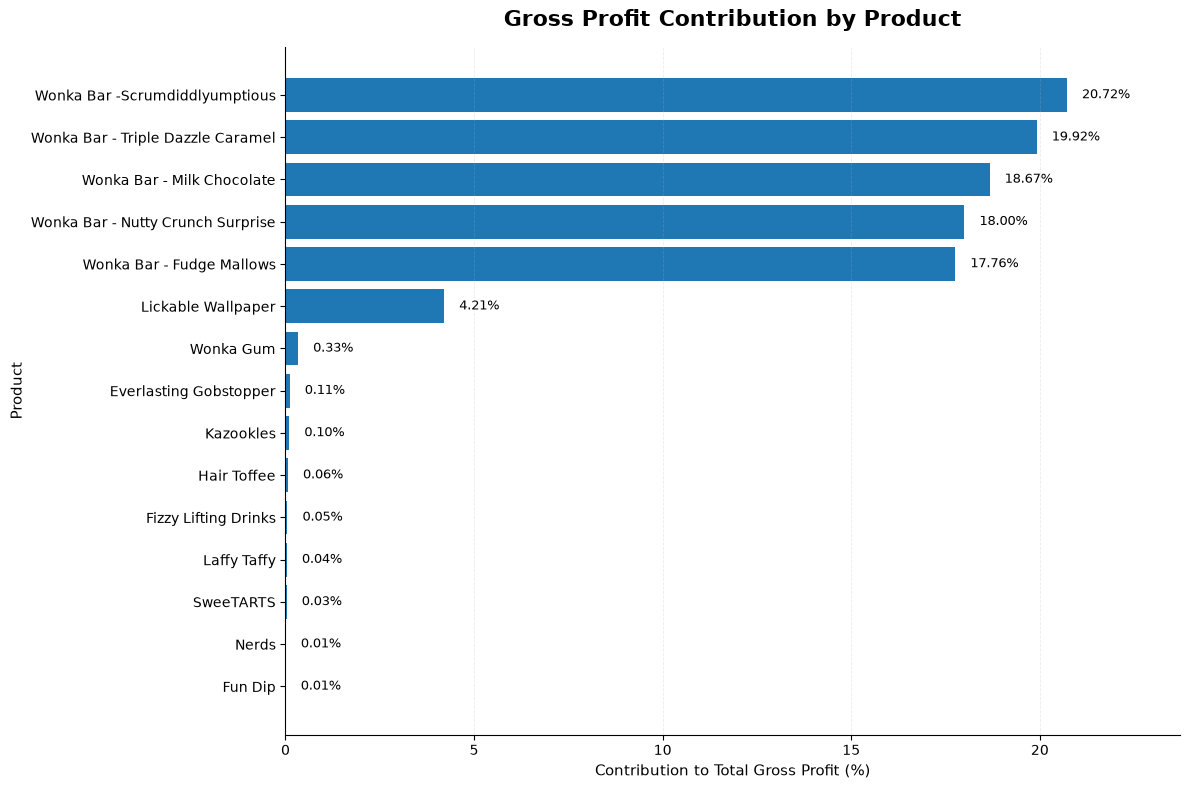


✔ Product profit contribution visualization completed.


In [64]:
# ============================================================
# 55. PRODUCT PROFIT CONTRIBUTION ANALYSIS
# ============================================================

# Aggregate gross profit at product level
profit_contribution = (
    df_clean
    .groupby(["Product ID", "Product Name"], as_index=False)
    .agg(
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross Profit", "sum")
    )
)

# Calculate each product's contribution to total gross profit
total_gross_profit = profit_contribution["Gross_Profit"].sum()

profit_contribution["Profit Contribution (%)"] = (
    profit_contribution["Gross_Profit"] /
    total_gross_profit
) * 100

# Sort from highest to lowest profit contribution
profit_contribution = profit_contribution.sort_values(
    "Profit Contribution (%)",
    ascending=True
)

# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    profit_contribution["Product Name"],
    profit_contribution["Profit Contribution (%)"]
)

# Add percentage labels
for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center",
        fontsize=9
    )

# Titles and labels
ax.set_title(
    "Gross Profit Contribution by Product",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Contribution to Total Gross Profit (%)",
    fontsize=11
)

ax.set_ylabel(
    "Product",
    fontsize=11
)

# Clean formatting
ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.6,
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_xlim(
    0,
    profit_contribution["Profit Contribution (%)"].max() + 3
)

plt.tight_layout()
plt.show()

print("\n✔ Product profit contribution visualization completed.")

## 56. Profit Contribution vs Gross Margin

This analysis compares each product's **Gross Margin (%)** with its **contribution to total Gross Profit**.

The purpose is to distinguish products that are both profitable in margin terms and materially important to overall portfolio profitability from products whose high margins have limited portfolio impact because of low profit contribution.

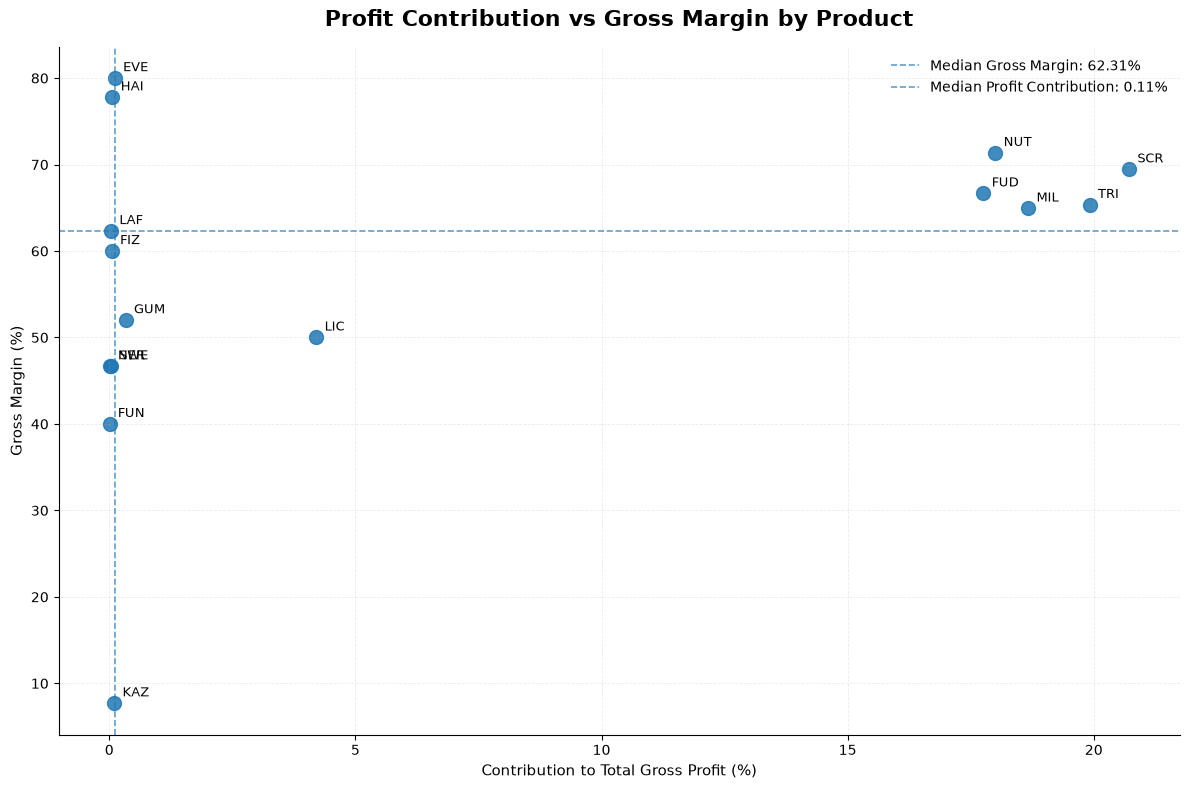


✔ Profit contribution vs gross margin visualization completed.


In [65]:
# ============================================================
# 56. PROFIT CONTRIBUTION VS GROSS MARGIN
# ============================================================

# Combine product-level gross profit and margin metrics
profit_margin_analysis = (
    df_clean
    .groupby(["Product ID", "Product Name"], as_index=False)
    .agg(
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross Profit", "sum")
    )
)

# Calculate Gross Margin
profit_margin_analysis["Gross Margin (%)"] = (
    profit_margin_analysis["Gross_Profit"] /
    profit_margin_analysis["Sales"]
) * 100

# Calculate Profit Contribution
profit_margin_analysis["Profit Contribution (%)"] = (
    profit_margin_analysis["Gross_Profit"] /
    profit_margin_analysis["Gross_Profit"].sum()
) * 100

# Create short product codes
profit_margin_analysis["Product Code"] = (
    profit_margin_analysis["Product ID"]
    .str.split("-")
    .str[1]
)

# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 8))

ax.scatter(
    profit_margin_analysis["Profit Contribution (%)"],
    profit_margin_analysis["Gross Margin (%)"],
    s=100,
    alpha=0.85
)

# Add product-code labels
for _, row in profit_margin_analysis.iterrows():

    ax.annotate(
        row["Product Code"],
        (
            row["Profit Contribution (%)"],
            row["Gross Margin (%)"]
        ),
        xytext=(6, 5),
        textcoords="offset points",
        fontsize=9
    )

# Portfolio median benchmarks
profit_contribution_median = (
    profit_margin_analysis["Profit Contribution (%)"].median()
)

ax.axhline(
    y=margin_median,
    linestyle="--",
    linewidth=1.2,
    alpha=0.7,
    label=f"Median Gross Margin: {margin_median:.2f}%"
)

ax.axvline(
    x=profit_contribution_median,
    linestyle="--",
    linewidth=1.2,
    alpha=0.7,
    label=f"Median Profit Contribution: {profit_contribution_median:.2f}%"
)

# Titles and labels
ax.set_title(
    "Profit Contribution vs Gross Margin by Product",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Contribution to Total Gross Profit (%)",
    fontsize=11
)

ax.set_ylabel(
    "Gross Margin (%)",
    fontsize=11
)

# Clean formatting
ax.grid(
    linestyle="--",
    linewidth=0.6,
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    frameon=False,
    loc="best"
)

plt.tight_layout()
plt.show()

print("\n✔ Profit contribution vs gross margin visualization completed.")

## 57. Product Profitability Summary

This table consolidates the key product-level profitability metrics into a single analytical view.

The summary includes:

- Sales
- Gross Profit
- Gross Margin (%)
- Cost-to-Sales (%)
- Profit Contribution (%)

This consolidated view provides a dashboard- and report-ready reference for comparing product scale, profitability efficiency, cost burden, and contribution to overall portfolio profit.

In [66]:
# ============================================================
# 57. PRODUCT PROFITABILITY SUMMARY
# ============================================================

# Build a consolidated product-level profitability table
product_profitability_summary = (
    df_clean
    .groupby(["Product ID", "Product Name"], as_index=False)
    .agg(
        Sales=("Sales", "sum"),
        Cost=("Cost", "sum"),
        Gross_Profit=("Gross Profit", "sum")
    )
)

# Calculate profitability metrics
product_profitability_summary["Gross Margin (%)"] = (
    product_profitability_summary["Gross_Profit"] /
    product_profitability_summary["Sales"]
) * 100

product_profitability_summary["Cost-to-Sales (%)"] = (
    product_profitability_summary["Cost"] /
    product_profitability_summary["Sales"]
) * 100

product_profitability_summary["Profit Contribution (%)"] = (
    product_profitability_summary["Gross_Profit"] /
    product_profitability_summary["Gross_Profit"].sum()
) * 100

# Sort by Gross Profit contribution
product_profitability_summary = (
    product_profitability_summary
    .sort_values("Gross_Profit", ascending=False)
    .reset_index(drop=True)
)

# Display rounded analytical table
display(
    product_profitability_summary[
        [
            "Product ID",
            "Product Name",
            "Sales",
            "Cost",
            "Gross_Profit",
            "Gross Margin (%)",
            "Cost-to-Sales (%)",
            "Profit Contribution (%)"
        ]
    ].style
    .format({
        "Sales": "{:,.2f}",
        "Cost": "{:,.2f}",
        "Gross_Profit": "{:,.2f}",
        "Gross Margin (%)": "{:.2f}%",
        "Cost-to-Sales (%)": "{:.2f}%",
        "Profit Contribution (%)": "{:.2f}%"
    })
)

print("\n✔ Product profitability summary created.")

,Product ID,Product Name,Sales,Cost,Gross_Profit,Gross Margin (%),Cost-to-Sales (%),Profit Contribution (%)
0,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,"27,874.80","8,517.30","19,357.50",69.44%,30.56%,20.72%
1,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,"28,485.00","9,874.80","18,610.20",65.33%,34.67%,19.92%
2,CHO-MIL-31000,Wonka Bar - Milk Chocolate,"26,867.75","9,424.38","17,443.37",64.92%,35.08%,18.67%
3,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,"23,574.95","6,755.00","16,819.95",71.35%,28.65%,18.00%
4,CHO-FUD-51000,Wonka Bar - Fudge Mallows,"24,890.40","8,296.80","16,593.60",66.67%,33.33%,17.76%
5,OTH-LIC-15000,Lickable Wallpaper,"7,860.00","3,930.00","3,930.00",50.00%,50.00%,4.21%
6,OTH-GUM-21000,Wonka Gum,597.50,286.80,310.70,52.00%,48.00%,0.33%
7,SUG-EVE-47000,Everlasting Gobstopper,130.00,26.00,104.00,80.00%,20.00%,0.11%
8,OTH-KAZ-38000,Kazookles,"1,205.75","1,113.00",92.75,7.69%,92.31%,0.10%
9,SUG-HAI-55000,Hair Toffee,76.50,17.00,59.50,77.78%,22.22%,0.06%



✔ Product profitability summary created.


## 58. Product Profitability Segment Contribution

This analysis summarizes the financial contribution of the four product profitability segments:

- High Sales / High Margin
- High Sales / Low Margin
- Low Sales / High Margin
- Low Sales / Low Margin

The objective is to quantify how each segment contributes to total Sales and Gross Profit and to identify where portfolio profitability is concentrated.

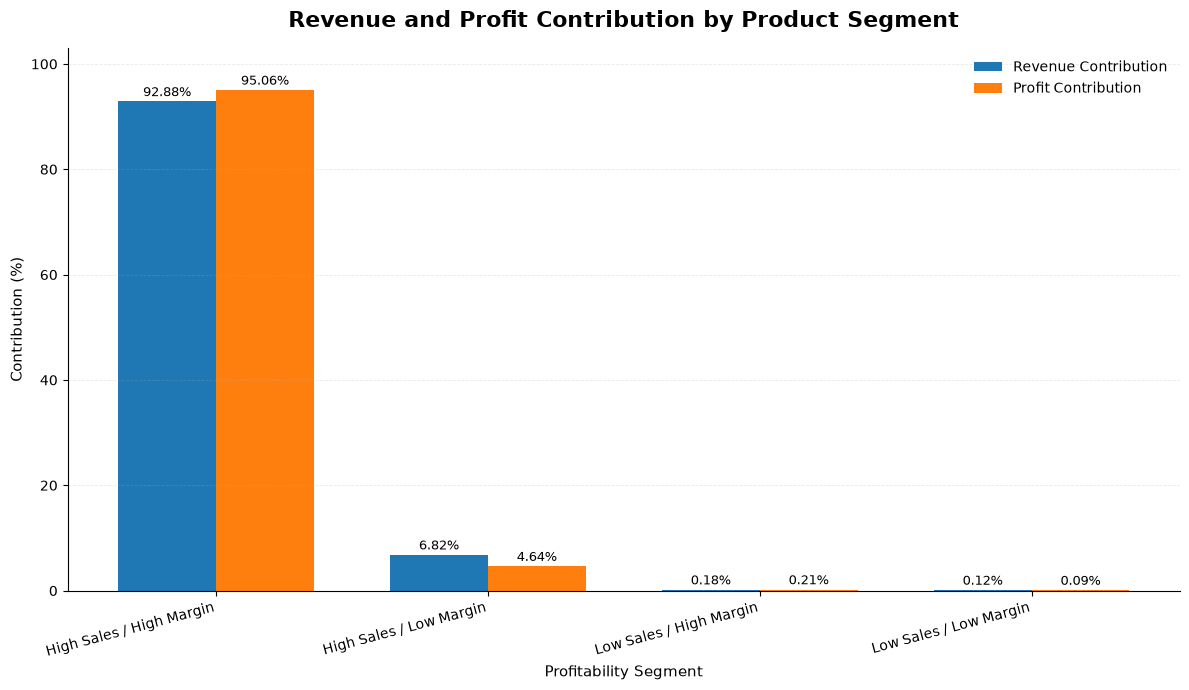


✔ Product profitability segment contribution visualization completed.


In [68]:
# ============================================================
# 58. PRODUCT PROFITABILITY SEGMENT CONTRIBUTION
# ============================================================

# ------------------------------------------------------------
# Step 1: Create product-level profitability data
# ------------------------------------------------------------

product_segment_data = (
    df_clean
    .groupby(["Product ID", "Product Name"], as_index=False)
    .agg(
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross Profit", "sum")
    )
)

# Calculate product-level Gross Margin
product_segment_data["Gross Margin (%)"] = (
    product_segment_data["Gross_Profit"] /
    product_segment_data["Sales"]
) * 100

# ------------------------------------------------------------
# Step 2: Assign profitability segments
# ------------------------------------------------------------

product_segment_data["Profitability Segment"] = np.select(
    [
        (
            (product_segment_data["Sales"] >= sales_median) &
            (product_segment_data["Gross Margin (%)"] >= margin_median)
        ),
        (
            (product_segment_data["Sales"] >= sales_median) &
            (product_segment_data["Gross Margin (%)"] < margin_median)
        ),
        (
            (product_segment_data["Sales"] < sales_median) &
            (product_segment_data["Gross Margin (%)"] >= margin_median)
        )
    ],
    [
        "High Sales / High Margin",
        "High Sales / Low Margin",
        "Low Sales / High Margin"
    ],
    default="Low Sales / Low Margin"
)

# ------------------------------------------------------------
# Step 3: Aggregate performance by segment
# ------------------------------------------------------------

segment_contribution = (
    product_segment_data
    .groupby("Profitability Segment", as_index=False)
    .agg(
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross_Profit", "sum")
    )
)

# Calculate contribution percentages
segment_contribution["Revenue Contribution (%)"] = (
    segment_contribution["Sales"] /
    segment_contribution["Sales"].sum()
) * 100

segment_contribution["Profit Contribution (%)"] = (
    segment_contribution["Gross_Profit"] /
    segment_contribution["Gross_Profit"].sum()
) * 100

# ------------------------------------------------------------
# Step 4: Maintain logical segment order
# ------------------------------------------------------------

segment_order = [
    "High Sales / High Margin",
    "High Sales / Low Margin",
    "Low Sales / High Margin",
    "Low Sales / Low Margin"
]

segment_contribution["Profitability Segment"] = pd.Categorical(
    segment_contribution["Profitability Segment"],
    categories=segment_order,
    ordered=True
)

segment_contribution = (
    segment_contribution
    .sort_values("Profitability Segment")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Step 5: Visualization
# ------------------------------------------------------------

x = np.arange(len(segment_contribution))
width = 0.36

fig, ax = plt.subplots(figsize=(12, 7))

ax.bar(
    x - width / 2,
    segment_contribution["Revenue Contribution (%)"],
    width,
    label="Revenue Contribution"
)

ax.bar(
    x + width / 2,
    segment_contribution["Profit Contribution (%)"],
    width,
    label="Profit Contribution"
)

# Add percentage labels
for i, row in segment_contribution.iterrows():

    ax.text(
        i - width / 2,
        row["Revenue Contribution (%)"] + 1,
        f'{row["Revenue Contribution (%)"]:.2f}%',
        ha="center",
        fontsize=9
    )

    ax.text(
        i + width / 2,
        row["Profit Contribution (%)"] + 1,
        f'{row["Profit Contribution (%)"]:.2f}%',
        ha="center",
        fontsize=9
    )

# Titles and labels
ax.set_title(
    "Revenue and Profit Contribution by Product Segment",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_ylabel(
    "Contribution (%)",
    fontsize=11
)

ax.set_xlabel(
    "Profitability Segment",
    fontsize=11
)

ax.set_xticks(x)

ax.set_xticklabels(
    segment_contribution["Profitability Segment"],
    rotation=15,
    ha="right"
)

# Clean formatting
ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.6,
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    frameon=False
)

ax.set_ylim(
    0,
    segment_contribution[
        ["Revenue Contribution (%)", "Profit Contribution (%)"]
    ].max().max() + 8
)

plt.tight_layout()
plt.show()

print("\n✔ Product profitability segment contribution visualization completed.")

## 59. Product Sales vs Gross Profit

This analysis compares product-level Sales with Gross Profit to evaluate the relationship between revenue scale and absolute profitability.

The visualization helps distinguish products that generate substantial revenue and gross profit from products with relatively limited financial contribution.

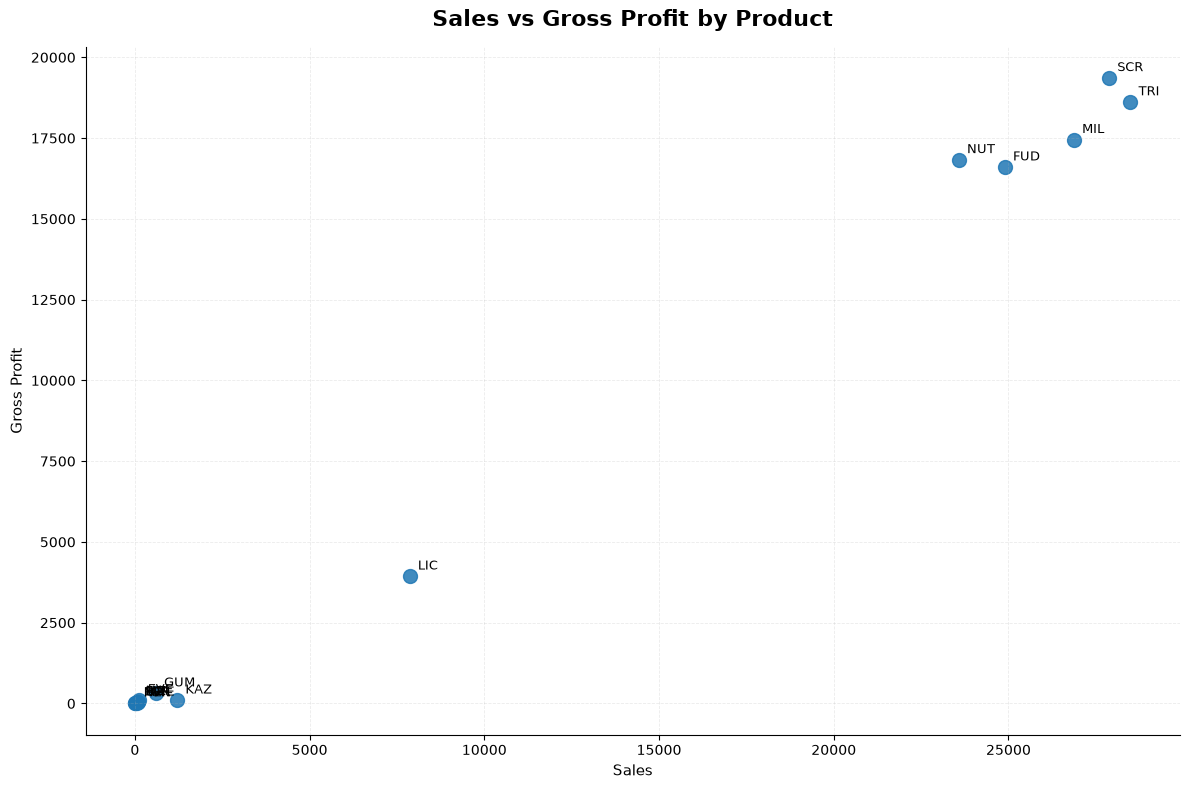


✔ Product sales vs gross profit visualization completed.


In [69]:
# ============================================================
# 59. PRODUCT SALES VS GROSS PROFIT
# ============================================================

# Aggregate product-level Sales and Gross Profit
sales_profit_analysis = (
    df_clean
    .groupby(["Product ID", "Product Name"], as_index=False)
    .agg(
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross Profit", "sum")
    )
)

# Create short product codes for clean labels
sales_profit_analysis["Product Code"] = (
    sales_profit_analysis["Product ID"]
    .str.split("-")
    .str[1]
)

# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 8))

ax.scatter(
    sales_profit_analysis["Sales"],
    sales_profit_analysis["Gross_Profit"],
    s=100,
    alpha=0.85
)

# Add product-code labels
for _, row in sales_profit_analysis.iterrows():

    ax.annotate(
        row["Product Code"],
        (
            row["Sales"],
            row["Gross_Profit"]
        ),
        xytext=(6, 5),
        textcoords="offset points",
        fontsize=9
    )

# Titles and labels
ax.set_title(
    "Sales vs Gross Profit by Product",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Sales",
    fontsize=11
)

ax.set_ylabel(
    "Gross Profit",
    fontsize=11
)

# Clean formatting
ax.grid(
    linestyle="--",
    linewidth=0.6,
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

print("\n✔ Product sales vs gross profit visualization completed.")

## 60. Product Profitability Findings

This section summarizes the key product-level profitability findings using the validated analytical metrics.

The analysis focuses on:

- Highest gross profit contributors
- Highest-margin products
- Highest cost-burden products
- Products with meaningful sales exposure and below-median margins
- Overall concentration of portfolio profitability

These findings provide the analytical basis for the executive summary and dashboard insights.

In [70]:
# ============================================================
# 60. PRODUCT PROFITABILITY FINDINGS
# ============================================================

# Create a consolidated findings dataset
product_findings = product_profitability_summary.copy()

# ------------------------------------------------------------
# 1. Top Gross Profit Contributors
# ------------------------------------------------------------

top_profit_products = (
    product_findings
    .nlargest(5, "Gross_Profit")
    [
        [
            "Product Name",
            "Sales",
            "Gross_Profit",
            "Gross Margin (%)",
            "Profit Contribution (%)"
        ]
    ]
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 2. Highest Gross Margin Products
# ------------------------------------------------------------

top_margin_products = (
    product_findings
    .nlargest(5, "Gross Margin (%)")
    [
        [
            "Product Name",
            "Gross Margin (%)",
            "Sales",
            "Profit Contribution (%)"
        ]
    ]
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 3. Highest Cost-Burden Products
# ------------------------------------------------------------

high_cost_products = (
    product_findings
    .nlargest(5, "Cost-to-Sales (%)")
    [
        [
            "Product Name",
            "Cost-to-Sales (%)",
            "Gross Margin (%)",
            "Sales"
        ]
    ]
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 4. High-Sales / Below-Median-Margin Products
# ------------------------------------------------------------

high_sales_low_margin = (
    product_findings[
        (product_findings["Sales"] >= sales_median) &
        (product_findings["Gross Margin (%)"] < margin_median)
    ]
    [
        [
            "Product Name",
            "Sales",
            "Gross Margin (%)",
            "Profit Contribution (%)"
        ]
    ]
    .sort_values("Sales", ascending=False)
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Display Findings
# ------------------------------------------------------------

print("=" * 70)
print("TOP 5 GROSS PROFIT CONTRIBUTORS")
print("=" * 70)

display(
    top_profit_products.style.format({
        "Sales": "{:,.2f}",
        "Gross_Profit": "{:,.2f}",
        "Gross Margin (%)": "{:.2f}%",
        "Profit Contribution (%)": "{:.2f}%"
    })
)

print("\n" + "=" * 70)
print("TOP 5 GROSS MARGIN PRODUCTS")
print("=" * 70)

display(
    top_margin_products.style.format({
        "Gross Margin (%)": "{:.2f}%",
        "Sales": "{:,.2f}",
        "Profit Contribution (%)": "{:.2f}%"
    })
)

print("\n" + "=" * 70)
print("TOP 5 COST-BURDEN PRODUCTS")
print("=" * 70)

display(
    high_cost_products.style.format({
        "Cost-to-Sales (%)": "{:.2f}%",
        "Gross Margin (%)": "{:.2f}%",
        "Sales": "{:,.2f}"
    })
)

print("\n" + "=" * 70)
print("HIGH-SALES / BELOW-MEDIAN-MARGIN PRODUCTS")
print("=" * 70)

display(
    high_sales_low_margin.style.format({
        "Sales": "{:,.2f}",
        "Gross Margin (%)": "{:.2f}%",
        "Profit Contribution (%)": "{:.2f}%"
    })
)

print("\n✔ Product profitability findings generated.")

TOP 5 GROSS PROFIT CONTRIBUTORS


,Product Name,Sales,Gross_Profit,Gross Margin (%),Profit Contribution (%)
0,Wonka Bar -Scrumdiddlyumptious,"27,874.80","19,357.50",69.44%,20.72%
1,Wonka Bar - Triple Dazzle Caramel,"28,485.00","18,610.20",65.33%,19.92%
2,Wonka Bar - Milk Chocolate,"26,867.75","17,443.37",64.92%,18.67%
3,Wonka Bar - Nutty Crunch Surprise,"23,574.95","16,819.95",71.35%,18.00%
4,Wonka Bar - Fudge Mallows,"24,890.40","16,593.60",66.67%,17.76%



TOP 5 GROSS MARGIN PRODUCTS


,Product Name,Gross Margin (%),Sales,Profit Contribution (%)
0,Everlasting Gobstopper,80.00%,130.00,0.11%
1,Hair Toffee,77.78%,76.50,0.06%
2,Wonka Bar - Nutty Crunch Surprise,71.35%,"23,574.95",18.00%
3,Wonka Bar -Scrumdiddlyumptious,69.44%,"27,874.80",20.72%
4,Wonka Bar - Fudge Mallows,66.67%,"24,890.40",17.76%



TOP 5 COST-BURDEN PRODUCTS


,Product Name,Cost-to-Sales (%),Gross Margin (%),Sales
0,Kazookles,92.31%,7.69%,"1,205.75"
1,Fun Dip,60.00%,40.00%,12.00
2,SweeTARTS,53.33%,46.67%,61.50
3,Nerds,53.33%,46.67%,15.00
4,Lickable Wallpaper,50.00%,50.00%,"7,860.00"



HIGH-SALES / BELOW-MEDIAN-MARGIN PRODUCTS


,Product Name,Sales,Gross Margin (%),Profit Contribution (%)
0,Lickable Wallpaper,"7,860.00",50.00%,4.21%
1,Kazookles,"1,205.75",7.69%,0.10%
2,Wonka Gum,597.50,52.00%,0.33%



✔ Product profitability findings generated.


## 61. Product-Level Analysis Validation

This validation confirms that the product-level analytical outputs reconcile with the validated transaction-level dataset.

The checks include:

- Product count
- Sales reconciliation
- Gross Profit reconciliation
- Profit Contribution reconciliation
- Gross Margin validity
- Cost-to-Sales validity
- No missing or infinite analytical values

A successful validation confirms that the product-level analysis is internally consistent and ready for downstream reporting and dashboard development.

In [71]:
# ============================================================
# 61. PRODUCT-LEVEL ANALYSIS VALIDATION
# ============================================================

# ------------------------------------------------------------
# 1. Product count
# ------------------------------------------------------------

product_count = product_profitability_summary["Product ID"].nunique()

# ------------------------------------------------------------
# 2. Sales reconciliation
# ------------------------------------------------------------

product_sales_total = product_profitability_summary["Sales"].sum()
dataset_sales_total = df_clean["Sales"].sum()

sales_reconciled = np.isclose(
    product_sales_total,
    dataset_sales_total
)

# ------------------------------------------------------------
# 3. Gross Profit reconciliation
# ------------------------------------------------------------

product_profit_total = product_profitability_summary["Gross_Profit"].sum()
dataset_profit_total = df_clean["Gross Profit"].sum()

profit_reconciled = np.isclose(
    product_profit_total,
    dataset_profit_total
)

# ------------------------------------------------------------
# 4. Profit contribution reconciliation
# ------------------------------------------------------------

profit_contribution_total = (
    product_profitability_summary["Profit Contribution (%)"].sum()
)

contribution_reconciled = np.isclose(
    profit_contribution_total,
    100.0
)

# ------------------------------------------------------------
# 5. Gross Margin validity
# ------------------------------------------------------------

margin_valid = (
    product_profitability_summary["Gross Margin (%)"]
    .between(0, 100)
    .all()
)

# ------------------------------------------------------------
# 6. Cost-to-Sales validity
# ------------------------------------------------------------

cost_sales_valid = (
    product_profitability_summary["Cost-to-Sales (%)"]
    .between(0, 100)
    .all()
)

# ------------------------------------------------------------
# 7. Missing / infinite values
# ------------------------------------------------------------

analysis_columns = [
    "Sales",
    "Cost",
    "Gross_Profit",
    "Gross Margin (%)",
    "Cost-to-Sales (%)",
    "Profit Contribution (%)"
]

missing_values = (
    product_profitability_summary[analysis_columns]
    .isna()
    .sum()
    .sum()
)

infinite_values = np.isinf(
    product_profitability_summary[analysis_columns]
).sum().sum()

# ------------------------------------------------------------
# Validation Summary
# ------------------------------------------------------------

validation_results = pd.DataFrame({
    "Validation Check": [
        "Product count",
        "Sales reconciliation",
        "Gross Profit reconciliation",
        "Profit contribution = 100%",
        "Gross Margin within 0–100%",
        "Cost-to-Sales within 0–100%",
        "Missing analytical values",
        "Infinite analytical values"
    ],
    "Result": [
        f"{product_count} products",
        "PASS" if sales_reconciled else "FAIL",
        "PASS" if profit_reconciled else "FAIL",
        "PASS" if contribution_reconciled else "FAIL",
        "PASS" if margin_valid else "FAIL",
        "PASS" if cost_sales_valid else "FAIL",
        f"{missing_values}",
        f"{infinite_values}"
    ]
})

display(validation_results)

# Final validation status
all_checks_passed = (
    product_count == 15
    and sales_reconciled
    and profit_reconciled
    and contribution_reconciled
    and margin_valid
    and cost_sales_valid
    and missing_values == 0
    and infinite_values == 0
)

if all_checks_passed:
    print("\n✔ Product-level analysis validation PASSED.")
else:
    print("\n⚠ Product-level analysis validation requires review.")

,Validation Check,Result
0,Product count,15 products
1,Sales reconciliation,PASS
2,Gross Profit reconciliation,PASS
3,Profit contribution = 100%,PASS
4,Gross Margin within 0–100%,PASS
5,Cost-to-Sales within 0–100%,PASS
6,Missing analytical values,0
7,Infinite analytical values,0



✔ Product-level analysis validation PASSED.


## 62. Portfolio Profitability Summary

This section consolidates the primary portfolio-level financial metrics into a single summary view.

The summary provides the overall Sales, Cost, Gross Profit, Units, Gross Margin, and Profit per Unit for the complete dataset.

These metrics establish the financial baseline for the final business findings and executive reporting.

In [72]:
# ============================================================
# 62. PORTFOLIO PROFITABILITY SUMMARY
# ============================================================

# Calculate core portfolio-level metrics
total_sales = df_clean["Sales"].sum()
total_cost = df_clean["Cost"].sum()
total_gross_profit = df_clean["Gross Profit"].sum()
total_units = df_clean["Units"].sum()

# Calculate portfolio profitability metrics
overall_gross_margin = (
    total_gross_profit /
    total_sales
) * 100

overall_profit_per_unit = (
    total_gross_profit /
    total_units
)

# Create a compact portfolio KPI table
portfolio_summary = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Cost",
        "Total Gross Profit",
        "Total Units",
        "Overall Gross Margin (%)",
        "Overall Profit per Unit"
    ],
    "Value": [
        total_sales,
        total_cost,
        total_gross_profit,
        total_units,
        overall_gross_margin,
        overall_profit_per_unit
    ]
})

# Display formatted summary
display(
    portfolio_summary.style.format({
        "Value": lambda x: (
            f"{x:,.2f}"
            if x < 1000
            else f"{x:,.2f}"
        )
    })
)

print("\n✔ Portfolio profitability summary created.")

,Metric,Value
0,Total Sales,"141,783.63"
1,Total Cost,"48,340.83"
2,Total Gross Profit,"93,442.80"
3,Total Units,"38,654.00"
4,Overall Gross Margin (%),65.91
5,Overall Profit per Unit,2.42



✔ Portfolio profitability summary created.


## 63. Portfolio KPI Validation

This validation confirms that the portfolio-level profitability KPIs reconcile directly with the validated transaction-level dataset.

The checks include:

- Total Sales
- Total Cost
- Total Gross Profit
- Total Units
- Gross Profit = Sales − Cost
- Overall Gross Margin
- Profit per Unit

All calculated KPIs must reconcile before they are used in the final executive analysis.

In [73]:
# ============================================================
# 63. PORTFOLIO KPI VALIDATION
# ============================================================

# ------------------------------------------------------------
# Calculate totals directly from validated transaction data
# ------------------------------------------------------------

validation_sales = df_clean["Sales"].sum()
validation_cost = df_clean["Cost"].sum()
validation_profit = df_clean["Gross Profit"].sum()
validation_units = df_clean["Units"].sum()

# Calculate derived KPIs
validation_margin = (
    validation_profit /
    validation_sales
) * 100

validation_profit_per_unit = (
    validation_profit /
    validation_units
)

# ------------------------------------------------------------
# Reconciliation checks
# ------------------------------------------------------------

sales_check = np.isclose(
    total_sales,
    validation_sales
)

cost_check = np.isclose(
    total_cost,
    validation_cost
)

profit_check = np.isclose(
    total_gross_profit,
    validation_profit
)

units_check = np.isclose(
    total_units,
    validation_units
)

gross_profit_formula_check = np.isclose(
    validation_profit,
    validation_sales - validation_cost
)

margin_check = np.isclose(
    overall_gross_margin,
    validation_margin
)

ppu_check = np.isclose(
    overall_profit_per_unit,
    validation_profit_per_unit
)

# ------------------------------------------------------------
# Validation summary
# ------------------------------------------------------------

portfolio_validation = pd.DataFrame({
    "Validation Check": [
        "Total Sales",
        "Total Cost",
        "Total Gross Profit",
        "Total Units",
        "Gross Profit = Sales - Cost",
        "Overall Gross Margin",
        "Overall Profit per Unit"
    ],
    "Result": [
        "PASS" if sales_check else "FAIL",
        "PASS" if cost_check else "FAIL",
        "PASS" if profit_check else "FAIL",
        "PASS" if units_check else "FAIL",
        "PASS" if gross_profit_formula_check else "FAIL",
        "PASS" if margin_check else "FAIL",
        "PASS" if ppu_check else "FAIL"
    ]
})

display(portfolio_validation)

# Final validation status
all_portfolio_checks_passed = (
    sales_check
    and cost_check
    and profit_check
    and units_check
    and gross_profit_formula_check
    and margin_check
    and ppu_check
)

if all_portfolio_checks_passed:
    print("\n✔ Portfolio KPI validation PASSED.")
else:
    print("\n⚠ Portfolio KPI validation requires review.")

,Validation Check,Result
0,Total Sales,PASS
1,Total Cost,PASS
2,Total Gross Profit,PASS
3,Total Units,PASS
4,Gross Profit = Sales - Cost,PASS
5,Overall Gross Margin,PASS
6,Overall Profit per Unit,PASS



✔ Portfolio KPI validation PASSED.


## 64. Portfolio-Level Findings

This section summarizes the key portfolio-level findings derived from the validated profitability analysis.

The findings focus on:

- Overall profitability
- Profit concentration
- Product and division contribution
- Margin performance
- Cost burden
- Portfolio concentration risk

These findings will form the analytical foundation for the Executive Summary, dashboard insights, and final project recommendations.

In [74]:
# ============================================================
# 64. PORTFOLIO-LEVEL FINDINGS
# ============================================================

# ------------------------------------------------------------
# Core portfolio metrics
# ------------------------------------------------------------

portfolio_metrics = {
    "Total Sales": total_sales,
    "Total Cost": total_cost,
    "Total Gross Profit": total_gross_profit,
    "Total Units": total_units,
    "Overall Gross Margin (%)": overall_gross_margin,
    "Profit per Unit": overall_profit_per_unit
}

# ------------------------------------------------------------
# Profit concentration
# ------------------------------------------------------------

top_5_profit_contribution = (
    product_profitability_summary
    .nlargest(5, "Gross_Profit")["Profit Contribution (%)"]
    .sum()
)

top_4_profit_contribution = (
    product_profitability_summary
    .nlargest(4, "Gross_Profit")["Profit Contribution (%)"]
    .sum()
)

# ------------------------------------------------------------
# Revenue concentration
# ------------------------------------------------------------

top_5_revenue_contribution = (
    product_profitability_summary
    .nlargest(5, "Sales")["Sales"]
    .sum()
    / total_sales
) * 100

# ------------------------------------------------------------
# Division concentration
# ------------------------------------------------------------

division_profit_contribution = (
    df_clean
    .groupby("Division")["Gross Profit"]
    .sum()
    .sort_values(ascending=False)
)

# ------------------------------------------------------------
# Display findings
# ------------------------------------------------------------

portfolio_findings = pd.DataFrame({
    "Finding": [
        "Overall Gross Margin",
        "Profit per Unit",
        "Top 4 Products — Gross Profit Contribution",
        "Top 5 Products — Gross Profit Contribution",
        "Top 5 Products — Revenue Contribution",
        "Largest Division — Gross Profit Contribution"
    ],
    "Value": [
        f"{overall_gross_margin:.2f}%",
        f"{overall_profit_per_unit:.2f}",
        f"{top_4_profit_contribution:.2f}%",
        f"{top_5_profit_contribution:.2f}%",
        f"{top_5_revenue_contribution:.2f}%",
        f"{division_profit_contribution.index[0]} — "
        f"{division_profit_contribution.iloc[0] / total_gross_profit * 100:.2f}%"
    ]
})

display(portfolio_findings)

print("\n✔ Portfolio-level findings generated.")

,Finding,Value
0,Overall Gross Margin,65.91%
1,Profit per Unit,2.42
2,Top 4 Products — Gross Profit Contribution,77.30%
3,Top 5 Products — Gross Profit Contribution,95.06%
4,Top 5 Products — Revenue Contribution,92.88%
5,Largest Division — Gross Profit Contribution,Chocolate — 95.06%



✔ Portfolio-level findings generated.


## 65. Monthly Revenue and Gross Profit Trend

This analysis examines the monthly movement of Sales and Gross Profit across the analysis period.

The objective is to identify changes in portfolio revenue scale and absolute profitability over time while preserving the monthly time-series structure.

Both metrics are aggregated using Order Date.

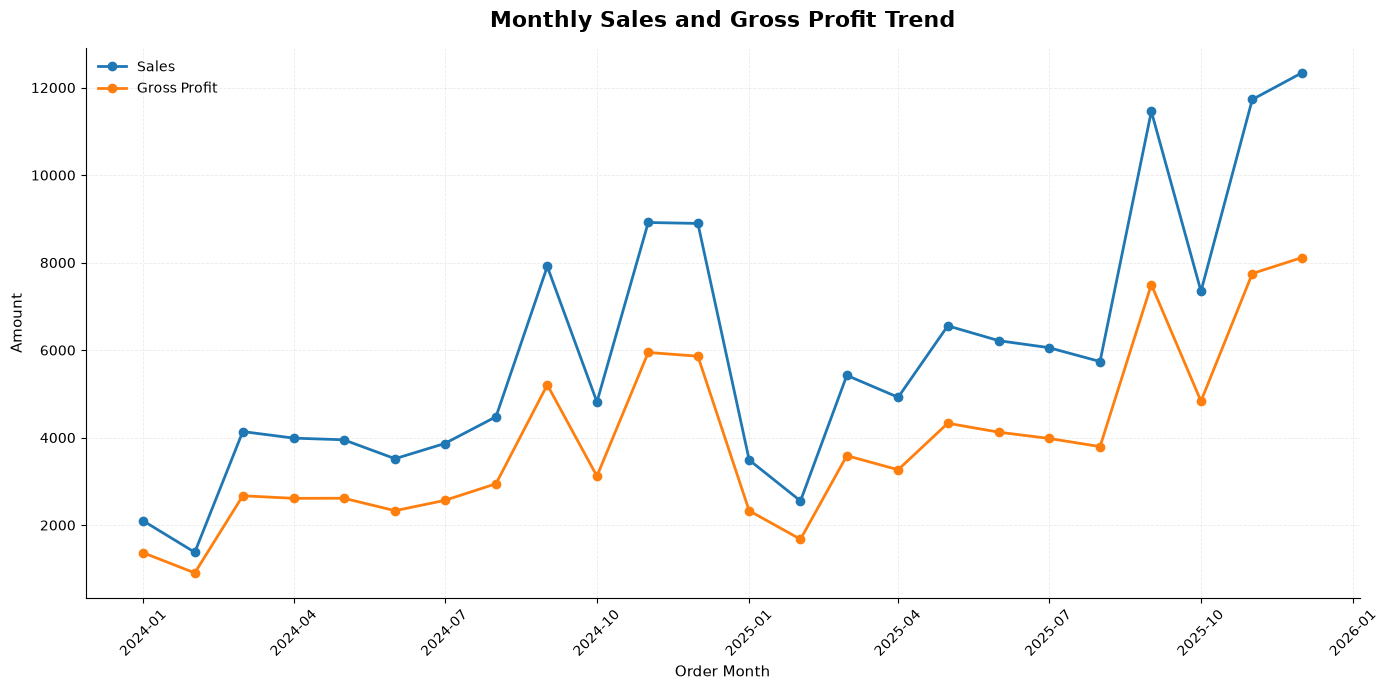


✔ Monthly revenue and gross profit trend completed.


In [75]:
# ============================================================
# 65. MONTHLY REVENUE AND GROSS PROFIT TREND
# ============================================================

# Create monthly portfolio aggregation
monthly_portfolio = (
    df_clean
    .assign(Order_Month=df_clean["Order Date"].dt.to_period("M"))
    .groupby("Order_Month", as_index=False)
    .agg(
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross Profit", "sum")
    )
)

# Convert Period to timestamp for plotting
monthly_portfolio["Order_Month"] = (
    monthly_portfolio["Order_Month"].dt.to_timestamp()
)

# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 7))

ax.plot(
    monthly_portfolio["Order_Month"],
    monthly_portfolio["Sales"],
    marker="o",
    linewidth=2,
    label="Sales"
)

ax.plot(
    monthly_portfolio["Order_Month"],
    monthly_portfolio["Gross_Profit"],
    marker="o",
    linewidth=2,
    label="Gross Profit"
)

# Titles and labels
ax.set_title(
    "Monthly Sales and Gross Profit Trend",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Order Month",
    fontsize=11
)

ax.set_ylabel(
    "Amount",
    fontsize=11
)

# Clean formatting
ax.grid(
    linestyle="--",
    linewidth=0.6,
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    frameon=False
)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

print("\n✔ Monthly revenue and gross profit trend completed.")

## 66. Monthly Performance Summary

This section summarizes the monthly portfolio performance across the analysis period.

The analysis identifies:

- Average monthly Sales
- Highest and lowest Sales months
- Average monthly Gross Profit
- Highest and lowest Gross Profit months
- Average monthly Gross Margin

These metrics provide a concise view of portfolio performance variation over time and support the final business findings.

In [76]:
# ============================================================
# 66. MONTHLY PERFORMANCE SUMMARY
# ============================================================

# Create monthly portfolio metrics
monthly_performance = (
    df_clean
    .assign(Order_Month=df_clean["Order Date"].dt.to_period("M"))
    .groupby("Order_Month", as_index=False)
    .agg(
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross Profit", "sum")
    )
)

# Calculate monthly Gross Margin
monthly_performance["Gross Margin (%)"] = (
    monthly_performance["Gross_Profit"] /
    monthly_performance["Sales"]
) * 100

# ------------------------------------------------------------
# Identify key monthly performance points
# ------------------------------------------------------------

avg_monthly_sales = monthly_performance["Sales"].mean()
avg_monthly_profit = monthly_performance["Gross_Profit"].mean()
avg_monthly_margin = monthly_performance["Gross Margin (%)"].mean()

highest_sales_row = monthly_performance.loc[
    monthly_performance["Sales"].idxmax()
]

lowest_sales_row = monthly_performance.loc[
    monthly_performance["Sales"].idxmin()
]

highest_profit_row = monthly_performance.loc[
    monthly_performance["Gross_Profit"].idxmax()
]

lowest_profit_row = monthly_performance.loc[
    monthly_performance["Gross_Profit"].idxmin()
]

# ------------------------------------------------------------
# Create summary table
# ------------------------------------------------------------

monthly_summary = pd.DataFrame({
    "Metric": [
        "Average Monthly Sales",
        "Highest Monthly Sales",
        "Lowest Monthly Sales",
        "Average Monthly Gross Profit",
        "Highest Monthly Gross Profit",
        "Lowest Monthly Gross Profit",
        "Average Monthly Gross Margin"
    ],
    "Value": [
        f"{avg_monthly_sales:,.2f}",
        f"{highest_sales_row['Sales']:,.2f}",
        f"{lowest_sales_row['Sales']:,.2f}",
        f"{avg_monthly_profit:,.2f}",
        f"{highest_profit_row['Gross_Profit']:,.2f}",
        f"{lowest_profit_row['Gross_Profit']:,.2f}",
        f"{avg_monthly_margin:.2f}%"
    ],
    "Month": [
        "-",
        str(highest_sales_row["Order_Month"]),
        str(lowest_sales_row["Order_Month"]),
        "-",
        str(highest_profit_row["Order_Month"]),
        str(lowest_profit_row["Order_Month"]),
        "-"
    ]
})

display(monthly_summary)

print("\n✔ Monthly performance summary generated.")

,Metric,Value,Month
0,Average Monthly Sales,"5,907.65",-
1,Highest Monthly Sales,"12,338.27",2025-12
2,Lowest Monthly Sales,"1,379.87",2024-02
3,Average Monthly Gross Profit,"3,893.45",-
4,Highest Monthly Gross Profit,"8,115.95",2025-12
5,Lowest Monthly Gross Profit,908.59,2024-02
6,Average Monthly Gross Margin,65.88%,-



✔ Monthly performance summary generated.


## 67. Monthly Gross Margin Stability

This analysis evaluates the stability of the portfolio's Gross Margin (%) across the 24-month analysis period.

The objective is to determine whether changes in monthly Sales and Gross Profit were accompanied by meaningful changes in profitability efficiency.

The analysis reports the minimum, maximum, average, and range of monthly Gross Margin.

In [77]:
# ============================================================
# 67. MONTHLY GROSS MARGIN STABILITY
# ============================================================

# Use the monthly performance dataset created in Cell 66
monthly_margin = monthly_performance.copy()

# Calculate margin statistics
average_monthly_margin = (
    monthly_margin["Gross Margin (%)"].mean()
)

minimum_monthly_margin = (
    monthly_margin["Gross Margin (%)"].min()
)

maximum_monthly_margin = (
    monthly_margin["Gross Margin (%)"].max()
)

margin_range = (
    maximum_monthly_margin -
    minimum_monthly_margin
)

# Identify months with minimum and maximum margins
minimum_margin_row = monthly_margin.loc[
    monthly_margin["Gross Margin (%)"].idxmin()
]

maximum_margin_row = monthly_margin.loc[
    monthly_margin["Gross Margin (%)"].idxmax()
]

# ------------------------------------------------------------
# Summary table
# ------------------------------------------------------------

margin_stability_summary = pd.DataFrame({
    "Metric": [
        "Average Monthly Gross Margin",
        "Minimum Monthly Gross Margin",
        "Maximum Monthly Gross Margin",
        "Gross Margin Range"
    ],
    "Value": [
        f"{average_monthly_margin:.2f}%",
        f"{minimum_monthly_margin:.2f}%",
        f"{maximum_monthly_margin:.2f}%",
        f"{margin_range:.2f} percentage points"
    ],
    "Month": [
        "-",
        str(minimum_margin_row["Order_Month"]),
        str(maximum_margin_row["Order_Month"]),
        "-"
    ]
})

display(margin_stability_summary)

print("\n✔ Monthly gross margin stability analysis completed.")

,Metric,Value,Month
0,Average Monthly Gross Margin,65.88%,-
1,Minimum Monthly Gross Margin,64.54%,2024-03
2,Maximum Monthly Gross Margin,66.75%,2025-01
3,Gross Margin Range,2.21 percentage points,-



✔ Monthly gross margin stability analysis completed.


## 68. Executive-Level Analytical Findings

This section consolidates the most important findings from the validated profitability analysis into a concise executive-level view.

The findings cover:

- Portfolio profitability
- Profit concentration
- Revenue concentration
- Margin stability
- Cost burden
- High-sales / below-median-margin products
- Division-level profitability

These findings provide the quantitative foundation for the Executive Summary, dashboard narrative, and final business recommendations.

In [79]:
# ============================================================
# 68. EXECUTIVE-LEVEL ANALYTICAL FINDINGS
# ============================================================

# ------------------------------------------------------------
# Calculate key findings directly from validated data
# ------------------------------------------------------------

# Product-level aggregation
executive_product = (
    df_clean
    .groupby(["Product ID", "Product Name"], as_index=False)
    .agg(
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Cost=("Cost", "sum")
    )
)

# Product-level Gross Margin
executive_product["Gross Margin (%)"] = (
    executive_product["Gross_Profit"] /
    executive_product["Sales"]
) * 100

# Product-level Profit Contribution
executive_product["Profit Contribution (%)"] = (
    executive_product["Gross_Profit"] /
    total_gross_profit
) * 100

# Product-level Cost-to-Sales Ratio
executive_product["Cost-to-Sales (%)"] = (
    executive_product["Cost"] /
    executive_product["Sales"]
) * 100

# ------------------------------------------------------------
# Concentration metrics
# ------------------------------------------------------------

top_5_profit = (
    executive_product
    .nlargest(5, "Gross_Profit")["Profit Contribution (%)"]
    .sum()
)

top_5_revenue = (
    executive_product
    .nlargest(5, "Sales")["Sales"]
    .sum()
    / total_sales
) * 100

# ------------------------------------------------------------
# High-sales / below-median-margin exposure
# ------------------------------------------------------------

high_sales_low_margin = executive_product[
    (executive_product["Sales"] >= sales_median) &
    (executive_product["Gross Margin (%)"] < margin_median)
]

high_sales_low_margin_sales = (
    high_sales_low_margin["Sales"].sum()
)

# ------------------------------------------------------------
# Division-level profitability
# ------------------------------------------------------------

division_summary_exec = (
    df_clean
    .groupby("Division", as_index=False)
    .agg(
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross Profit", "sum")
    )
)

division_summary_exec["Profit Contribution (%)"] = (
    division_summary_exec["Gross_Profit"] /
    total_gross_profit
) * 100

largest_profit_division = division_summary_exec.loc[
    division_summary_exec["Gross_Profit"].idxmax()
]

# ------------------------------------------------------------
# Identify highest cost-burden product separately
# ------------------------------------------------------------

highest_cost_product = executive_product.loc[
    executive_product["Cost-to-Sales (%)"].idxmax()
]

highest_cost_product_name = highest_cost_product["Product Name"]
highest_cost_ratio = highest_cost_product["Cost-to-Sales (%)"]

# ------------------------------------------------------------
# Identify largest profit-contributing division
# ------------------------------------------------------------

largest_division_name = largest_profit_division["Division"]
largest_division_contribution = (
    largest_profit_division["Profit Contribution (%)"]
)

# ------------------------------------------------------------
# Executive findings table
# ------------------------------------------------------------

executive_findings = pd.DataFrame({
    "Finding": [
        "Overall Gross Margin",
        "Top 5 Products — Gross Profit Contribution",
        "Top 5 Products — Revenue Contribution",
        "Monthly Gross Margin Range",
        "Highest Cost-to-Sales Product",
        "High-Sales / Below-Median-Margin Sales Exposure",
        "Largest Profit-Contributing Division"
    ],

    "Value": [
        f"{overall_gross_margin:.2f}%",
        f"{top_5_profit:.2f}%",
        f"{top_5_revenue:.2f}%",
        f"{margin_range:.2f} percentage points",
        f"{highest_cost_product_name} — {highest_cost_ratio:.2f}%",
        f"{high_sales_low_margin_sales:,.2f}",
        f"{largest_division_name} — {largest_division_contribution:.2f}%"
    ]
})

display(executive_findings)

print("\n✔ Executive-level analytical findings generated.")

,Finding,Value
0,Overall Gross Margin,65.91%
1,Top 5 Products — Gross Profit Contribution,95.06%
2,Top 5 Products — Revenue Contribution,92.88%
3,Monthly Gross Margin Range,2.21 percentage points
4,Highest Cost-to-Sales Product,Kazookles — 92.31%
5,High-Sales / Below-Median-Margin Sales Exposure,"9,663.25"
6,Largest Profit-Contributing Division,Chocolate — 95.06%



✔ Executive-level analytical findings generated.


## 69. Final Analytical Conclusion

The profitability analysis demonstrates that the portfolio generates a strong overall gross margin, while profitability is highly concentrated among a small group of products.

The five largest gross-profit-contributing products account for 95.06% of total gross profit and 92.88% of total revenue. The Chocolate division represents the same 95.06% share of total gross profit.

Despite substantial month-to-month variation in Sales and Gross Profit, monthly Gross Margin remains relatively stable, with a range of only 2.21 percentage points across the 24-month analysis period.

The analysis also identifies meaningful differences in product-level cost burden. Kazookles has the highest Cost-to-Sales Ratio at 92.31%, while several high-sales products operate below the portfolio median gross margin of 62.31%.

Overall, the analysis indicates that portfolio profitability is driven primarily by a concentrated group of high-sales, high-margin Chocolate products, while a smaller set of products presents comparatively higher cost burden or lower margin efficiency.`

## 70. Business Recommendations

The following recommendations are derived directly from the validated profitability, margin, cost-burden, concentration, and segmentation analyses.

### 1. Protect the Core Chocolate Profit Drivers
The five major Chocolate products contribute 95.06% of total gross profit and 92.88% of total revenue. Their strong financial contribution makes them the primary products to monitor for sustained sales and margin performance.

### 2. Review High Cost-Burden Products
Kazookles has a Cost-to-Sales Ratio of 92.31% and a Gross Margin of only 7.69%. Other products with comparatively high cost burdens should also be reviewed for pricing, cost structure, or product economics.

### 3. Investigate High-Sales / Below-Median-Margin Products
Lickable Wallpaper, Kazookles, and Wonka Gum have sales at or above the portfolio median while their Gross Margins are below the portfolio median of 62.31%. Together, these products represent 9,663.25 in sales and warrant closer margin analysis.

### 4. Maintain Margin Monitoring
Monthly Gross Margin ranges from 64.54% to 66.75%, indicating relatively stable portfolio-level margin performance despite fluctuations in monthly Sales and Gross Profit. Monthly margin monitoring should therefore remain part of ongoing performance reporting.

### 5. Monitor Profit Concentration
The top five products account for 95.06% of total gross profit. This concentration should be explicitly monitored in management reporting because changes in the performance of these products can materially affect overall portfolio profitability.

### 6. Use Profitability Segmentation for Portfolio Management
The High Sales / High Margin segment contributes 92.88% of revenue and 95.06% of gross profit. The four-segment framework can therefore be used as a recurring management view to distinguish core profit drivers from products requiring margin or scale review.

## 71. Dashboard-Ready Data Preparation

This section prepares reusable analytical datasets for the Streamlit dashboard.

The dashboard will use these prepared datasets for:
- Portfolio KPI cards
- Product profitability analysis
- Division performance
- Monthly performance trends
- Pareto / profit concentration
- Profitability segmentation
- Margin risk diagnostics

The calculations are based on the validated `df_clean` dataset and reuse the analytical definitions established earlier in the notebook.

In [80]:
# ============================================================
# CELL 71 — DASHBOARD-READY DATA PREPARATION
# ============================================================

# ------------------------------------------------------------
# 1. Portfolio KPI Dataset
# ------------------------------------------------------------

dashboard_kpis = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Cost",
        "Total Gross Profit",
        "Total Units",
        "Gross Margin (%)",
        "Profit per Unit"
    ],
    "Value": [
        df_clean["Sales"].sum(),
        df_clean["Cost"].sum(),
        df_clean["Gross Profit"].sum(),
        df_clean["Units"].sum(),
        (df_clean["Gross Profit"].sum() / df_clean["Sales"].sum()) * 100,
        df_clean["Gross Profit"].sum() / df_clean["Units"].sum()
    ]
})


# ------------------------------------------------------------
# 2. Product Profitability Dataset
# ------------------------------------------------------------

dashboard_product = (
    df_clean
    .groupby(["Product ID", "Product Name", "Division"], as_index=False)
    .agg(
        Sales=("Sales", "sum"),
        Cost=("Cost", "sum"),
        Units=("Units", "sum"),
        Gross_Profit=("Gross Profit", "sum")
    )
)

# Product-level profitability metrics
dashboard_product["Gross Margin (%)"] = (
    dashboard_product["Gross_Profit"] /
    dashboard_product["Sales"] * 100
)

dashboard_product["Profit per Unit"] = (
    dashboard_product["Gross_Profit"] /
    dashboard_product["Units"]
)

dashboard_product["Cost-to-Sales (%)"] = (
    dashboard_product["Cost"] /
    dashboard_product["Sales"] * 100
)

dashboard_product["Revenue Contribution (%)"] = (
    dashboard_product["Sales"] /
    dashboard_product["Sales"].sum() * 100
)

dashboard_product["Profit Contribution (%)"] = (
    dashboard_product["Gross_Profit"] /
    dashboard_product["Gross_Profit"].sum() * 100
)


# ------------------------------------------------------------
# 3. Profitability Segmentation
# ------------------------------------------------------------

sales_median = dashboard_product["Sales"].median()
margin_median = dashboard_product["Gross Margin (%)"].median()

dashboard_product["Profitability Segment"] = np.select(
    [
        (dashboard_product["Sales"] >= sales_median) &
        (dashboard_product["Gross Margin (%)"] >= margin_median),

        (dashboard_product["Sales"] >= sales_median) &
        (dashboard_product["Gross Margin (%)"] < margin_median),

        (dashboard_product["Sales"] < sales_median) &
        (dashboard_product["Gross Margin (%)"] >= margin_median),

        (dashboard_product["Sales"] < sales_median) &
        (dashboard_product["Gross Margin (%)"] < margin_median)
    ],
    [
        "High Sales / High Margin",
        "High Sales / Low Margin",
        "Low Sales / High Margin",
        "Low Sales / Low Margin"
    ],
    default="Unclassified"
)


# ------------------------------------------------------------
# 4. Division Performance Dataset
# ------------------------------------------------------------

dashboard_division = (
    df_clean
    .groupby("Division", as_index=False)
    .agg(
        Sales=("Sales", "sum"),
        Cost=("Cost", "sum"),
        Units=("Units", "sum"),
        Gross_Profit=("Gross Profit", "sum")
    )
)

dashboard_division["Gross Margin (%)"] = (
    dashboard_division["Gross_Profit"] /
    dashboard_division["Sales"] * 100
)

dashboard_division["Profit per Unit"] = (
    dashboard_division["Gross_Profit"] /
    dashboard_division["Units"]
)

dashboard_division["Revenue Contribution (%)"] = (
    dashboard_division["Sales"] /
    dashboard_division["Sales"].sum() * 100
)

dashboard_division["Profit Contribution (%)"] = (
    dashboard_division["Gross_Profit"] /
    dashboard_division["Gross_Profit"].sum() * 100
)


# ------------------------------------------------------------
# 5. Monthly Performance Dataset
# ------------------------------------------------------------

dashboard_monthly = (
    df_clean
    .assign(Order_Month=df_clean["Order Date"].dt.to_period("M"))
    .groupby("Order_Month", as_index=False)
    .agg(
        Sales=("Sales", "sum"),
        Cost=("Cost", "sum"),
        Units=("Units", "sum"),
        Gross_Profit=("Gross Profit", "sum")
    )
)

dashboard_monthly["Order_Month"] = (
    dashboard_monthly["Order_Month"].dt.to_timestamp()
)

dashboard_monthly["Gross Margin (%)"] = (
    dashboard_monthly["Gross_Profit"] /
    dashboard_monthly["Sales"] * 100
)


# ------------------------------------------------------------
# 6. Pareto / Profit Concentration Dataset
# ------------------------------------------------------------

dashboard_pareto = (
    dashboard_product[
        [
            "Product ID",
            "Product Name",
            "Sales",
            "Gross_Profit",
            "Revenue Contribution (%)",
            "Profit Contribution (%)"
        ]
    ]
    .sort_values("Gross_Profit", ascending=False)
    .reset_index(drop=True)
)

dashboard_pareto["Cumulative Revenue (%)"] = (
    dashboard_pareto["Revenue Contribution (%)"].cumsum()
)

dashboard_pareto["Cumulative Profit (%)"] = (
    dashboard_pareto["Profit Contribution (%)"].cumsum()
)


# ------------------------------------------------------------
# 7. Margin Risk Dataset
# ------------------------------------------------------------

dashboard_margin_risk = dashboard_product[
    [
        "Product ID",
        "Product Name",
        "Division",
        "Sales",
        "Gross_Profit",
        "Gross Margin (%)",
        "Cost-to-Sales (%)",
        "Profit Contribution (%)",
        "Profitability Segment"
    ]
].copy()

dashboard_margin_risk["Margin Status"] = np.where(
    dashboard_margin_risk["Gross Margin (%)"] < margin_median,
    "Below Median",
    "At / Above Median"
)

dashboard_margin_risk["Sales Exposure"] = np.where(
    dashboard_margin_risk["Sales"] >= sales_median,
    "High Exposure",
    "Low Exposure"
)


# ------------------------------------------------------------
# 8. Display Dataset Shapes
# ------------------------------------------------------------

dashboard_datasets = {
    "KPI": dashboard_kpis,
    "Product": dashboard_product,
    "Division": dashboard_division,
    "Monthly": dashboard_monthly,
    "Pareto": dashboard_pareto,
    "Margin Risk": dashboard_margin_risk
}

for name, table in dashboard_datasets.items():
    print(f"{name:<15}: {table.shape}")

print("\nDashboard-ready datasets created successfully.")

KPI            : (6, 2)
Product        : (15, 13)
Division       : (3, 9)
Monthly        : (24, 6)
Pareto         : (15, 8)
Margin Risk    : (15, 11)

Dashboard-ready datasets created successfully.


## 72. Dashboard Dataset Validation

This section validates the dashboard-ready datasets against the previously
validated portfolio-level results.

The checks confirm that:
- Dashboard Sales reconcile with the source dataset
- Dashboard Cost reconciles with the source dataset
- Dashboard Gross Profit reconciles with the source dataset
- Dashboard Units reconcile with the source dataset
- Product-level Sales and Gross Profit reconcile
- Division-level Sales and Gross Profit reconcile
- Monthly Sales and Gross Profit reconcile
- Pareto Profit Contribution reconciles to 100%
- Margin Risk contains all 15 products
- No dashboard dataset contains missing or infinite analytical values

A dashboard should only be built after these reconciliation checks pass.

In [81]:
# ============================================================
# CELL 72 — DASHBOARD DATASET VALIDATION
# ============================================================

# ------------------------------------------------------------
# 1. Source Portfolio Totals
# ------------------------------------------------------------

source_sales = df_clean["Sales"].sum()
source_cost = df_clean["Cost"].sum()
source_profit = df_clean["Gross Profit"].sum()
source_units = df_clean["Units"].sum()


# ------------------------------------------------------------
# 2. Validate KPI Dataset
# ------------------------------------------------------------

kpi_sales = dashboard_kpis.loc[
    dashboard_kpis["Metric"] == "Total Sales", "Value"
].iloc[0]

kpi_cost = dashboard_kpis.loc[
    dashboard_kpis["Metric"] == "Total Cost", "Value"
].iloc[0]

kpi_profit = dashboard_kpis.loc[
    dashboard_kpis["Metric"] == "Total Gross Profit", "Value"
].iloc[0]

kpi_units = dashboard_kpis.loc[
    dashboard_kpis["Metric"] == "Total Units", "Value"
].iloc[0]

kpi_checks = {
    "KPI Sales": np.isclose(kpi_sales, source_sales),
    "KPI Cost": np.isclose(kpi_cost, source_cost),
    "KPI Gross Profit": np.isclose(kpi_profit, source_profit),
    "KPI Units": np.isclose(kpi_units, source_units)
}


# ------------------------------------------------------------
# 3. Validate Product Dataset
# ------------------------------------------------------------

product_sales_check = np.isclose(
    dashboard_product["Sales"].sum(),
    source_sales
)

product_profit_check = np.isclose(
    dashboard_product["Gross_Profit"].sum(),
    source_profit
)

product_count_check = (
    dashboard_product["Product ID"].nunique() ==
    df_clean["Product ID"].nunique()
)


# ------------------------------------------------------------
# 4. Validate Division Dataset
# ------------------------------------------------------------

division_sales_check = np.isclose(
    dashboard_division["Sales"].sum(),
    source_sales
)

division_profit_check = np.isclose(
    dashboard_division["Gross_Profit"].sum(),
    source_profit
)

division_count_check = (
    dashboard_division["Division"].nunique() ==
    df_clean["Division"].nunique()
)


# ------------------------------------------------------------
# 5. Validate Monthly Dataset
# ------------------------------------------------------------

monthly_sales_check = np.isclose(
    dashboard_monthly["Sales"].sum(),
    source_sales
)

monthly_profit_check = np.isclose(
    dashboard_monthly["Gross_Profit"].sum(),
    source_profit
)

monthly_count_check = (
    len(dashboard_monthly) == 24
)


# ------------------------------------------------------------
# 6. Validate Pareto Dataset
# ------------------------------------------------------------

pareto_product_check = (
    len(dashboard_pareto) ==
    dashboard_product["Product ID"].nunique()
)

pareto_profit_check = np.isclose(
    dashboard_pareto["Profit Contribution (%)"].sum(),
    100
)

pareto_revenue_check = np.isclose(
    dashboard_pareto["Revenue Contribution (%)"].sum(),
    100
)


# ------------------------------------------------------------
# 7. Validate Margin Risk Dataset
# ------------------------------------------------------------

margin_risk_product_check = (
    len(dashboard_margin_risk) ==
    dashboard_product["Product ID"].nunique()
)

margin_risk_missing_check = (
    dashboard_margin_risk.isna().sum().sum() == 0
)


# ------------------------------------------------------------
# 8. Check Missing / Infinite Values
# ------------------------------------------------------------

dashboard_missing_check = all(
    table.isna().sum().sum() == 0
    for table in dashboard_datasets.values()
)

dashboard_infinite_check = all(
    not np.isinf(
        table.select_dtypes(include=np.number).to_numpy()
    ).any()
    for table in dashboard_datasets.values()
)


# ------------------------------------------------------------
# 9. Compile Validation Results
# ------------------------------------------------------------

validation_results = pd.DataFrame({
    "Validation Check": [
        "KPI Sales Reconciliation",
        "KPI Cost Reconciliation",
        "KPI Gross Profit Reconciliation",
        "KPI Units Reconciliation",
        "Product Sales Reconciliation",
        "Product Gross Profit Reconciliation",
        "Product Count Reconciliation",
        "Division Sales Reconciliation",
        "Division Gross Profit Reconciliation",
        "Division Count Reconciliation",
        "Monthly Sales Reconciliation",
        "Monthly Gross Profit Reconciliation",
        "Monthly Period Count",
        "Pareto Product Count",
        "Pareto Profit Contribution = 100%",
        "Pareto Revenue Contribution = 100%",
        "Margin Risk Product Count",
        "Margin Risk Missing Values",
        "Dashboard Missing Values",
        "Dashboard Infinite Values"
    ],
    "Status": [
        kpi_checks["KPI Sales"],
        kpi_checks["KPI Cost"],
        kpi_checks["KPI Gross Profit"],
        kpi_checks["KPI Units"],
        product_sales_check,
        product_profit_check,
        product_count_check,
        division_sales_check,
        division_profit_check,
        division_count_check,
        monthly_sales_check,
        monthly_profit_check,
        monthly_count_check,
        pareto_product_check,
        pareto_profit_check,
        pareto_revenue_check,
        margin_risk_product_check,
        margin_risk_missing_check,
        dashboard_missing_check,
        dashboard_infinite_check
    ]
})

# Convert Boolean results into readable status labels
validation_results["Status"] = validation_results["Status"].map({
    True: "PASS",
    False: "FAIL"
})


# ------------------------------------------------------------
# 10. Display Validation Results
# ------------------------------------------------------------

display(validation_results)

print("\nDashboard validation completed.")

if (validation_results["Status"] == "PASS").all():
    print("✔ ALL DASHBOARD VALIDATION CHECKS PASSED")
else:
    print("⚠️ ONE OR MORE DASHBOARD VALIDATION CHECKS FAILED")

,Validation Check,Status
0,KPI Sales Reconciliation,PASS
1,KPI Cost Reconciliation,PASS
2,KPI Gross Profit Reconciliation,PASS
3,KPI Units Reconciliation,PASS
4,Product Sales Reconciliation,PASS
5,Product Gross Profit Reconciliation,PASS
6,Product Count Reconciliation,PASS
7,Division Sales Reconciliation,PASS
8,Division Gross Profit Reconciliation,PASS
9,Division Count Reconciliation,PASS



Dashboard validation completed.
✔ ALL DASHBOARD VALIDATION CHECKS PASSED


# 73. Streamlit Dashboard Architecture & Design Specification

The Streamlit dashboard will convert the validated analytical outputs into an
interactive business intelligence interface.

## Dashboard Objective

Provide a professional management-level view of:
- Overall portfolio profitability
- Product profitability and margin performance
- Division performance
- Cost burden and margin risk
- Profit and revenue concentration
- Monthly performance trends

## Dashboard Structure

### 1. Executive Overview
Provides the portfolio-level view through:
- Total Sales
- Total Gross Profit
- Gross Margin
- Total Units
- Profit per Unit
- Revenue and Gross Profit trend

### 2. Product Profitability
Provides:
- Product profitability ranking
- Sales vs Gross Margin analysis
- Profit contribution
- Product-level KPI table
- Profitability segmentation

### 3. Division Performance
Provides:
- Division Sales
- Division Gross Profit
- Gross Margin
- Revenue Contribution
- Profit Contribution
- Division comparison

### 4. Cost & Margin Diagnostics
Provides:
- Cost-to-Sales Ratio
- Gross Margin comparison
- Margin risk identification
- High-sales / below-median-margin products
- Product-level cost burden

### 5. Profit Concentration
Provides:
- Product-level Pareto analysis
- Cumulative Revenue Contribution
- Cumulative Profit Contribution
- Top-product concentration

## Global Dashboard Filters

The dashboard should support filtering by:
- Division
- Region
- Ship Mode
- Product
- Order Date

Filters should affect the relevant dashboard visualizations consistently.

## Data Architecture

The dashboard will use the validated datasets prepared in Cell 71:

df_clean
    ↓
Dashboard Data Preparation
    ↓
dashboard_kpis
dashboard_product
dashboard_division
dashboard_monthly
dashboard_pareto
dashboard_margin_risk
    ↓
Streamlit Dashboard

## UI/UX Principles

The dashboard should follow a professional analytics style:

- Clear visual hierarchy
- Minimal unnecessary decoration
- Consistent metric formatting
- Meaningful chart titles
- Business-oriented terminology
- Interactive filters
- Responsive layout
- Consistent spacing
- Readable tables
- Clear distinction between revenue, cost, profit and margin
- No unnecessary charts that duplicate the same analytical message

## Dashboard Design Philosophy

The dashboard should answer three levels of business questions:

### Level 1 — What happened?
Revenue, profit, margin and volume.

### Level 2 — Where did it happen?
Products, divisions and time periods.

### Level 3 — What requires attention?
Cost burden, margin risk and profit concentration.

The dashboard is therefore designed as a decision-support interface rather
than simply a collection of charts.